# Analisis Operasional & Kualitas Data — Dekoruma

Notebook ini disusun ulang. Setiap langkah punya pola yang sama:

1. **Judul** langkah
2. **Apa yang dicari** (pertanyaan yang mau dijawab)
3. **Metode** yang dipakai
4. **Kode**
5. **Kesimpulan** dari kode itu

**Alur besar**

| Bab | Isi |
|---|---|
| 1 | Mengambil dan memeriksa enam tabel |
| 2 | Cleaning data. Nilai anomali `assembly_fee` dan `refund_amount` **dipulihkan**, tidak dijadikan NaN |
| 3 | Analisis: jeda kirim–rakit, kegagalan perakitan, supplier, channel, kategori |
| 4 | Estimasi dampak bisnis (baseline) |
| 5 | **Skenario 2**: Failed Installation di bawah 8% dan perakitan sama hari dengan pengiriman |
| 6 | Visual dashboard dan tabel dashboard |
| 7 | Kesimpulan akhir |

**Perubahan pada revisi ini**

- `assembly_fee` bernilai -150.000 atau 99.900.000 diganti dengan fee normal dari produk yang sama.
- `refund_amount` negatif diganti dengan refund normal dari produk, jenis kerusakan, dan hari proses yang sama.
- `refund_amount` bernilai 99.900.000 atau lebih dipulihkan, tidak dijadikan NaN.
- Nilai asli tetap disimpan di kolom `assembly_fee_raw` dan `refund_amount_raw`, jadi proses bisa diaudit.
- Bab 5 baru untuk Skenario 2.

# BAB 1 — Persiapan data

## 1.1 Hubungkan Google Drive dan muat enam tabel

**Apa yang dicari:** Apakah keenam tabel (store, product, supplier, customer, order, ret) bisa dibaca dan berapa ukurannya.

**Metode:** Mount Google Drive, lalu baca setiap file CSV ke dictionary `dfs` dengan `pd.read_csv`.

In [1]:
from google.colab import drive
import os
drive.mount('/content/drive')

FOLDER = '/content/drive/MyDrive/dekoruma/'
os.makedirs(FOLDER, exist_ok=True)   # membuat folder kalau belum ada

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
import os
import pandas as pd

FOLDER = '/content/drive/MyDrive/dekoruma/'

TABLES = {
    'store': 'store',
    'product': 'product',
    'supplier': 'supplier',
    'customer': 'customer',
    'order': 'order',
    'ret' : 'ret'
}

dfs = {}
for name, filename in TABLES.items():
    path = f'{FOLDER}{filename}.csv'
    if os.path.exists(path):
        dfs[name] = pd.read_csv(path)
        print(f"{name}: {len(dfs[name]):,} baris, {dfs[name].shape[1]} kolom (dimuat dari Drive)")
    else:
        print(f"Peringatan: File {path} tidak ditemukan!")

store: 40 baris, 6 kolom (dimuat dari Drive)
product: 1,500 baris, 8 kolom (dimuat dari Drive)
supplier: 32 baris, 8 kolom (dimuat dari Drive)
customer: 277,928 baris, 9 kolom (dimuat dari Drive)
order: 321,760 baris, 10 kolom (dimuat dari Drive)
ret: 24,843 baris, 10 kolom (dimuat dari Drive)


**Kesimpulan:** Keenam tabel termuat: store 40 baris, product 1.500, supplier 32, customer 277.928, order 321.760, dan ret 24.843 baris.

## 1.2 Validasi kelengkapan kolom

**Apa yang dicari:** Apakah setiap tabel punya semua kolom yang dibutuhkan analisis.

**Metode:** Bandingkan kolom tiap tabel dengan daftar kolom yang diharapkan (`EXPECTED`) memakai selisih himpunan.

In [4]:
#ngecek sebelum di simpan data mentahnya
EXPECTED = {
    'store': {'store_id', 'store_name', 'channel_type','city','store_tier','opening_date'},
    'product': {'sku_id', 'product_name', 'category', 'is_assembly_required',
                'supplier_id', 'unit_price', 'product_family', 'weight_category'},
    'supplier': {'supplier_id', 'supplier_name', 'supplier_type', 'region', 'primary_family',
                 'secondary_family', 'quality_certification_status', 'partnership_start_date'},
    'customer': {'customer_id', 'domicile_city', 'registration_date', 'registration_channel',
                 'age_group', 'membership_tier', 'phone_verified', 'email_verified',
                 'acquisition_channel'},
    'order': {'order_id', 'store_id', 'sku_id', 'customer_id', 'order_date', 'delivery_date',
              'installer_id', 'installation_date', 'installation_status', 'assembly_fee'},
    'ret': {'return_id', 'order_id', 'return_reason', 'return_request_date',
               'resolution_status', 'processing_days', 'refund_method', 'refund_amount',
               'restocking_fee_amount', 'satisfaction_score'},
}

for name, d in dfs.items():
    acuan = EXPECTED.get(name)
    if acuan is None:
        print(f'{name:15} tidak ada acuan (cek nama kunci)')
        continue
    hilang = acuan - set(d.columns)
    print(f'{name:15} {"OK" if not hilang else "KOLOM HILANG: " + str(sorted(hilang))}')

store           OK
product         OK
supplier        OK
customer        OK
order           OK
ret             OK


**Kesimpulan:** Keenam tabel berstatus OK, tidak ada kolom yang hilang, jadi analisis bisa dilanjutkan.

## 1.3 Simpan salinan data mentah

**Apa yang dicari:** Menjaga data asli tetap utuh sebelum cleaning.

**Metode:** Tulis ulang setiap tabel ke CSV mentah di folder Drive, lalu cek daftar file.

In [5]:
for name, d in dfs.items(): #untuk simpan data ke drive
    d.to_csv(f'{FOLDER}{name}.csv', index=False)

print(os.listdir(FOLDER))

['customer.csv', 'order.csv', 'customer_clean.csv', 'DASHBOARD DEKORUMA.gsheet', 'ret_final.csv', 'order_final.csv', 'order_clean.csv', 'store.csv', 'product.csv', 'supplier.csv', 'ret.csv', 'store_clean.csv', 'supplier_clean.csv', 'ret_clean.csv', 'product_clean.csv', 'dashboard_channel_sales.csv', 'dashboard_kpi_overview.csv', 'dashboard_monthly_logistics.csv', 'dashboard_supplier_quality.csv', 'dashboard_return_status.csv', 'dashboard_business_recommendations.csv', 'dashboard_scenario2_plan.csv', 'dashboard_scenario2.csv']


**Kesimpulan:** Data mentah tersimpan di Drive. Hasil cleaning nanti disimpan sebagai file `_clean`, jadi data mentah tidak tertimpa.

# BAB 2 — Cleaning data

## 2.1 Ubah kolom tanggal ke format datetime

**Apa yang dicari:** Apakah semua kolom tanggal terbaca benar, dan apa rentang tanggalnya.

**Metode:** `pd.to_datetime(..., errors='coerce')` pada semua kolom tanggal. Tanggal yang rusak menjadi NaT, lalu dihitung berapa NaT baru yang muncul.

In [6]:
KOLOM_TANGGAL = {
    'store': ['opening_date'],
    'supplier': ['partnership_start_date'],
    'customer': ['registration_date'],
    'order': ['order_date', 'delivery_date', 'installation_date'],
    'ret': ['return_request_date'],
}

for nama, kolom in KOLOM_TANGGAL.items():
    for c in kolom:
        kosong_awal = dfs[nama][c].isna().sum()
        dfs[nama][c] = pd.to_datetime(dfs[nama][c], errors='coerce')
        rusak = dfs[nama][c].isna().sum() - kosong_awal      # tanggal yang gagal dibaca
        print(f'{nama:9} {c:22} {str(dfs[nama][c].dtype):15} rusak: {rusak:>3}   '
              f'{dfs[nama][c].min()}  ->  {dfs[nama][c].max()}')

store     opening_date           datetime64[ns]  rusak:   0   2015-03-10 00:00:00  ->  2023-12-09 00:00:00
supplier  partnership_start_date datetime64[ns]  rusak:   0   2015-01-26 00:00:00  ->  2024-06-09 00:00:00
customer  registration_date      datetime64[ns]  rusak:   0   2023-01-01 00:00:00  ->  2023-12-31 23:00:00
order     order_date             datetime64[ns]  rusak:   0   2023-01-01 09:00:00  ->  2023-12-31 20:00:00
order     delivery_date          datetime64[ns]  rusak:   0   2023-01-03 09:00:00  ->  2024-01-07 20:00:00
order     installation_date      datetime64[ns]  rusak:   0   2023-01-01 09:00:00  ->  2024-01-13 18:00:00
ret       return_request_date    datetime64[ns]  rusak:   0   2023-01-06 09:00:00  ->  2024-01-23 14:00:00


**Kesimpulan:** Semua kolom tanggal kini bertipe datetime. Kolom `rusak` bernilai 0 artinya tidak ada teks tanggal yang gagal dibaca. Order jatuh di 2023, sedangkan pengiriman dan instalasi boleh sampai Januari 2024 untuk order akhir Desember 2023.

## 2.2 Deteksi baris ganda dan primary key ganda

**Apa yang dicari:** Apakah ada baris yang tercatat dua kali, atau ID yang tidak unik.

**Metode:** `DataFrame.duplicated()` untuk baris penuh dan `duplicated()` pada kolom ID tiap tabel.

In [7]:
#cek duplikat
TABEL = {
    'store': dfs['store'],
    'product': dfs['product'],
    'supplier': dfs['supplier'],
    'customer': dfs['customer'],
    'orders': dfs['order'],
    'ret': dfs['ret']
}
KUNCI = {
    'store': 'store_id',
    'product': 'sku_id',
    'supplier': 'supplier_id',
    'customer': 'customer_id',
    'orders': 'order_id',
    'ret': 'return_id'
}

for nama, d in TABEL.items():
    print(f'{nama:10} baris ganda penuh: {d.duplicated().sum():>6}   ID ganda: {d[KUNCI[nama]].duplicated().sum():>6}')

store      baris ganda penuh:      0   ID ganda:      0
product    baris ganda penuh:      0   ID ganda:      0
supplier   baris ganda penuh:      0   ID ganda:      0
customer   baris ganda penuh:      0   ID ganda:      0
orders     baris ganda penuh:      0   ID ganda:      0
ret        baris ganda penuh:      0   ID ganda:      0


**Kesimpulan:** Tidak ada baris ganda penuh dan tidak ada ID ganda di keenam tabel.

## 2.3 Pastikan kolom uang dan angka bertipe numerik

**Apa yang dicari:** Apakah kolom `unit_price`, `assembly_fee`, `refund_amount`, dan kolom angka retur terbaca sebagai angka.

**Metode:** `pd.to_numeric(..., errors='coerce')`, lalu hitung NaN yang baru muncul akibat konversi.

In [8]:
KOLOM_ANGKA = {
    'product': ['unit_price'],
    'order':   ['assembly_fee'],
    'ret':     ['processing_days', 'refund_amount', 'restocking_fee_amount', 'satisfaction_score'],
}

for nama, kolom in KOLOM_ANGKA.items():
    for c in kolom:
        kosong_awal = dfs[nama][c].isna().sum()
        dfs[nama][c] = pd.to_numeric(dfs[nama][c], errors='coerce')
        print(f'{nama:8} {c:24} {str(dfs[nama][c].dtype):9} kosong: {dfs[nama][c].isna().sum():>6,}  '
              f'(NaN baru akibat konversi: {dfs[nama][c].isna().sum() - kosong_awal})')

product  unit_price               int64     kosong:      0  (NaN baru akibat konversi: 0)
order    assembly_fee             int64     kosong:      0  (NaN baru akibat konversi: 0)
ret      processing_days          float64   kosong:  3,852  (NaN baru akibat konversi: 0)
ret      refund_amount            float64   kosong:  3,852  (NaN baru akibat konversi: 0)
ret      restocking_fee_amount    int64     kosong:      0  (NaN baru akibat konversi: 0)
ret      satisfaction_score       float64   kosong:  5,924  (NaN baru akibat konversi: 0)


**Kesimpulan:** Semua kolom angka bertipe numerik. NaN pada `refund_amount` adalah kosong bawaan data (retur yang masih diproses), bukan akibat konversi.

## 2.4 Standarisasi kategori produk (`category_clean`)

**Apa yang dicari:** Apakah jenis produk yang sama ditulis dengan cara berbeda (misalnya “Wardrobe”, “lmri”, “Lemari”). Kolom ini juga dipakai nanti untuk mencocokkan produk saat memulihkan fee dan refund.

**Metode:** Isi kategori baku dari kolom `product_family`. Bila kosong, pakai pemetaan paling sering (modus) antara kategori yang sudah dinormalkan (huruf kecil, tanpa spasi tepi) dan `product_family`.

In [9]:
#standarisasi kategori produk
p = dfs['product']
p['category_norm'] = p['category'].str.strip().str.lower()
peta = (p.dropna(subset=['product_family'])
        .groupby('category_norm')['product_family']
        .agg(lambda s: s.mode().iloc[0]))
p['category_clean'] = p['product_family'].fillna(p['category_norm'].map(peta))

print('kosong:', p['category_clean'].isnull().sum())
print(p['category_clean'].value_counts())

kosong: 0
category_clean
Lemari      348
Kursi       330
Sofa        295
Meja        234
Dekorasi    215
Bed          78
Name: count, dtype: int64


**Kesimpulan:** Kategori produk memiliki 11 penulisan untuk 6 jenis (Lemari, Kursi, Meja, Sofa, Dekorasi, Bed). Sebanyak 520 SKU (34,7%) memakai penulisan tidak standar. Kolom `category_clean` sudah merapikannya, dan jumlah `kosong` yang tercetak harus 0.

## 2.5 Siapkan fungsi pemulihan nilai berdasarkan produk yang sama

**Apa yang dicari:** Cara mengganti nilai anomali dengan nilai normal dari baris yang paling mirip, tanpa mengarang angka.

**Metode:** Fungsi `isi_bertingkat` mencari baris normal (donor) yang cocok dengan baris anomali, mulai dari kecocokan paling spesifik (produk yang sama) sampai paling umum. Nilai pengisi adalah **median** donor, karena median tidak terseret nilai ekstrem. Tingkat yang dipakai dicatat di kolom `metode`, jadi setiap angka hasil pemulihan bisa ditelusuri.

In [10]:
def isi_bertingkat(target, donor, nilai, tingkat, min_n=1):
    """Isi nilai tiap baris `target` dengan median `nilai` dari baris `donor` yang cocok.

    tingkat : daftar (nama_tingkat, [kolom_kunci]) urut dari paling spesifik ke paling umum.
              Kolom_kunci kosong [] berarti median seluruh donor.
    min_n   : jumlah donor minimal di satu kelompok agar kelompok itu dipakai.
    Hasil   : DataFrame berindeks sama dengan target (nilai_isi, metode, n_donor).
    """
    hasil = pd.DataFrame({'nilai_isi': np.nan, 'metode': 'tidak ada donor', 'n_donor': 0},
                         index=target.index)
    for nama, kunci in tingkat:
        sisa = hasil['nilai_isi'].isna()
        if not sisa.any():
            break
        if not kunci:                                   # tingkat paling umum
            hasil.loc[sisa, 'nilai_isi'] = donor[nilai].median()
            hasil.loc[sisa, 'metode'] = nama
            hasil.loc[sisa, 'n_donor'] = len(donor)
            continue
        ref = (donor.groupby(kunci)[nilai].agg(['median', 'size']).reset_index()
                    .rename(columns={'median': '_med', 'size': '_n'}))
        ref = ref[ref['_n'] >= min_n]
        cocok = target.loc[sisa, kunci].merge(ref, on=kunci, how='left')
        cocok.index = target.index[sisa]
        ada = cocok['_med'].notna()
        idx = cocok.index[ada]
        hasil.loc[idx, 'nilai_isi'] = cocok.loc[ada, '_med']
        hasil.loc[idx, 'metode'] = nama
        hasil.loc[idx, 'n_donor'] = cocok.loc[ada, '_n'].astype(int)
    return hasil

print('fungsi isi_bertingkat siap dipakai')

fungsi isi_bertingkat siap dipakai


**Kesimpulan:** Fungsi siap. Fungsi yang sama dipakai untuk `assembly_fee`, `refund_amount`, dan uji akurasi, sehingga aturan pengisian konsisten di seluruh notebook.

## 2.6 Deteksi nilai anomali pada `assembly_fee`

**Apa yang dicari:** Fee perakitan mana yang tidak wajar, dan seperti apa fee yang normal.

**Metode:** Bandingkan setiap fee dengan sebaran fee normal (lebih dari 0 dan di bawah Rp99,9 juta). Nilai yang tidak pernah muncul di fee normal dianggap kode sistem. Nilai asli disimpan dulu di `assembly_fee_raw`.

In [11]:
o = dfs['order']
o['assembly_fee_raw'] = o['assembly_fee']                    # nilai asli, tidak boleh hilang
o['fee_negatif']     = o['assembly_fee'] < 0
o['fee_placeholder'] = o['assembly_fee'] == 99_900_000

print('fee negatif    :', int(o['fee_negatif'].sum()))
print('fee 99,9 juta  :', int(o['fee_placeholder'].sum()))
print('\nnilai fee negatif:'); print(o.loc[o['fee_negatif'], 'assembly_fee'].value_counts().head())

normal = o[(o['assembly_fee'] > 0) & ~o['fee_placeholder']]
print('\nsebaran fee normal:'); print(normal['assembly_fee'].describe().round(0))
print('\nfee normal sama dengan 150.000 :', int((normal['assembly_fee'] == 150_000).sum()), 'baris')
print('fee normal sama dengan 99,9 juta:', int((normal['assembly_fee'] == 99_900_000).sum()), 'baris')

print('\nstatus perakitan pada baris anomali:')
print(o.loc[o['fee_negatif'] | o['fee_placeholder'], 'installation_status'].value_counts())

fee negatif    : 340
fee 99,9 juta  : 354

nilai fee negatif:
assembly_fee
-150000    340
Name: count, dtype: int64

sebaran fee normal:
count    203863.0
mean     135447.0
std       90370.0
min       30000.0
25%       70240.0
50%      129444.0
75%      177266.0
max      849860.0
Name: assembly_fee, dtype: float64

fee normal sama dengan 150.000 : 0 baris
fee normal sama dengan 99,9 juta: 0 baris

status perakitan pada baris anomali:
installation_status
Success                   597
Failed - Missing Parts     62
Failed - Damaged Panel     35
Name: count, dtype: int64


**Kesimpulan:** Ada 340 fee bernilai -150.000 dan 354 fee bernilai 99.900.000. Fee normal berkisar Rp30 ribu sampai Rp849.860 dengan rata-rata Rp135.446, dan tidak ada satu pun fee normal yang bernilai 150 ribu atau 99,9 juta. Jadi keduanya kode sistem, bukan salah ketik. Seluruh baris anomali berasal dari pesanan yang memang dirakit (Success, Failed - Missing Parts, atau Failed - Damaged Panel), jadi nilai yang benar pasti fee perakitan positif, bukan 0.

## 2.7 Pulihkan `assembly_fee` anomali dengan fee normal produk yang sama

**Apa yang dicari:** Berapa fee yang seharusnya untuk setiap pesanan anomali, berdasarkan fee normal produk yang sama.

**Metode:** (1) Uji dulu apakah produk menjelaskan besar fee (R² per SKU). (2) Cari fee normal produk yang sama dan ambil mediannya. Jika SKU terlalu sedikit donornya (kurang dari 5), turun ke kategori + ukuran barang, lalu kategori, lalu median semua fee normal. (3) Ganti nilai -150.000 dan 99.900.000 dengan hasilnya, dan beri penanda `fee_diisi`.

In [12]:
o = dfs['order']
produk = dfs['product'][['sku_id', 'product_name', 'category_clean', 'weight_category']]
STATUS_RAKIT = ['Success', 'Failed - Missing Parts', 'Failed - Damaged Panel']

# gabung info produk ke order (tetap satu baris per order, urutan sama)
x_fee = o[['order_id', 'sku_id', 'installation_status', 'assembly_fee_raw']].merge(
    produk, on='sku_id', how='left', validate='many_to_one')
x_fee.index = o.index
dirakit  = x_fee['installation_status'].isin(STATUS_RAKIT)
anom_fee = o['fee_negatif'] | o['fee_placeholder']

# 1) Apakah produk menjelaskan besar fee?
donor_fee = x_fee[dirakit & (x_fee['assembly_fee_raw'] > 0) & (x_fee['assembly_fee_raw'] < 99_900_000)]
per_sku = donor_fee.groupby('sku_id')['assembly_fee_raw'].agg(['size', 'nunique', 'median', 'std'])
sst = ((donor_fee['assembly_fee_raw'] - donor_fee['assembly_fee_raw'].mean()) ** 2).sum()
sse = ((donor_fee['assembly_fee_raw'] - donor_fee.groupby('sku_id')['assembly_fee_raw'].transform('mean')) ** 2).sum()
print(f'donor fee normal           : {len(donor_fee):,} baris dari {per_sku.shape[0]:,} SKU')
print(f'rata-rata donor per SKU    : {per_sku["size"].mean():.0f} baris')
print(f'nilai fee berbeda per SKU  : median {per_sku["nunique"].median():.0f}')
print(f'R2 fee dijelaskan SKU      : {1 - sse / sst:.2f}   (1 = fee sepenuhnya ditentukan produk)')

# 2) Cari fee normal produk yang sama
TINGKAT_FEE = [('1. SKU yang sama', ['sku_id']),
               ('2. kategori + ukuran barang', ['category_clean', 'weight_category']),
               ('3. kategori', ['category_clean']),
               ('4. median semua fee normal', [])]
hasil_fee = isi_bertingkat(x_fee[anom_fee & dirakit], donor_fee, 'assembly_fee_raw', TINGKAT_FEE, min_n=5)

# anomali pada pesanan tanpa perakitan (seharusnya tidak ada): nilai yang benar adalah 0
tanpa_rakit = anom_fee & ~dirakit
print('\nanomali pada pesanan tanpa perakitan:', int(tanpa_rakit.sum()))

# 3) Terapkan
o['fee_diisi'] = False
o['fee_metode'] = ''
o.loc[hasil_fee.index, 'assembly_fee'] = hasil_fee['nilai_isi']
o.loc[hasil_fee.index, 'fee_diisi'] = True
o.loc[hasil_fee.index, 'fee_metode'] = hasil_fee['metode']
o.loc[tanpa_rakit, 'assembly_fee'] = 0
o.loc[tanpa_rakit, 'fee_diisi'] = True
o.loc[tanpa_rakit, 'fee_metode'] = 'tanpa perakitan -> 0'
dfs['order'] = o

# Contoh: produk apa, berapa fee normalnya, dan nilai yang dipakai
contoh = x_fee.loc[hasil_fee.index, ['order_id', 'sku_id', 'product_name', 'category_clean',
                                      'installation_status', 'assembly_fee_raw']].join(hasil_fee)
print('\ncontoh 10 pesanan yang diperbaiki:')
print(contoh.head(10).to_string())

print('\nmetode yang dipakai:'); print(hasil_fee['metode'].value_counts())
print('\nSetelah pemulihan:')
print('  NaN assembly_fee        :', int(o['assembly_fee'].isna().sum()))
print('  fee negatif tersisa     :', int((o['assembly_fee'] < 0).sum()))
print('  fee >= 99,9 juta tersisa:', int((o['assembly_fee'] >= 99_900_000).sum()))
print('  total diperbaiki        :', int(o['fee_diisi'].sum()), 'baris')
print('\nfee pengganti (baris yang diperbaiki):'); print(o.loc[o['fee_diisi'], 'assembly_fee'].describe().round(0))
print('\nfee seluruh order setelah pemulihan:'); print(o['assembly_fee'].describe().round(0))
print(f'\nKESIMPULAN OTOMATIS: {int(o["fee_diisi"].sum())} fee anomali dipulihkan; '
      f'{(hasil_fee["metode"] == "1. SKU yang sama").mean() * 100:.1f}% memakai fee normal SKU yang sama; '
      f'tidak ada NaN, negatif, atau 99,9 juta yang tersisa.')

donor fee normal           : 203,863 baris dari 1,119 SKU
rata-rata donor per SKU    : 182 baris
nilai fee berbeda per SKU  : median 181
R2 fee dijelaskan SKU      : 0.41   (1 = fee sepenuhnya ditentukan produk)

anomali pada pesanan tanpa perakitan: 0

contoh 10 pesanan yang diperbaiki:
                order_id          sku_id              product_name category_clean     installation_status  assembly_fee_raw  nilai_isi            metode  n_donor
547   DKR/230101/7507081  SKU-FURN-00565  Furnitur Kayu Olahan 628           Meja                 Success          99900000   153829.0  1. SKU yang sama      169
653   DKR/230101/8604272  SKU-FURN-00815  Furnitur Kayu Olahan 653         Lemari  Failed - Missing Parts          99900000   184418.0  1. SKU yang sama      182
1366  DKR/230102/8383128  SKU-FURN-00257  Furnitur Kayu Olahan 429            Bed                 Success           -150000   173071.0  1. SKU yang sama      201
3314  DKR/230105/5641858  SKU-FURN-01304  Furnitur Kayu Olahan 

/tmp/ipykernel_2297/883077975.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[153829.  184418.  173071.  174328.5  59190.  178248.  181560.  183198.
 169016.  153954.  185731.5 179695.   59509.   59305.   63512.5  89545.
 150456.5 145861.5  60582.  178770.5 175279.   88887.  153001.  167753.5
  61558.   57635.5  89347.   90944.   59616.  182682.5 178580.  178795.5
  90764.5  57209.   59565.5 176780.   59787.5 152172.   90885.  184977.
  60984.  176957.  181005.  147388.   58578.   62104.5 181174.  149385.5
  90126.  155497.5 184151.  154473.  147167.   90042.   86517.  185859.
 156277.   87237.5  90042.   86517.  150876.   62656.5 150253.  187903.
 181187.5  91425.  174940.  181041.5 189178.  151070.  154815.  185388.
  59967.5 155188.5  58294.  185086.  147616.  192849.  174919.   61440.5
  58488.   87635.5 180084.   59984.  151039.   60442.5 182486.   61747.
  59035.5 184102.5 178647.  174328.5 1

**Kesimpulan:** Anomali `assembly_fee` (340 negatif dan 354 bernilai 99,9 juta, total 694 baris atau sekitar 0,3% dari pesanan yang dirakit) sudah diganti dengan median fee normal produk yang sama. Nilai R² menunjukkan seberapa besar produk menentukan fee. Kalau R² tinggi, nilai pengganti hampir pasti tepat. Kalau rendah, nilai pengganti hanyalah perkiraan yang masuk akal, dan uji akurasi di langkah 2.11 menunjukkan seberapa baik perkiraan itu. Nilai asli tetap ada di `assembly_fee_raw`, dan baris yang diperbaiki bisa disaring lewat `fee_diisi`. Jumlah tepat dan tingkat yang dipakai tercetak di atas.

## 2.8 Cek fee untuk pesanan tanpa perakitan

**Apa yang dicari:** Apakah pesanan tanpa jasa perakitan memang berfee 0 (fee tidak boleh ada tanpa perakitan).

**Metode:** Saring status `No Assembly Required` dan `No Assembly Service`, lalu hitung sebaran `assembly_fee`.

In [13]:
o = dfs['order']
tanpa = o['installation_status'].isin(['No Assembly Required', 'No Assembly Service'])
print(tanpa.sum(), 'order berstatus tanpa perakitan')
print(o['installation_status'].value_counts())
print(o.loc[tanpa, 'assembly_fee'].value_counts(dropna=False).head())

117203 order berstatus tanpa perakitan
installation_status
Success                   175775
No Assembly Required       81252
No Assembly Service        35951
Failed - Missing Parts     18570
Failed - Damaged Panel     10212
Name: count, dtype: int64
assembly_fee
0.0    117203
Name: count, dtype: int64


**Kesimpulan:** Pesanan tanpa perakitan (No Assembly Required dan No Assembly Service, 117.203 order) seluruhnya berfee 0, tanpa pelanggaran. Ini sejalan dengan hasil 2.6: anomali fee hanya ada di pesanan yang dirakit.

## 2.9 Deteksi nilai anomali pada `refund_amount`

**Apa yang dicari:** Refund mana yang negatif, bernilai Rp99,9 juta persis, atau lebih dari Rp99,9 juta, dan seperti apa refund yang normal.

**Metode:** Buat penanda untuk tiap kelompok anomali, lalu bandingkan refund dengan harga produk (rasio refund per harga). Status penyelesaian (`resolution_status`) dan jenis kerusakan tiap kelompok dicek supaya pemulihan nanti memakai aturan yang benar. Nilai asli disimpan di `refund_amount_raw`.

In [14]:
r = dfs['ret']
r['refund_amount_raw']      = r['refund_amount']                  # nilai asli
r['refund_kosong_asli']     = r['refund_amount'].isna()            # kosong bawaan data
r['refund_negatif']         = r['refund_amount'] < 0
r['refund_99_9jt']          = r['refund_amount'] == 99_900_000
r['refund_di_atas_99_9jt']  = r['refund_amount'] > 99_900_000

# rasio refund terhadap harga produk, diselaraskan ke return_id
x_flag = (r[['return_id', 'order_id', 'refund_amount']]
          .merge(dfs['order'][['order_id', 'sku_id']], on='order_id', how='left')
          .merge(dfs['product'][['sku_id', 'unit_price']], on='sku_id', how='left'))
rasio_per_return = (x_flag['refund_amount'] / x_flag['unit_price']).set_axis(x_flag['return_id'])
r['refund_ekstrem'] = r['return_id'].map(rasio_per_return).gt(2)    # lebih dari 2x harga produk

print('refund kosong bawaan          :', int(r['refund_kosong_asli'].sum()))
print('refund negatif                :', int(r['refund_negatif'].sum()))
print('refund tepat 99,9 juta        :', int(r['refund_99_9jt'].sum()))
print('refund di atas 99,9 juta      :', int(r['refund_di_atas_99_9jt'].sum()))
print('refund > 2x harga produk      :', int(r['refund_ekstrem'].sum()))

print('\nnilai refund negatif:'); print(r.loc[r['refund_negatif'], 'refund_amount'].value_counts())
normal_r = r[(r['refund_amount'] > 0) & ~r['refund_ekstrem']]
print('\nrefund normal yang bernilai 150.000:', int((normal_r['refund_amount'] == 150_000).sum()), 'baris')

grup = np.select([r['refund_di_atas_99_9jt'], r['refund_99_9jt'], r['refund_negatif']],
                 ['A. di atas 99,9 juta', 'B. tepat 99,9 juta', 'C. negatif'], default='normal / kosong asli')
print('\nstatus penyelesaian per kelompok:')
print(pd.crosstab(grup, r['resolution_status']))
print('\njenis kerusakan pada kelompok anomali:')
print(r.loc[grup != 'normal / kosong asli', 'return_reason'].value_counts())

refund kosong bawaan          : 3852
refund negatif                : 14
refund tepat 99,9 juta        : 14
refund di atas 99,9 juta      : 32
refund > 2x harga produk      : 46

nilai refund negatif:
refund_amount
-150000.0    14
Name: count, dtype: int64

refund normal yang bernilai 150.000: 0 baris

status penyelesaian per kelompok:
resolution_status     Diproses  Ditolak  Selesai
row_0                                           
A. di atas 99,9 juta         0        0       32
B. tepat 99,9 juta           0        0       14
C. negatif                   0        0       14
normal / kosong asli      3852     2072    18859

jenis kerusakan pada kelompok anomali:
return_reason
Failed Installation - Missing Parts    39
Failed Installation - Damaged Panel    19
Berubah Pikiran (Change of Mind)        2
Name: count, dtype: int64


**Kesimpulan:** Refund bernilai -150.000 ada 14 baris, dan nilai itu tidak pernah muncul pada refund normal, jadi ini kode sistem, bukan salah tanda. Refund bernilai Rp99,9 juta atau lebih dipisah menjadi dua kelompok (tepat Rp99,9 juta dan di atasnya). Gabungannya menjadi 46 baris yang lebih dari dua kali harga produk (sampai 126 kali). Jumlah tiap kelompok tercetak di atas. Tabel status di atas menunjukkan kelompok mana yang berstatus Ditolak atau Diproses, karena status itu menentukan nilai yang benar.

## 2.10 Telusuri asal nilai refund di atas Rp99,9 juta

**Apa yang dicari:** Apakah refund yang sangat besar itu terkontaminasi fee placeholder Rp99,9 juta, dan bagaimana refund normal terbentuk.

**Metode:** Bandingkan refund normal dengan dua rumus: A = harga produk, B = harga produk + fee. Lalu cek apakah refund di atas Rp99,9 juta berasal dari pesanan yang fee-nya placeholder, dan berapa sisa refund setelah Rp99,9 juta dikurangkan.

In [15]:
x = (dfs['ret']
     .merge(dfs['order'][['order_id', 'sku_id', 'assembly_fee', 'fee_placeholder']], on='order_id', how='left')
     .merge(dfs['product'][['sku_id', 'unit_price']], on='sku_id', how='left'))

normal = x[(x['refund_amount'] > 0) & (x['refund_amount'] < 10_000_000)
           & ~x['fee_placeholder'].fillna(False) & x['assembly_fee'].notna()]

# Hipotesis A: refund = harga produk (fee tidak ikut)
print((normal['refund_amount'] - normal['unit_price']).describe())

# Hipotesis B: refund = harga produk + fee perakitan
print((normal['refund_amount'] - normal['unit_price'] - normal['assembly_fee']).describe())

count     18856.000000
mean     -43750.741992
std      157050.044934
min     -803887.000000
25%     -112743.000000
50%      -28263.000000
75%       45464.750000
max      846783.000000
dtype: float64
count    1.885600e+04
mean    -1.792096e+05
std      1.455034e+05
min     -1.046038e+06
25%     -2.538078e+05
50%     -1.433205e+05
75%     -6.839900e+04
max      2.400000e+01
dtype: float64


_Hasil rumus A dan B untuk refund normal:_

Hipotesis A (refund = harga produk): tidak cocok. Selisihnya menyebar dari -752 ribu sampai +847 ribu, rata-rata -43 ribu. Kalau benar, harusnya semuanya sekitar 0.
Hipotesis B (refund = harga + fee): juga tidak cocok persis, karena rata-rata selisihnya -179 ribu. Tapi lihat max = 24. Artinya tidak ada satu pun refund yang melebihi harga + fee (24 rupiah itu pembulatan). Selisihnya selalu nol atau negatif.

In [16]:
besar = x[x['refund_amount'] > 99900000].copy()
print(besar['fee_placeholder'].value_counts(dropna=False))   # seharusnya True semua
print((besar['refund_amount'] - 99900000 - besar['unit_price']).describe())

fee_placeholder
True    32
Name: count, dtype: int64
count        32.000000
mean    -184855.437500
std      125058.468313
min     -455752.000000
25%     -247737.500000
50%     -154279.500000
75%      -77703.500000
max       -6651.000000
dtype: float64


**Kesimpulan:** Rumus A (refund = harga produk) tidak cocok: selisihnya menyebar dari -752 ribu sampai +847 ribu. Rumus B (refund = harga + fee) juga tidak persis (rata-rata selisih -179 ribu), tetapi nilai maksimumnya hanya 24 rupiah. Jadi **tidak ada refund normal yang melebihi harga + fee**, dan refund selalu sama dengan harga + fee dikurangi potongan.

Pada 32 refund di atas Rp99,9 juta, seluruh pesanannya berfee placeholder 99,9 juta. Setelah Rp99,9 juta dikurangkan, sisanya berada 6 ribu sampai 455 ribu di bawah harga produk, pola yang sama dengan refund normal. Artinya refund itu terkontaminasi placeholder fee, dan **nilai aslinya bisa dipulihkan**: `refund asli = refund tercatat - 99.900.000 + fee asli pesanan`. Fee asli pesanan sudah dipulihkan di langkah 2.7.

## 2.11 Pulihkan `refund_amount` anomali

**Apa yang dicari:** Berapa refund yang seharusnya untuk setiap retur anomali.

**Metode:** Aturan dijalankan berurutan untuk setiap baris anomali:

1. Status **Ditolak** maka refund = 0 (aturan bisnis: retur ditolak tidak mendapat refund).
2. Status **Diproses** maka dibiarkan kosong, karena refund memang belum ada (kosong sah).
3. **Di atas Rp99,9 juta**: refund = nilai tercatat - 99.900.000 + fee pesanan yang sudah dipulihkan. Dipakai bila hasilnya positif dan tidak melebihi harga + fee.
4. **Negatif**, **tepat Rp99,9 juta**, atau hasil langkah 3 tidak masuk akal: ambil **median refund normal dari retur yang paling mirip**, dengan urutan kecocokan (a) produk + jenis kerusakan + hari proses sama, (b) produk + jenis kerusakan sama, (c) produk sama, (d) kategori + jenis kerusakan, (e) median semua refund normal.

In [17]:
r = dfs['ret']
o = dfs['order']

# tabel kerja: tiap retur + produk, kategori, harga, dan fee pesanan yang sudah dipulihkan
rx = (r[['return_id', 'order_id', 'return_reason', 'processing_days', 'resolution_status', 'refund_amount_raw']]
      .merge(o[['order_id', 'sku_id', 'assembly_fee']], on='order_id', how='left', validate='many_to_one')
      .merge(dfs['product'][['sku_id', 'product_name', 'category_clean', 'unit_price']],
             on='sku_id', how='left', validate='many_to_one')
      .rename(columns={'assembly_fee': 'fee_pulih'}))
rx.index = r.index

A = r['refund_di_atas_99_9jt']; B = r['refund_99_9jt']; C = r['refund_negatif']
anom = A | B | C
status = rx['resolution_status']

nilai_baru = r['refund_amount_raw'].astype(float).copy()
metode = pd.Series('', index=r.index, dtype=object)

# 1) Ditolak -> 0
m = anom & status.eq('Ditolak')
nilai_baru[m] = 0; metode[m] = 'status Ditolak -> 0'
# 2) Diproses -> kosong sah
m = anom & status.eq('Diproses') & (metode == '')
nilai_baru[m] = np.nan; metode[m] = 'status Diproses -> kosong sah'
# 3) di atas 99,9 juta -> kurangi placeholder, tambahkan fee asli
mA = anom & A & (metode == '')
kandidat = rx.loc[mA, 'refund_amount_raw'] - 99_900_000 + rx.loc[mA, 'fee_pulih']
valid = (kandidat > 0) & (kandidat <= rx.loc[mA, 'unit_price'] + rx.loc[mA, 'fee_pulih'] + 1_000)
nilai_baru[kandidat.index[valid]] = kandidat[valid]
metode[kandidat.index[valid]] = 'dikurangi 99,9 juta + fee pesanan'

# 4) sisanya -> median refund normal dari retur paling mirip
donor_mask = ((rx['refund_amount_raw'] > 0) & (rx['refund_amount_raw'] < 99_900_000)
              & ~r['refund_ekstrem'] & ~status.eq('Ditolak'))
TINGKAT_REFUND = [('a. produk + jenis kerusakan + hari proses sama', ['sku_id', 'return_reason', 'processing_days']),
                  ('b. produk + jenis kerusakan sama', ['sku_id', 'return_reason']),
                  ('c. produk sama', ['sku_id']),
                  ('d. kategori + jenis kerusakan', ['category_clean', 'return_reason']),
                  ('e. median semua refund normal', [])]
sisa = anom & (metode == '')
hasil_ref = isi_bertingkat(rx.loc[sisa], rx[donor_mask], 'refund_amount_raw', TINGKAT_REFUND, min_n=1)
nilai_baru[hasil_ref.index] = hasil_ref['nilai_isi']
metode[hasil_ref.index] = 'median retur mirip: ' + hasil_ref['metode']

# terapkan
r['refund_amount'] = nilai_baru
r['refund_diisi']  = anom & (metode != '')
r['refund_metode'] = metode
dfs['ret'] = r

print('ringkasan pemulihan (kelompok anomali x cara):')
ringkas = pd.crosstab(np.select([A, B, C], ['A. di atas 99,9 juta', 'B. tepat 99,9 juta', 'C. negatif'], default='-')[anom],
                      metode[anom])
print(ringkas.T)

print('\ncontoh retur yang diperbaiki:')
cols = ['return_id', 'sku_id', 'product_name', 'return_reason', 'processing_days', 'resolution_status', 'refund_amount_raw']
print(rx.loc[anom, cols].join(r.loc[anom, ['refund_amount', 'refund_metode']]).head(10).to_string())

print('\nSetelah pemulihan:')
print('  refund negatif tersisa       :', int((r['refund_amount'] < 0).sum()))
print('  refund >= 99,9 juta tersisa  :', int((r['refund_amount'] >= 99_900_000).sum()))
print('  NaN refund                   :', int(r['refund_amount'].isna().sum()),
      f'(kosong bawaan {int(r["refund_kosong_asli"].sum())} + status Diproses {int((metode == "status Diproses -> kosong sah").sum())})')
print('  baris yang diperbaiki        :', int(r['refund_diisi'].sum()))
lebih = r['refund_diisi'] & (r['refund_amount'] > rx['unit_price'] + rx['fee_pulih'] + 1_000)
print('  hasil pemulihan yang melebihi harga + fee:', int(lebih.sum()))
print(f'\nKESIMPULAN OTOMATIS: {int(r["refund_diisi"].sum())} dari {int(anom.sum())} refund anomali sudah dipulihkan; '
      f'refund maksimum sekarang Rp{r["refund_amount"].max():,.0f} (sebelumnya Rp{r["refund_amount_raw"].max():,.0f}).')

ringkasan pemulihan (kelompok anomali x cara):
row_0                                               A. di atas 99,9 juta  \
col_0                                                                      
dikurangi 99,9 juta + fee pesanan                                     32   
median retur mirip: a. produk + jenis kerusakan...                     0   
median retur mirip: b. produk + jenis kerusakan...                     0   
median retur mirip: c. produk sama                                     0   

row_0                                               B. tepat 99,9 juta  \
col_0                                                                    
dikurangi 99,9 juta + fee pesanan                                    0   
median retur mirip: a. produk + jenis kerusakan...                   9   
median retur mirip: b. produk + jenis kerusakan...                   4   
median retur mirip: c. produk sama                                   1   

row_0                                              

**Kesimpulan:** Seluruh refund anomali yang bukan berstatus Diproses sudah dipulihkan, tanpa dijadikan NaN. Refund di atas Rp99,9 juta dipulihkan dengan rumus pengurangan placeholder, sedangkan refund negatif dan yang tepat Rp99,9 juta diganti dengan median refund retur yang paling mirip. Tabel ringkasan di atas memperlihatkan berapa baris per kelompok dan per cara, dan tidak boleh ada nilai negatif atau di atas Rp99,9 juta yang tersisa. Sisa NaN hanya retur yang memang belum diproses. Nilai asli tersimpan di `refund_amount_raw` dan baris yang diperbaiki bisa disaring lewat `refund_diisi`.

## 2.12 Uji akurasi metode pemulihan

**Apa yang dicari:** Seberapa dekat nilai pengganti dengan nilai sebenarnya. Metode pengisian harus terbukti lebih baik daripada menebak dengan angka tengah umum.

**Metode:** Ambil 20% baris **normal** secara acak dan anggap nilainya hilang. Isi dengan metode yang sama dari 80% sisanya, lalu bandingkan dengan nilai aslinya memakai rata-rata selisih absolut (MAE) dan median persen kesalahan. Pembanding: median seluruh data (tanpa melihat produk).

In [18]:
def uji_akurasi(normal, nilai, tingkat, min_n, nama):
    uji = normal.sample(frac=0.2, random_state=42)
    donor = normal.drop(uji.index)
    pred = isi_bertingkat(uji, donor, nilai, tingkat, min_n)
    aktual = uji[nilai]
    err = (pred['nilai_isi'] - aktual).abs()
    err_base = (donor[nilai].median() - aktual).abs()
    per_tingkat = pd.DataFrame({
        'baris': pred.groupby('metode').size(),
        'MAE (Rp)': err.groupby(pred['metode']).mean().round(0),
        'median %salah': (err / aktual * 100).groupby(pred['metode']).median().round(1)})
    print(f'--- {nama}: {len(uji):,} baris diuji, donor {len(donor):,} baris')
    print(per_tingkat)
    mae, mae_b = err.mean(), err_base.mean()
    print(f'MAE metode produk   : Rp{mae:,.0f}')
    print(f'MAE median umum     : Rp{mae_b:,.0f}')
    if mae < mae_b:
        print(f'KESIMPULAN OTOMATIS: metode produk lebih akurat {1 - mae / mae_b:.0%} dibanding median umum.\n')
    else:
        print('KESIMPULAN OTOMATIS: metode produk TIDAK lebih akurat dari median umum, '
              'jadi nilai pengganti hanya perkiraan kasar.\n')

uji_akurasi(donor_fee, 'assembly_fee_raw', TINGKAT_FEE, 5, 'assembly_fee')
uji_akurasi(rx[donor_mask], 'refund_amount_raw', TINGKAT_REFUND, 1, 'refund_amount')

--- assembly_fee: 40,773 baris diuji, donor 163,090 baris
                  baris  MAE (Rp)  median %salah
metode                                          
1. SKU yang sama  40773   31585.0           16.2
MAE metode produk   : Rp31,585
MAE median umum     : Rp60,045
KESIMPULAN OTOMATIS: metode produk lebih akurat 47% dibanding median umum.

--- refund_amount: 3,772 baris diuji, donor 15,087 baris
                                                baris  MAE (Rp)  median %salah
metode                                                                        
a. produk + jenis kerusakan + hari proses sama   1957  125525.0            4.6
b. produk + jenis kerusakan sama                 1576  108210.0            4.2
c. produk sama                                    199  134862.0            5.6
d. kategori + jenis kerusakan                      40  284641.0           20.9
MAE metode produk   : Rp120,470
MAE median umum     : Rp877,509
KESIMPULAN OTOMATIS: metode produk lebih akurat 86% dibanding 

**Kesimpulan:** Hasil uji menjawab pertanyaan mentor secara terukur. Bila MAE metode produk lebih kecil daripada median umum, mengisi dengan nilai produk yang sama memang lebih baik daripada NaN atau angka rata-rata. Bila selisihnya tipis, nilai pengganti hanya perkiraan yang aman dipakai untuk ringkasan, tetapi tidak boleh dilaporkan sebagai angka transaksi sebenarnya. Kesimpulan otomatis tercetak di bawah masing-masing uji. Untuk refund, perhatikan baris per tingkat: kecocokan produk + jenis kerusakan + hari proses jarang ada donornya, sehingga sebagian besar nilai berasal dari tingkat yang lebih umum.

## 2.13 Kategori refund dan sebaran refund setelah pemulihan

**Apa yang dicari:** Bagaimana komposisi refund (dibayar, ditolak, belum diproses) dan apakah sebarannya wajar setelah pemulihan.

**Metode:** Beri label tiap retur berdasarkan nilai `refund_amount`, lalu lihat statistik deskriptif dan persentilnya.

In [19]:
r = dfs['ret']
r['refund_category'] = np.where(
    r['refund_amount'].isna(), 'Kosong (belum diproses)',
    np.where(r['refund_amount'] == 0, 'Rejected / No Refund', 'Refunded'))
print(r['refund_category'].value_counts(dropna=False))
print('\nmin / max per kategori:')
print(r.groupby('refund_category')['refund_amount'].agg(['count', 'min', 'max']))

refund_category
Refunded                   18919
Kosong (belum diproses)     3852
Rejected / No Refund        2072
Name: count, dtype: int64

min / max per kategori:
                         count       min        max
refund_category                                    
Kosong (belum diproses)      0       NaN        NaN
Refunded                 18919  140800.0  5955500.0
Rejected / No Refund      2072       0.0        0.0


In [20]:
r = dfs['ret']

print(r['refund_amount'].describe())

print("\nJumlah refund bernilai 0:")
print((r['refund_amount'] == 0).sum())

print("\nPersentil refund:")
print(r['refund_amount'].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

count    2.099100e+04
mean     2.009035e+06
std      1.212411e+06
min      0.000000e+00
25%      1.192400e+06
50%      1.886500e+06
75%      2.900850e+06
max      5.955500e+06
Name: refund_amount, dtype: float64

Jumlah refund bernilai 0:
2072

Persentil refund:
0.25    1192400.0
0.50    1886500.0
0.75    2900850.0
0.90    3551300.0
0.95    4091500.0
0.99    5095770.0
Name: refund_amount, dtype: float64


**Kesimpulan:** Kategori `Unknown / Invalid` yang dulu berisi 3.912 baris kini diganti `Kosong (belum diproses)` dan hanya berisi retur yang memang belum punya refund. Refund tidak lagi negatif dan tidak lagi mencapai ratusan juta, sehingga rata-rata dan persentil refund bisa dipercaya. Kategori Rejected seluruhnya bernilai 0, sedangkan kategori Refunded bernilai positif.

## 2.14 Periksa urutan tanggal: instalasi lebih awal dari pengiriman

**Apa yang dicari:** Apakah ada pesanan yang dirakit sebelum barangnya dikirim, dan apakah error ini terkonsentrasi di waktu atau toko tertentu.

**Metode:** Beri penanda `logical_error` bila `installation_date < delivery_date`. Lalu hitung jeda hari kirim ke rakit, sebaran error per bulan, dan komposisi toko pada bulan ramai dibanding komposisi toko seluruh data.

In [21]:
# Flag urutan tanggal: instalasi lebih awal dari pengiriman (logical error).
# Dibuat satu kali, langsung di dfs['order'], dengan satu nama: logical_error.
# True  = tanggal instalasi lebih awal daripada tanggal pengiriman
# False = tidak ditemukan kondisi tersebut
o = dfs['order']
o['logical_error'] = (
    o['installation_date'].notna() &
    o['delivery_date'].notna() &
    (o['installation_date'] < o['delivery_date'])
)

print("Instalasi sebelum pengiriman:", o['logical_error'].sum())
print(o['logical_error'].value_counts())

Instalasi sebelum pengiriman: 5586
logical_error
False    316174
True       5586
Name: count, dtype: int64


In [22]:
o = dfs['order']

# Pastikan kedua kolom tanggal bertipe datetime
o['installation_date'] = pd.to_datetime(o['installation_date'], errors='coerce')
o['delivery_date'] = pd.to_datetime(o['delivery_date'], errors='coerce')

# Selisih hari dari pengiriman ke instalasi
o['gap_hari'] = (o['installation_date'] - o['delivery_date']).dt.days

# Hanya baris dengan urutan tanggal yang benar
valid = o[~o['logical_error']]
print(valid['gap_hari'].describe())

count    198971.000000
mean          2.553412
std           1.658151
min           0.000000
25%           1.000000
50%           3.000000
75%           4.000000
max           6.000000
Name: gap_hari, dtype: float64


In [23]:
# Ensure order_date is parsed as datetime to enable the .dt accessor
o['order_date'] = pd.to_datetime(o['order_date'], errors='coerce')

neg = o[o['gap_hari'] < 0]
print(neg['gap_hari'].describe())
print(neg.groupby(neg['order_date'].dt.to_period('M')).size())

count    5586.000000
mean       -2.008414
std         0.814660
min        -3.000000
25%        -3.000000
50%        -2.000000
75%        -1.000000
max        -1.000000
Name: gap_hari, dtype: float64
order_date
2023-01    190
2023-02    176
2023-03    181
2023-04    867
2023-05    168
2023-06    872
2023-07    171
2023-08    194
2023-09    837
2023-10    202
2023-11    851
2023-12    877
Freq: M, dtype: int64


In [24]:
total = o.groupby(o['order_date'].dt.to_period('M')).size()
err = o[o['gap_hari'] < 0].groupby(o['order_date'].dt.to_period('M')).size()

cek = pd.DataFrame({'total_order': total, 'error': err})
cek['persen_error'] = (cek['error'] / cek['total_order'] * 100).round(1)
print(cek)

            total_order  error  persen_error
order_date                                  
2023-01           23021    190           0.8
2023-02           20795    176           0.8
2023-03           23014    181           0.8
2023-04           32166    867           2.7
2023-05           23276    168           0.7
2023-06           32081    872           2.7
2023-07           23183    171           0.7
2023-08           23161    194           0.8
2023-09           32671    837           2.6
2023-10           22829    202           0.9
2023-11           32226    851           2.6
2023-12           33337    877           2.6


In [25]:
neg = o[o['gap_hari'] < 0]
ramai = neg['order_date'].dt.to_period('M').astype(str).isin(['2023-04','2023-06','2023-09','2023-11','2023-12'])

print(neg.loc[ramai, 'store_id'].value_counts(normalize=True).head(5))
print(o['store_id'].value_counts(normalize=True).head(5))   # pembanding

store_id
DKR-039    0.066914
DKR-040    0.062965
DKR-022    0.034619
DKR-014    0.031599
DKR-019    0.030437
Name: proportion, dtype: float64
store_id
DKR-039    0.065223
DKR-040    0.064561
DKR-018    0.027424
DKR-011    0.027340
DKR-025    0.027228
Name: proportion, dtype: float64


**Kesimpulan:** Ada 5.586 transaksi dengan tanggal instalasi lebih awal daripada tanggal pengiriman. Ini dikategorikan logical error, karena menurut proses bisnis barang dikirim dulu baru dirakit. Sebanyak 316.174 transaksi lain tidak bermasalah. Seluruh data tetap dipertahankan, tetapi transaksi bertanda `True` dikeluarkan dari analisis durasi kirim ke instalasi.

## 2.15 Periksa order sebelum toko buka dan sebelum kemitraan supplier

**Apa yang dicari:** Apakah ada order yang tercatat sebelum toko resmi dibuka, atau sebelum supplier resmi bermitra.

**Metode:** Petakan tanggal buka toko dan tanggal kemitraan supplier ke setiap order, bandingkan dengan `order_date`, lalu cek apakah pelanggarannya mengikuti pola tanggal atau tersebar merata sepanjang tahun. Kolom `supplier_id` hanya dipakai sementara dan tidak ditambahkan ke tabel order.

In [26]:
o = dfs['order']
o['order_date'] = pd.to_datetime(o['order_date'], errors='coerce')

# Map store opening_date to calculate order_sebelum_buka
buka = o['store_id'].map(dfs['store'].set_index('store_id')['opening_date'])
buka = pd.to_datetime(buka, errors='coerce')
o['order_sebelum_buka'] = o['order_date'] < buka

# Map sku_id to supplier_id from the products dataset first
sku_to_supplier = dfs['product'].set_index('sku_id')['supplier_id']
sup_id = o['sku_id'].map(sku_to_supplier)          # sementara, tidak disimpan di tabel order

# Now map supplier_id to partnership_start_date
mulai = sup_id.map(dfs['supplier'].set_index('supplier_id')['partnership_start_date'])
mulai = pd.to_datetime(mulai, errors='coerce')

o['order_sebelum_kemitraan'] = o['order_date'] < mulai
print(o[['order_sebelum_buka', 'order_sebelum_kemitraan']].sum())

order_sebelum_buka         25344
order_sebelum_kemitraan    48243
dtype: int64


In [27]:
buka = o['store_id'].map(dfs['store'].set_index('store_id')['opening_date'])

gap_buka = (buka - o['order_date']).dt.days[o['order_sebelum_buka']]
gap_mitra = (mulai - o['order_date']).dt.days[o['order_sebelum_kemitraan']]

print(gap_buka.describe(percentiles=[.5, .9, .99]))
print(gap_mitra.describe(percentiles=[.5, .9, .99]))

count    25344.000000
mean       108.566170
std         76.257164
min          0.000000
50%         96.000000
90%        218.000000
99%        309.000000
max        341.000000
dtype: float64
count    48243.000000
mean       193.312025
std        123.330533
min          0.000000
50%        189.000000
90%        358.000000
99%        491.000000
max        524.000000
dtype: float64


In [28]:
o2 = o.merge(dfs['store'][['store_id', 'channel_type', 'store_tier']], on='store_id', how='left')

print(o2.groupby('channel_type')['order_sebelum_buka'].agg(['size', 'sum', 'mean']))
print(o2.groupby('store_tier')['order_sebelum_buka'].agg(['size', 'sum', 'mean']))

per_toko = o.groupby('store_id')['order_sebelum_buka'].mean().sort_values(ascending=False)
print(per_toko.describe())
print(per_toko.head(10))

                  size    sum      mean
channel_type                           
Mobile App       20986      0  0.000000
Physical Store  280001  25344  0.090514
Web              20773      0  0.000000
              size    sum      mean
store_tier                         
Flagship     33733      0  0.000000
Mini         67298  10300  0.153051
Standard    178970  15044  0.084059
count    40.000000
mean      0.089534
std       0.221697
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max       0.927268
Name: order_sebelum_buka, dtype: float64
store_id
DKR-028    0.927268
DKR-029    0.695989
DKR-014    0.616180
DKR-022    0.546913
DKR-004    0.363520
DKR-035    0.230449
DKR-024    0.167616
DKR-037    0.033439
DKR-008    0.000000
DKR-007    0.000000
Name: order_sebelum_buka, dtype: float64


In [29]:
bermasalah = per_toko[per_toko > 0].index

cek = (o[o['store_id'].isin(bermasalah)]
       .groupby('store_id')
       .agg(order_pertama=('order_date', 'min'),
            order_terakhir=('order_date', 'max'),
            total=('order_id', 'size'),
            sebelum_buka=('order_sebelum_buka', 'sum')))

cek['opening_date'] = cek.index.map(dfs['store'].set_index('store_id')['opening_date'])
cek['gap_hari'] = (cek['opening_date'] - cek['order_pertama']).dt.days
print(cek.sort_values('gap_hari', ascending=False))

               order_pertama      order_terakhir  total  sebelum_buka  \
store_id                                                                
DKR-028  2023-01-01 09:00:00 2023-12-31 19:00:00   3836          3557   
DKR-029  2023-01-01 09:00:00 2023-12-31 20:00:00   8651          6021   
DKR-014  2023-01-01 11:00:00 2023-12-31 20:00:00   8603          5301   
DKR-022  2023-01-01 09:00:00 2023-12-31 20:00:00   8665          4739   
DKR-004  2023-01-01 09:00:00 2023-12-31 20:00:00   8558          3111   
DKR-035  2023-01-01 13:00:00 2023-12-31 19:00:00   3849           887   
DKR-024  2023-01-01 09:00:00 2023-12-31 20:00:00   8603          1442   
DKR-037  2023-01-01 09:00:00 2023-12-31 19:00:00   8553           286   

         opening_date  gap_hari  
store_id                         
DKR-028    2023-12-09       341  
DKR-029    2023-09-22       263  
DKR-014    2023-09-01       242  
DKR-022    2023-07-31       210  
DKR-004    2023-05-24       142  
DKR-035    2023-04-04        92

In [30]:
cek['persen_sebelum_buka'] = (cek['sebelum_buka'] / cek['total']).round(3)
cek['perkiraan_jika_merata'] = (cek['gap_hari'] / 365).round(3)
print(cek[['persen_sebelum_buka', 'perkiraan_jika_merata']])

          persen_sebelum_buka  perkiraan_jika_merata
store_id                                            
DKR-004                 0.364                  0.389
DKR-014                 0.616                  0.663
DKR-022                 0.547                  0.575
DKR-024                 0.168                  0.197
DKR-028                 0.927                  0.934
DKR-029                 0.696                  0.721
DKR-035                 0.230                  0.252
DKR-037                 0.033                  0.036


In [31]:
o3 = o.merge(dfs['product'][['sku_id', 'supplier_id']], on='sku_id', how='left') if 'supplier_id' not in o.columns else o
per_sup = o3.groupby('supplier_id')['order_sebelum_kemitraan'].mean().sort_values(ascending=False)
print(per_sup.describe())
print((per_sup > 0).sum(), 'supplier dari', len(per_sup))
print(per_sup.head(10))

count    32.000000
mean      0.157601
std       0.353514
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max       1.000000
Name: order_sebelum_kemitraan, dtype: float64
7 supplier dari 32
supplier_id
SUP-PRJ-CRB-05    1.000000
SUP-PRJ-SLO-01    1.000000
SUP-PRJ-KLT-01    1.000000
SUP-PRJ-TGL-01    0.963469
SUP-PRJ-KLT-02    0.842322
SUP-PRJ-KLT-04    0.157319
SUP-PRJ-CRB-01    0.080130
SUP-IMP-JKT-01    0.000000
SUP-PBR-SDA-02    0.000000
SUP-IMP-SBY-01    0.000000
Name: order_sebelum_kemitraan, dtype: float64


In [32]:
sup = dfs['supplier'].set_index('supplier_id')['partnership_start_date']

cek = (o3[o3['supplier_id'].isin(per_sup[per_sup > 0].index)]
       .groupby('supplier_id')
       .agg(order_pertama=('order_date', 'min'),
            order_terakhir=('order_date', 'max'),
            total=('order_id', 'size'),
            sebelum_mitra=('order_sebelum_kemitraan', 'sum')))

cek['partnership_start'] = cek.index.map(sup)
cek['persen'] = (cek['sebelum_mitra'] / cek['total']).round(3)
cek['gap_hari'] = (cek['partnership_start'] - cek['order_pertama']).dt.days
print(cek.sort_values('persen', ascending=False))

                     order_pertama      order_terakhir  total  sebelum_mitra  \
supplier_id                                                                    
SUP-PRJ-CRB-05 2023-01-01 10:00:00 2023-12-31 20:00:00   5764           5764   
SUP-PRJ-KLT-01 2023-01-01 09:00:00 2023-12-31 20:00:00   6097           6097   
SUP-PRJ-SLO-01 2023-01-01 09:00:00 2023-12-31 20:00:00   7167           7167   
SUP-PRJ-TGL-01 2023-01-01 09:00:00 2023-12-31 20:00:00   7391           7121   
SUP-PRJ-KLT-02 2023-01-01 09:00:00 2023-12-31 20:00:00  23364          19680   
SUP-PRJ-KLT-04 2023-01-01 09:00:00 2023-12-31 20:00:00  13622           2143   
SUP-PRJ-CRB-01 2023-01-01 09:00:00 2023-12-31 20:00:00   3382            271   

               partnership_start  persen  gap_hari  
supplier_id                                         
SUP-PRJ-CRB-05        2024-05-10   1.000       494  
SUP-PRJ-KLT-01        2024-06-09   1.000       524  
SUP-PRJ-SLO-01        2024-01-05   1.000       368  
SUP-PRJ-TGL-01

**Kesimpulan:** Ada 25.344 order sebelum toko buka dan 48.243 order sebelum kemitraan supplier (sekitar 15%). Pelanggaran pada toko tersebar hampir merata sepanjang 2023 (3% sampai 93% per toko, mendekati porsi hari sebelum tanggal buka dalam setahun), jadi tidak mengikuti tanggal buka. Seluruh pelanggaran kemitraan berasal dari 7 dari 32 supplier: tiga di antaranya bertanggal kemitraan 2024, dan empat lainnya bertanggal 2023 dengan proporsi pelanggaran yang mengikuti porsi hari sebelum tanggal kemitraan. Ini diperlakukan sebagai ketidakselarasan tanggal master data, bukan salah input. Baris dipertahankan, ditandai, dan tanggalnya tidak diubah. Definisi kolom perlu dikonfirmasi ke pemilik data.

## 2.16 Periksa urutan dan jarak tanggal antarproses

**Apa yang dicari:** Apakah urutan order, kirim, rakit, lalu retur masuk akal, dan berapa lama tiap tahap berlangsung.

**Metode:** Bandingkan pasangan tanggal antarproses dengan operator `<`, lalu hitung selisih harinya. Jarak rakit dihitung hanya dari baris yang urutannya benar.

In [33]:
#penanda logika tanggal
# logical_error sudah dibuat di bagian atas (satu kali), di sini hanya kirim_sebelum_order
o = dfs['order']
o['kirim_sebelum_order'] = o['delivery_date'] < o['order_date']
print(o[['logical_error', 'kirim_sebelum_order']].sum())

logical_error          5586
kirim_sebelum_order       0
dtype: int64


In [34]:
o = dfs['order']
r = dfs['ret'].merge(o[['order_id', 'order_date', 'delivery_date', 'installation_date']],
                     on='order_id', how='left')

# tanggal buka toko dan tanggal registrasi pelanggan untuk tiap pesanan
buka = o['store_id'].map(dfs['store'].set_index('store_id')['opening_date'])
daftar = o['customer_id'].map(dfs['customer'].set_index('customer_id')['registration_date'])

cek_order = {
    'kirim sebelum order': o['delivery_date'] < o['order_date'],
    'rakit sebelum order': o['installation_date'] < o['order_date'],
    'rakit sebelum kirim (logical_error)': o['installation_date'] < o['delivery_date'],
    'order sebelum toko buka': o['order_date'] < buka,
    'order sebelum registrasi (beda hari)': o['order_date'].dt.normalize() < daftar.dt.normalize(),
}
cek_ret = {
    'retur sebelum order': r['return_request_date'] < r['order_date'],
    'retur sebelum kirim': r['return_request_date'] < r['delivery_date'],
    'retur sebelum rakit': r['return_request_date'] < r['installation_date'],
}

hasil = {k: int(v.sum()) for k, v in {**cek_order, **cek_ret}.items()}
print(pd.Series(hasil, name='jumlah baris'))

# retur sebelum rakit: alasannya apa saja?
print(r.loc[cek_ret['retur sebelum rakit'], 'return_reason'].value_counts())

kirim sebelum order                         0
rakit sebelum order                       242
rakit sebelum kirim (logical_error)      5586
order sebelum toko buka                 25344
order sebelum registrasi (beda hari)     3374
retur sebelum order                         0
retur sebelum kirim                        11
retur sebelum rakit                         0
Name: jumlah baris, dtype: int64
Series([], Name: count, dtype: int64)


In [35]:
#jarak antar tanggal
def hari(a, b):
    return (a - b).dt.total_seconds() / 3600 / 24

jarak = pd.DataFrame({
    'order -> kirim (hari)': hari(o['delivery_date'], o['order_date']),
    'kirim -> rakit (hari)': hari(o['installation_date'], o['delivery_date']),
})
print(jarak.describe(percentiles=[.5, .99]).round(2))

print(hari(r['return_request_date'], r['delivery_date'])
      .describe(percentiles=[.5, .99]).round(2).rename('kirim -> retur (hari)'))

# kirim -> rakit hanya dari urutan yang benar (tanpa logical_error)
valid = jarak.loc[~o['installation_date'].lt(o['delivery_date']), 'kirim -> rakit (hari)']
print('rata-rata kirim -> rakit (valid):', round(valid.mean(), 2))

       order -> kirim (hari)  kirim -> rakit (hari)
count              321760.00              204557.00
mean                    4.50                   2.43
std                     1.52                   1.80
min                     2.00                  -3.00
50%                     5.00                   2.00
99%                     7.00                   6.00
max                     7.00                   6.00
count    24843.00
mean         6.42
std          3.21
min         -3.00
50%          6.00
99%         16.00
max         27.00
Name: kirim -> retur (hari), dtype: float64
rata-rata kirim -> rakit (valid): 2.55


In [36]:
# order_sebelum_buka dan order_sebelum_kemitraan sudah dibuat di bagian butir 3.
# Di sini hanya flag registrasi pelanggan.
o['order_sebelum_registrasi'] = cek_order['order sebelum registrasi (beda hari)']

**Kesimpulan:** Kirim sebelum order: 0. Rakit sebelum kirim: 5.586 (termasuk 242 yang rakit sebelum order). Retur sebelum kirim: 11. Order sebelum toko buka: 25.344. Order sebelum registrasi pelanggan (beda hari): 3.374. Jarak order ke kirim rata-rata 4,5 hari, kirim ke rakit 2,55 hari (tanpa baris error), dan kirim ke retur 6,4 hari. Durasi hanya dihitung dari baris yang urutannya benar.

## 2.17 Periksa outlier pada tabel retur dan harga produk

**Apa yang dicari:** Apakah ada nilai ekstrem lain pada waktu proses, biaya restocking, skor kepuasan, dan harga produk.

**Metode:** Ringkasan statistik dengan persentil 1%, 50%, dan 99%, lalu cek logika restocking fee terhadap refund.

In [37]:
ret = dfs['ret']
print(ret[['processing_days', 'restocking_fee_amount', 'satisfaction_score']]
      .describe(percentiles=[.01, .5, .99]).round(1))
print(dfs['product']['unit_price'].describe(percentiles=[.01, .5, .99]))

       processing_days  restocking_fee_amount  satisfaction_score
count          20991.0                24843.0             18919.0
mean               4.0                 5409.3                 3.8
std                2.5                27644.7                 0.7
min                1.0                    0.0                 1.0
1%                 1.0                    0.0                 2.0
50%                3.0                    0.0                 4.0
99%               12.0               169516.0                 5.0
max               19.0               271800.0                 5.0
count    1.500000e+03
mean     2.182266e+06
std      1.263119e+06
min      1.605010e+05
1%       2.196231e+05
50%      2.067152e+06
99%      5.297481e+06
max      5.494205e+06
Name: unit_price, dtype: float64


In [38]:
print(ret.groupby('resolution_status')['restocking_fee_amount'].apply(lambda s: (s > 0).sum()))

resolution_status
Diproses       0
Ditolak        0
Selesai     1236
Name: restocking_fee_amount, dtype: int64


In [39]:
x = ret[ret['restocking_fee_amount'] > 0]
print(x[x['restocking_fee_amount'] > x['refund_amount']][['refund_amount', 'restocking_fee_amount']])

Empty DataFrame
Columns: [refund_amount, restocking_fee_amount]
Index: []


**Kesimpulan:** Waktu proses 1 sampai 19 hari, skor kepuasan 1 sampai 5, dan harga produk Rp160 ribu sampai Rp5,5 juta, semuanya wajar. Biaya restocking hanya muncul pada retur berstatus Selesai (1.236 retur) dan tidak pernah melebihi refund, jadi tidak ada outlier tambahan selain anomali fee dan refund yang sudah dipulihkan.

## 2.18 Audit nilai kosong

**Apa yang dicari:** Apakah ada nilai kosong, dan apakah kosongnya wajar (mengikuti alur bisnis) atau error.

**Metode:** Hitung nilai kosong per kolom, lalu silangkan kolom yang saling terkait (installer vs status perakitan, registrasi vs akuisisi pelanggan, domisili vs channel, supplier produk).

In [40]:
#pengecekan data kosong
KATEGORI = {
    'store': (dfs['store'], ['channel_type']),
    'product': (dfs['product'], ['category', 'product_family', 'weight_category', 'is_assembly_required']),
    'supplier': (dfs['supplier'], ['supplier_type', 'region', 'quality_certification_status']),
    'customer': (dfs['customer'], ['domicile_city', 'registration_channel', 'age_group',
                                   'membership_tier', 'acquisition_channel']),
    'order': (dfs['order'], ['installation_status']),
    'ret': (dfs['ret'], ['return_reason', 'resolution_status', 'refund_method']),
}

for nama, (d, kolom) in KATEGORI.items():
    for c in kolom:
        print(f'--- {nama}.{c}')
        print(d[c].value_counts(dropna=False).head(15))

--- store.channel_type
channel_type
Physical Store    38
Mobile App         1
Web                1
Name: count, dtype: int64
--- product.category
category
Dekorasi        215
Sofa            214
Kursi Kerja     170
Office Chair    160
Lemari          153
Meja Makan      150
Wardrobe        125
Dining Table     84
sofabed          81
Bed              78
lmri             70
Name: count, dtype: int64
--- product.product_family
product_family
Lemari      348
Kursi       330
Sofa        295
Meja        234
Dekorasi    215
Bed          78
Name: count, dtype: int64
--- product.weight_category
weight_category
Bulky        525
Sedang       450
Oversized    294
Ringan       231
Name: count, dtype: int64
--- product.is_assembly_required
is_assembly_required
1    1119
0     381
Name: count, dtype: int64
--- supplier.supplier_type
supplier_type
Pabrik           15
Perajin Lokal    15
Importir          2
Name: count, dtype: int64
--- supplier.region
region
Bekasi            5
Cirebon           5
Sid

In [41]:
o = dfs['order']
print('installer_id kosong :', o['installer_id'].isnull().sum())
print('installer unik      :', o['installer_id'].nunique())
print(pd.crosstab(o['installation_status'], o['installer_id'].isnull()))

installer_id kosong : 117203
installer unik      : 1658
installer_id             False  True 
installation_status                  
Failed - Damaged Panel   10212      0
Failed - Missing Parts   18570      0
No Assembly Required         0  81252
No Assembly Service          0  35951
Success                 175775      0


In [42]:
c = dfs['customer']
print(pd.crosstab(c['registration_channel'].isnull(), c['acquisition_channel'].isnull()))
print(pd.crosstab(c['registration_channel'].fillna('Kosong'), c['domicile_city'].isnull()))

p, o = dfs['product'], dfs['order']
tanpa = p.loc[p['supplier_id'].isnull(), 'sku_id']
print('SKU tanpa supplier:', len(tanpa), '| pesanan terkait:', o['sku_id'].isin(tanpa).sum())
print(p.loc[p['supplier_id'].isnull(), 'category'].value_counts())

acquisition_channel    False  True 
registration_channel               
False                 196501      0
True                       0  81427
domicile_city         False  True 
registration_channel              
Kosong                73367   8060
Mobile App            49653   5506
Physical Store        87868   9934
Web                   39147   4393
SKU tanpa supplier: 58 | pesanan terkait: 12410
category
Dekorasi        13
Sofa            11
Kursi Kerja     10
Meja Makan       5
Dining Table     4
Wardrobe         3
Office Chair     3
Lemari           3
lmri             2
sofabed          2
Bed              2
Name: count, dtype: int64


**Kesimpulan:** Installer dan tanggal instalasi kosong di 117.203 baris, sama dengan jumlah pesanan tanpa perakitan (81.252 + 35.951), jadi wajar. `registration_channel` dan `acquisition_channel` kosong bersamaan di 81.427 pelanggan. `domicile_city` kosong di 27.893 pelanggan (sekitar 10%) dan merata di semua channel, jadi acak. Ada 58 SKU tanpa supplier yang terkait 12.410 pesanan (3,9%). Kolom `refund_amount` kosong hanya pada retur yang belum diproses. Nilai kosong tidak diisi, cukup dikecualikan pada analisis yang membutuhkannya.

## 2.19 Validasi kolom boolean dan kecocokan status perakitan

**Apa yang dicari:** Apakah kolom 0/1 hanya berisi 0 dan 1, dan apakah status instalasi sesuai dengan kebutuhan perakitan produk.

**Metode:** `value_counts` pada kolom boolean, lalu tabel silang antara `installation_status` dan `is_assembly_required`.

In [43]:
BOOL = {
    'product': (dfs['product'], ['is_assembly_required']),
    'customer': (dfs['customer'], ['phone_verified', 'email_verified']),
}

for nama, (d, kolom) in BOOL.items():
    for c in kolom:
        print(f'{nama:10} {c:22} {str(d[c].dtype):10} {d[c].unique()[:5]}')

product    is_assembly_required   int64      [1 0]
customer   phone_verified         int64      [1 0]
customer   email_verified         int64      [0 1]


In [44]:
for nama, (d, kolom) in BOOL.items():
    for c in kolom:
        print(f'--- {nama}.{c}')
        print(d[c].value_counts(dropna=False))

--- product.is_assembly_required
is_assembly_required
1    1119
0     381
Name: count, dtype: int64
--- customer.phone_verified
phone_verified
1    244113
0     33815
Name: count, dtype: int64
--- customer.email_verified
email_verified
1    235213
0     42715
Name: count, dtype: int64


In [45]:
x = dfs['order'].merge(dfs['product'][['sku_id', 'is_assembly_required']], on='sku_id', how='left')
print(pd.crosstab(x['installation_status'], x['is_assembly_required'], dropna=False))

is_assembly_required        0       1
installation_status                  
Failed - Damaged Panel      0   10212
Failed - Missing Parts      0   18570
No Assembly Required    81252       0
No Assembly Service         0   35951
Success                     0  175775


**Kesimpulan:** Semua kolom boolean hanya berisi 0 dan 1. Status No Assembly Required dan No Assembly Service hanya muncul pada produk yang tidak wajib dirakit, dan seluruh status dirakit (Success dan Failed) hanya muncul pada produk wajib rakit. Tidak ada pesanan dengan status yang bertentangan dengan produknya.

## 2.20 Periksa penulisan nama kota

**Apa yang dicari:** Apakah nama kota yang sama ditulis dengan huruf atau spasi berbeda.

**Metode:** Bandingkan nama kota dengan versi `strip().title()`, lalu cocokkan kota toko dengan kota pelanggan.

In [46]:
kota = dfs['customer']['domicile_city'].dropna()
print(kota.nunique(), sorted(kota.unique()))
print('variasi huruf/spasi:', (kota != kota.str.strip().str.title()).sum())
print(sorted(dfs['store']['city'].dropna().unique()))
print('kota toko tidak ada di pelanggan:', set(dfs['store']['city'].dropna()) - set(kota))

20 ['Alam Sutera', 'Balikpapan', 'Bandung', 'Bekasi', 'Bintaro', 'Denpasar', 'Depok', 'Kelapa Gading', 'Kemang', 'Makassar', 'Malang', 'Medan', 'Padang', 'Palembang', 'Pontianak', 'Semarang', 'Solo', 'Surabaya', 'Tangerang', 'Yogyakarta']
variasi huruf/spasi: 0
['Alam Sutera', 'Bandung', 'Bekasi', 'Bintaro', 'Kelapa Gading', 'Kemang', 'Medan', 'Surabaya']
kota toko tidak ada di pelanggan: set()


**Kesimpulan:** Ada 20 kota pelanggan tanpa variasi huruf atau spasi, dan seluruh kota toko ada di data pelanggan. Nama kota tidak perlu diperbaiki.

## 2.21 Validasi relasi antar tabel (primary key dan foreign key)

**Apa yang dicari:** Apakah setiap ID punya pasangan di tabel lain, supaya penggabungan tabel tidak menghasilkan baris kosong atau baris ganda.

**Metode:** Hitung ID yang tidak ditemukan di tabel induknya, lalu uji join retur ke order dengan `validate='one_to_one'`.

In [47]:
#keterhubungan antar tabel
o = dfs['order']
p = dfs['product']

print('SKU di order tidak ada di product      :', (~o['sku_id'].isin(p['sku_id'])).sum())
print('store_id di order tidak ada di store   :', (~o['store_id'].isin(dfs['store']['store_id'])).sum())
print('customer_id di order tidak ada         :', (~o['customer_id'].isin(dfs['customer']['customer_id'])).sum())
print('order_id di retur tidak ada di order   :', (~dfs['ret']['order_id'].isin(o['order_id'])).sum())
print('supplier_id di product tidak ada       :', (~p['supplier_id'].dropna().isin(dfs['supplier']['supplier_id'])).sum())
print('supplier_id kosong di product (SKU)    :', p['supplier_id'].isnull().sum())

SKU di order tidak ada di product      : 0
store_id di order tidak ada di store   : 0
customer_id di order tidak ada         : 0
order_id di retur tidak ada di order   : 0
supplier_id di product tidak ada       : 0
supplier_id kosong di product (SKU)    : 58


In [48]:
# Validasi relasi retur ke order: order_id pada tabel order harus unik
print('order_id unik di orders:', dfs['order']['order_id'].is_unique)
print('order_id unik di retur:', dfs['ret']['order_id'].is_unique)
print('jumlah baris retur:', len(dfs['ret']))

cek_join_ret = dfs['ret'].merge(
    dfs['order'][['order_id']], on='order_id', how='left',
    validate='one_to_one', indicator=True
)
print('baris hasil join:', len(cek_join_ret))
print('order_id retur tidak ditemukan:', (cek_join_ret['_merge'] == 'left_only').sum())

order_id unik di orders: True
order_id unik di retur: True
jumlah baris retur: 24843
baris hasil join: 24843
order_id retur tidak ditemukan: 0


**Kesimpulan:** `sku_id`, `store_id`, `customer_id`, `order_id` (retur), dan `supplier_id` semuanya 0 yang tidak cocok. `order_id` di retur juga unik, jadi join retur ke order tidak menggandakan baris. Tabel aman digabung.

## 2.22 Periksa cakupan tabel retur

**Apa yang dicari:** Apakah semua pesanan atau semua kegagalan perakitan punya catatan retur.

**Metode:** Tandai pesanan yang `order_id`-nya ada di tabel retur, lalu hitung cakupannya per status dan per kategori.

In [49]:
o = dfs['order']
rr = dfs['ret']

# 1. Dasar: satu pesanan boleh punya berapa retur?
print('baris retur             :', len(rr))
print('order_id unik di retur  :', rr['order_id'].nunique())
print('order_id ganda di retur :', rr['order_id'].duplicated().sum())

punya_retur = o['order_id'].isin(rr['order_id'])
print('pesanan yang punya retur:', punya_retur.sum(), f'({punya_retur.mean() * 100:.1f}% dari {len(o):,})')

# 2. Cakupan retur per status perakitan
tab = pd.crosstab(o['installation_status'], punya_retur)
tab.columns = ['tanpa_retur', 'punya_retur']
tab['persen_retur'] = (tab['punya_retur'] / tab.sum(axis=1) * 100).round(1)
print('\n', tab)

# 3. Alasan retur vs status perakitan pesanannya (cek konsistensi)
gabung = rr.merge(o[['order_id', 'installation_status']], on='order_id', how='left')
print('\n', pd.crosstab(gabung['return_reason'], gabung['installation_status']))

# 4. Kegagalan perakitan yang tidak berujung retur
x = o.merge(dfs['product'][['sku_id', 'category_clean']], on='sku_id', how='left')
x['gagal'] = x['installation_status'].str.startswith('Failed', na=False)
x['punya_retur'] = x['order_id'].isin(rr['order_id'])

print('\nkegagalan perakitan      :', x['gagal'].sum())
print('  punya retur            :', (x['gagal'] & x['punya_retur']).sum())
print('  tidak punya retur      :', (x['gagal'] & ~x['punya_retur']).sum())

# 5. Cakupan retur pada kegagalan, per kategori
per_kat = x[x['gagal']].groupby('category_clean')['punya_retur'].agg(['count', 'sum'])
per_kat.columns = ['gagal', 'punya_retur']
per_kat['persen_retur'] = (per_kat['punya_retur'] / per_kat['gagal'] * 100).round(1)
print('\n', per_kat.sort_values('persen_retur'))

baris retur             : 24843
order_id unik di retur  : 24843
order_id ganda di retur : 0
pesanan yang punya retur: 24843 (7.7% dari 321,760)

                         tanpa_retur  punya_retur  persen_retur
installation_status                                           
Failed - Damaged Panel         1256         8956          87.7
Failed - Missing Parts         5933        12637          68.1
No Assembly Required          80363          889           1.1
No Assembly Service           35536          415           1.2
Success                      173829         1946           1.1

 installation_status                  Failed - Damaged Panel  \
return_reason                                                 
Barang Tidak Sesuai Pesanan                               0   
Berubah Pikiran (Change of Mind)                          0   
Failed Installation - Damaged Panel                    8956   
Failed Installation - Missing Parts                       0   
Kualitas Tidak Sesuai Ekspektasi 

**Kesimpulan:** Hanya 7,7% pesanan yang punya retur. Dari 28.782 kegagalan perakitan, 21.593 punya retur (75%) dan 7.189 (25%) tidak. Cakupan Damaged Panel 87,7% dan Missing Parts 68,1%. Tabel retur tidak lengkap, jadi kegagalan perakitan diukur dari `installation_status`, bukan dari tabel retur. Angka 75% ini dipakai lagi di Bab 5 untuk mengubah kegagalan menjadi retur.

## 2.23 Simpan seluruh hasil cleaning

**Apa yang dicari:** Menyimpan tabel bersih (beserta penanda dan nilai asli) supaya Bab 3 dan seterusnya bisa dimulai dari file yang sama.

**Metode:** Tulis setiap tabel ke `<nama>_clean.csv`, lalu baca kembali dan cocokkan jumlah baris, jumlah NaN, dan jumlah penanda.

In [50]:
for nama, d in dfs.items():
    d.to_csv(f'{FOLDER}{nama}_clean.csv', index=False,
             date_format='%Y-%m-%d %H:%M:%S' if nama in ('customer', 'order', 'ret') else '%Y-%m-%d')
print(sorted(os.listdir(FOLDER)))

['DASHBOARD DEKORUMA.gsheet', 'customer.csv', 'customer_clean.csv', 'dashboard_business_recommendations.csv', 'dashboard_channel_sales.csv', 'dashboard_kpi_overview.csv', 'dashboard_monthly_logistics.csv', 'dashboard_return_status.csv', 'dashboard_scenario2.csv', 'dashboard_scenario2_plan.csv', 'dashboard_supplier_quality.csv', 'order.csv', 'order_clean.csv', 'order_final.csv', 'product.csv', 'product_clean.csv', 'ret.csv', 'ret_clean.csv', 'ret_final.csv', 'store.csv', 'store_clean.csv', 'supplier.csv', 'supplier_clean.csv']


In [51]:
o2 = pd.read_csv(FOLDER + 'order_clean.csv')
r2 = pd.read_csv(FOLDER + 'ret_clean.csv')

print('jumlah baris order / retur :', len(o2), len(r2))                  # 321760, 24843
print('NaN assembly_fee           :', int(o2['assembly_fee'].isnull().sum()))        # 0 (sebelumnya 694)
print('NaN refund_amount          :', int(r2['refund_amount'].isnull().sum()))       # hanya retur belum diproses
print('assembly_fee negatif / >= 99,9 juta:',
      int((o2['assembly_fee'] < 0).sum()), '/', int((o2['assembly_fee'] >= 99_900_000).sum()))
print('refund_amount negatif / >= 99,9 juta:',
      int((r2['refund_amount'] < 0).sum()), '/', int((r2['refund_amount'] >= 99_900_000).sum()))
print('\npenanda order:')
print(o2[['fee_negatif', 'fee_placeholder', 'fee_diisi', 'logical_error',
          'order_sebelum_buka', 'order_sebelum_kemitraan', 'order_sebelum_registrasi']].sum())
# harapan: 340, 354, 694, 5586, 25344, 48243, 3374
print('\npenanda retur:')
print(r2[['refund_negatif', 'refund_99_9jt', 'refund_di_atas_99_9jt', 'refund_ekstrem', 'refund_diisi']].sum())
print('\nkolom asli tetap ada:', 'assembly_fee_raw' in o2.columns, 'refund_amount_raw' in r2.columns)

jumlah baris order / retur : 321760 24843
NaN assembly_fee           : 0
NaN refund_amount          : 3852
assembly_fee negatif / >= 99,9 juta: 0 / 0
refund_amount negatif / >= 99,9 juta: 0 / 0

penanda order:
fee_negatif                   340
fee_placeholder               354
fee_diisi                     694
logical_error                5586
order_sebelum_buka          25344
order_sebelum_kemitraan     48243
order_sebelum_registrasi     3374
dtype: int64

penanda retur:
refund_negatif           14
refund_99_9jt            14
refund_di_atas_99_9jt    32
refund_ekstrem           46
refund_diisi             60
dtype: int64

kolom asli tetap ada: True True


**Kesimpulan:** File bersih tersimpan dan terbaca ulang dengan benar. `assembly_fee` tidak lagi punya NaN, negatif, atau nilai 99,9 juta. `refund_amount` tidak lagi negatif atau di atas Rp99,9 juta, dan NaN-nya hanya retur yang belum diproses. Penanda anomali tetap tersimpan (harapan: 340, 354, 694 fee diperbaiki, 5.586, 25.344, 48.243, dan 3.374 pada order), sehingga setiap perbaikan bisa diaudit lewat kolom `_raw`, `fee_diisi`, `refund_diisi`, dan `refund_metode`.

## 2.24 Kesimpulan Bab 2 — data cleaning

- Enam tabel termuat dan tervalidasi: tidak ada baris ganda, ID ganda, atau foreign key yang tidak cocok.
- Nilai kosong tidak otomatis dihapus karena sebagian besar mengikuti alur bisnis (pesanan tanpa perakitan, retur yang belum diproses).
- **`assembly_fee`**: 340 nilai -150.000 dan 354 nilai 99.900.000 adalah kode sistem. Semuanya dipulihkan dengan fee normal produk yang sama, tanpa NaN.
- **`refund_amount`**: 14 negatif dipulihkan dari retur paling mirip (produk, jenis kerusakan, hari proses). Refund Rp99,9 juta ke atas dipulihkan dengan mengurangkan placeholder fee dan menambahkan fee asli, atau dari retur paling mirip bila perlu. Retur Ditolak menjadi 0.
- Uji akurasi (2.12) menunjukkan seberapa bisa dipercaya nilai pengganti. Nilai asli tetap ada di kolom `_raw`.
- Anomali tanggal tetap ditandai, bukan diubah: 5.586 rakit sebelum kirim, 25.344 order sebelum toko buka, 48.243 order sebelum kemitraan supplier, 3.374 order sebelum registrasi, dan 11 retur sebelum kirim.
- Tabel retur hanya mencakup sebagian pesanan, jadi tingkat kegagalan dihitung dari `installation_status`.

# BAB 3 — Analisis

## 3.1 Muat ulang data bersih

**Apa yang dicari:** Memastikan analisis berjalan dari file bersih yang sama, termasuk saat notebook dibuka ulang.

**Metode:** Baca kembali semua file `_clean.csv` dengan kolom tanggal ditandai `parse_dates`.

In [52]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
FOLDER = '/content/drive/MyDrive/dekoruma/'

# Kolom tanggal per tabel, dibaca sebagai datetime
TGL = {
    'store': ['opening_date'],
    'product': [],
    'supplier': ['partnership_start_date'],
    'customer': ['registration_date'],
    'order': ['order_date', 'delivery_date', 'installation_date'],
    'ret': ['return_request_date'],
}

dfs = {nama: pd.read_csv(f'{FOLDER}{nama}_clean.csv', parse_dates=kolom)
       for nama, kolom in TGL.items()}

# Nama pendek untuk dipakai di analisis
store, product, supplier = dfs['store'], dfs['product'], dfs['supplier']
customer, orders, ret = dfs['customer'], dfs['order'], dfs['ret']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Kesimpulan:** Seluruh tabel bersih termuat ulang. Mulai bab ini, `assembly_fee` dan `refund_amount` sudah berupa nilai pulihan, sedangkan nilai asli ada di `assembly_fee_raw` dan `refund_amount_raw`.

## 3.2 Pola waktu antara pengiriman dan perakitan

**Apa yang dicari:** Bagaimana pola jeda dari barang dikirim sampai dirakit, dan apakah ada segmen pesanan yang jauh lebih lambat.

**Metode:** Hitung selisih hari `installation_date - delivery_date` pada pesanan dengan urutan tanggal valid. Bandingkan rata-rata, median, persen selesai dalam 24 jam, dan persen menunggu 3 hari atau lebih antar segmen. Perbedaan antar installer diuji dengan simulasi acak (permutasi).

In [53]:
o = (dfs['order']
     .merge(dfs['product'][['sku_id', 'category_clean', 'weight_category', 'supplier_id']], on='sku_id', how='left')
     .merge(dfs['store'][['store_id', 'store_name', 'channel_type', 'city']], on='store_id', how='left')
     .merge(dfs['customer'][['customer_id', 'membership_tier', 'domicile_city']], on='customer_id', how='left'))

o['gap_jam'] = (o['installation_date'] - o['delivery_date']).dt.total_seconds() / 3600
v = o[o['gap_jam'] >= 0].copy()          # buang yang tanpa perakitan dan logical_error
v['gap_hari'] = v['gap_jam'] / 24

print(len(v))                            # seharusnya 198.971
print('rata-rata (hari):', round(v['gap_hari'].mean(), 2))

198971
rata-rata (hari): 2.55


In [54]:
#mencari pola waktu
# a. Sebaran: berapa persen dalam 24 jam, 48 jam, 3 hari atau lebih
print('<= 24 jam :', round((v['gap_jam'] <= 24).mean() * 100, 1), '%')
print('<= 48 jam :', round((v['gap_jam'] <= 48).mean() * 100, 1), '%')
print('>= 72 jam :', round((v['gap_jam'] >= 72).mean() * 100, 1), '%')

# b. Menurut hari pengiriman, bulan, dan jam pengiriman
print(v.groupby(v['delivery_date'].dt.day_name())['gap_hari'].agg(['count', 'mean']).round(2))
print(v.groupby(v['delivery_date'].dt.to_period('M'))['gap_hari'].mean().round(2))
print(v.groupby(v['delivery_date'].dt.hour)['gap_hari'].mean().round(2))

<= 24 jam : 28.8 %
<= 48 jam : 49.8 %
>= 72 jam : 50.2 %
               count  mean
delivery_date             
Friday         28472  2.55
Monday         28148  2.56
Saturday       28303  2.54
Sunday         28244  2.55
Thursday       28480  2.56
Tuesday        28715  2.56
Wednesday      28609  2.55
delivery_date
2023-01    2.54
2023-02    2.55
2023-03    2.56
2023-04    2.55
2023-05    2.55
2023-06    2.56
2023-07    2.54
2023-08    2.57
2023-09    2.56
2023-10    2.54
2023-11    2.56
2023-12    2.57
2024-01    2.61
Freq: M, Name: gap_hari, dtype: float64
delivery_date
9     2.55
10    2.57
11    2.55
12    2.55
13    2.56
14    2.55
15    2.56
16    2.54
17    2.57
18    2.55
19    2.53
20    2.54
Name: gap_hari, dtype: float64


In [55]:
print((v['gap_jam'] % 24 != 0).sum())               # 0 berarti selisih selalu hari penuh
print(v['gap_hari'].round().value_counts().sort_index())  # sebaran 0 sampai 6 hari
print((v['delivery_date'] >= '2024-01-01').sum())   # jumlah pesanan Januari 2024

0
gap_hari
0.0    26249
1.0    30964
2.0    41913
3.0    42133
4.0    31178
5.0    17050
6.0     9484
Name: count, dtype: int64
2849


In [56]:
# 1. Siapkan data: gabungkan order dengan product, store, customer
df_seg = (dfs['order']
          .merge(dfs['product'][['sku_id', 'category_clean', 'weight_category', 'supplier_id']], on='sku_id', how='left')
          .merge(dfs['store'][['store_id', 'store_name', 'channel_type', 'city', 'store_tier']], on='store_id', how='left')
          .merge(dfs['customer'][['customer_id', 'membership_tier']], on='customer_id', how='left'))

# Selisih kirim ke rakit (hari). Ambil yang valid saja (>= 0), tanpa baris tanpa perakitan dan logical_error
df_seg['gap_hari'] = (df_seg['installation_date'] - df_seg['delivery_date']).dt.days
v = df_seg[df_seg['gap_hari'] >= 0].copy()

RATA2 = v['gap_hari'].mean()
print('jumlah pesanan valid:', len(v))          # harus 198.971
print('rata-rata (hari)    :', round(RATA2, 2))  # harus 2,55

# 2. Fungsi untuk membandingkan segmen
def segmen(kolom, min_n=500):
    g = v.groupby(kolom).agg(n=('gap_hari', 'count'),
                             rata2=('gap_hari', 'mean'),
                             median=('gap_hari', 'median'))
    g['p90'] = v.groupby(kolom)['gap_hari'].quantile(0.9)
    g['persen_24jam'] = v.groupby(kolom)['gap_hari'].apply(lambda s: (s <= 1).mean() * 100)
    g['selisih_vs_rata2'] = g['rata2'] - RATA2
    return g[g['n'] >= min_n].sort_values('rata2', ascending=False).round(2)

# 3. Jalankan untuk kolom yang jumlah nilainya sedikit
for k in ['category_clean', 'weight_category', 'channel_type', 'city',
          'store_tier', 'membership_tier', 'installation_status']:
    print('---', k)
    print(segmen(k))

# 4. Kolom dengan banyak nilai: tampilkan 10 paling lambat dan 10 paling cepat
for k, minimal in [('supplier_id', 500), ('store_name', 500), ('installer_id', 30)]:
    s = segmen(k, min_n=minimal)
    print('---', k, f'({len(s)} segmen)')
    print('paling lambat:'); print(s.head(10))
    print('paling cepat :'); print(s.tail(10))

jumlah pesanan valid: 198971
rata-rata (hari)    : 2.55
--- category_clean
                    n  rata2  median  p90  persen_24jam  selisih_vs_rata2
category_clean                                                           
Lemari          62070   2.56     3.0  5.0         28.43              0.01
Kursi           58622   2.55     3.0  5.0         28.83              0.00
Bed             14019   2.55     3.0  5.0         28.95             -0.00
Meja            41385   2.55     2.0  5.0         28.94             -0.01
Sofa            22875   2.54     3.0  5.0         29.00             -0.01
--- weight_category
                     n  rata2  median  p90  persen_24jam  selisih_vs_rata2
weight_category                                                           
Ringan           12291   2.58     3.0  5.0         28.74              0.03
Bulky            74581   2.55     3.0  5.0         28.59              0.00
Oversized        46529   2.55     3.0  5.0         28.78              0.00
Sedang      

In [57]:
rng = np.random.default_rng(42)

def sebaran_tukang(d):
    g = d.groupby('installer_id')['gap_hari'].agg(['count', 'mean'])
    return g[g['count'] >= 30]['mean'].std()

nyata = sebaran_tukang(v)
acak = [sebaran_tukang(v.assign(gap_hari=rng.permutation(v['gap_hari'].values)))
        for _ in range(100)]

print('std rata-rata antar tukang (data nyata):', round(nyata, 3))
print('std kalau murni kebetulan, rata-rata   :', round(np.mean(acak), 3))
print('std kalau murni kebetulan, maksimum    :', round(np.max(acak), 3))

std rata-rata antar tukang (data nyata): 0.153
std kalau murni kebetulan, rata-rata   : 0.152
std kalau murni kebetulan, maksimum    : 0.159


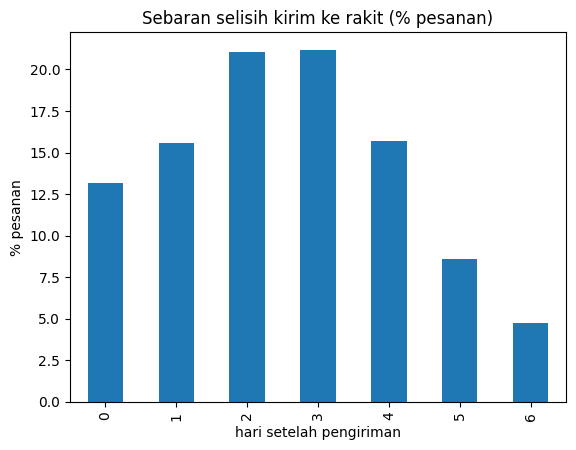

In [58]:
dist = v['gap_hari'].round().astype(int).value_counts().sort_index()
(dist / dist.sum() * 100).plot(kind='bar', title='Sebaran selisih kirim ke rakit (% pesanan)')
plt.xlabel('hari setelah pengiriman')
plt.ylabel('% pesanan')
plt.show()

**Kesimpulan:** - Pada pesanan dengan jasa instalasi dan urutan tanggal yang valid, rata-rata jeda pengiriman ke instalasi adalah **2,55 hari** (median 3 hari).
- Hanya **28,8%** selesai dalam 24 jam; **50,2%** membutuhkan 3 hari atau lebih.
- Analisis segmen tidak menemukan kelompok toko, kategori, supplier, atau installer yang secara material lebih lambat. Temuan ini mendukung perbaikan jadwal secara menyeluruh, bukan hanya menargetkan satu kelompok.
- Rekomendasi: jadwalkan instalasi bersamaan dengan pengiriman dan ukur kepatuhan SLA maksimal 24 jam per order.

Pola waktu: Perakit datang rata-rata 2,55 hari setelah barang dikirim (median 3 hari, maksimum 6 hari). Hanya 13,2% pesanan dirakit di hari yang sama dan 28,8% dalam 24 jam, sedangkan 50,2% menunggu 3 hari atau lebih. Selisihnya selalu hari penuh, dan tidak berubah menurut hari pengiriman, bulan, maupun jam (2,53 sampai 2,57 hari).
Segmen: Tidak ada segmen yang jauh lebih lambat dari rata-rata. Menurut kategori produk, ukuran barang, channel, kota, tier toko, tier member, supplier, dan toko, selisih dari rata-rata paling besar hanya 0,06 hari (sekitar 1,4 jam), jauh di bawah ambang 0,5 hari. Perbedaan antar tukang juga tidak melebihi yang diharapkan dari kebetulan (uji acak: 0,153 untuk data nyata berbanding 0,152 untuk simulasi acak). Keterlambatan bersifat sistemik, bukan terkonsentrasi di segmen tertentu.
Implikasi: Perbaikan untuk goals Logistics Sync adalah aturan penjadwalan yang berlaku untuk semua pesanan, misalnya perakit dijadwalkan di hari pengiriman yang sama. Menargetkan satu kategori, toko, supplier, atau tukang tidak akan menyelesaikan masalahnya.

## 3.3 Kegagalan perakitan: siapkan data pesanan yang dirakit

**Apa yang dicari:** Berapa persen pesanan yang membutuhkan instalasi berakhir gagal (Missing Parts atau Damaged Panel).

**Metode:** Ambil hanya pesanan berstatus Success atau Failed, gabungkan dengan produk, supplier, toko, dan tukang. Tabel `d` (satu baris per pesanan yang dirakit) dipakai di bab-bab berikutnya.

In [59]:
from scipy.stats import chi2_contingency

d = (dfs['order']
     .merge(dfs['product'][['sku_id', 'category_clean', 'weight_category', 'unit_price', 'supplier_id']],
            on='sku_id', how='left')
     .merge(dfs['supplier'][['supplier_id', 'supplier_name', 'supplier_type', 'region',
                             'quality_certification_status']], on='supplier_id', how='left')
     .merge(dfs['store'][['store_id', 'city', 'channel_type']], on='store_id', how='left'))

dirakit = ['Success', 'Failed - Missing Parts', 'Failed - Damaged Panel']
d = d[d['installation_status'].isin(dirakit)].copy()

d['gagal_missing'] = d['installation_status'].eq('Failed - Missing Parts')
d['gagal_damaged'] = d['installation_status'].eq('Failed - Damaged Panel')
d['gagal'] = d['gagal_missing'] | d['gagal_damaged']

for k in ['supplier_id', 'supplier_name', 'supplier_type', 'region', 'quality_certification_status']:
    d[k] = d[k].fillna('Tanpa supplier')

d['wilayah_tukang'] = d['installer_id'].str.split('-').str[1]      # TUKANG-JKT-031 -> JKT
d['kuartil_harga'] = pd.qcut(d['unit_price'], 4, labels=False, duplicates='drop')  # 0 termurah, 3 termahal
d['bulan'] = d['delivery_date'].dt.to_period('M').astype(str)

print(len(d))                                   # harus 204.557
print(round(d['gagal'].mean() * 100, 2),        # harus 14,07
      round(d['gagal_missing'].mean() * 100, 2),  # harus 9,08
      round(d['gagal_damaged'].mean() * 100, 2))  # harus 4,99

204557
14.07 9.08 4.99


**Kesimpulan:** Failed Installation pada pesanan yang membutuhkan instalasi sekitar 14,1% (28.782 dari 204.557 pesanan), terdiri dari Missing Parts sekitar 9,1% dan Damaged Panel sekitar 5,0%. Angka ini menjadi baseline Bab 4 dan Bab 5, dengan target brief di bawah 8%.

## 3.4 Hubungan kegagalan dengan produk, supplier, dan tukang

**Apa yang dicari:** Kegagalan berhubungan dengan apa: karakteristik produk, supplier, atau tukang.

**Metode:** Ukuran kekuatan hubungan Cramér V dan uji chi-kuadrat untuk produk dan supplier. Untuk tukang dipakai simulasi acak: sebaran kegagalan antar tukang dibandingkan dengan sebaran jika kegagalan dibagi acak.

In [60]:
def hubungan(kolom, min_n=300):
    t = d.groupby(kolom).agg(n=('gagal', 'size'),
                             persen_gagal=('gagal', 'mean'),
                             persen_missing=('gagal_missing', 'mean'),
                             persen_damaged=('gagal_damaged', 'mean'))
    t[['persen_gagal', 'persen_missing', 'persen_damaged']] *= 100
    v = {}
    for y in ['gagal_missing', 'gagal_damaged']:
        tab = pd.crosstab(d[kolom], d[y])
        chi2, p, _, _ = chi2_contingency(tab)
        v[y] = round(np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))), 3)
    return t[t['n'] >= min_n].sort_values('persen_gagal', ascending=False).round(2), v

for k in ['category_clean', 'weight_category', 'kuartil_harga', 'supplier_type',
          'region', 'quality_certification_status', 'supplier_id', 'wilayah_tukang']:
    tabel, v = hubungan(k)
    print(f'--- {k}   Cramér V -> missing: {v["gagal_missing"]}, damaged: {v["gagal_damaged"]}')
    print(tabel)

--- category_clean   Cramér V -> missing: 0.131, damaged: 0.003
                    n  persen_gagal  persen_missing  persen_damaged
category_clean                                                     
Meja            42476         20.97           16.04            4.93
Bed             14393         15.31           10.32            4.98
Lemari          63805         13.06            8.09            4.97
Sofa            23522         11.30            6.13            5.18
Kursi           60361         11.06            6.08            4.99
--- weight_category   Cramér V -> missing: 0.027, damaged: 0.003
                     n  persen_gagal  persen_missing  persen_damaged
weight_category                                                     
Sedang           67462         14.56            9.64            4.92
Bulky            76622         14.22            9.17            5.05
Oversized        47801         13.87            8.88            4.99
Ringan           12672         11.37            6.

In [61]:
rng = np.random.default_rng(42)

def sebaran_tukang(df, y):
    g = df.groupby('installer_id')[y].agg(['size', 'mean'])
    return g[g['size'] >= 30]['mean'].std()

for y in ['gagal_missing', 'gagal_damaged']:
    nyata = sebaran_tukang(d, y)
    acak = [sebaran_tukang(d.assign(**{y: rng.permutation(d[y].values)}), y) for _ in range(100)]
    print(f'{y}: nyata {nyata:.4f} | acak rata-rata {np.mean(acak):.4f} | acak maks {np.max(acak):.4f}')

gagal_missing: nyata 0.0260 | acak rata-rata 0.0260 | acak maks 0.0271
gagal_damaged: nyata 0.0203 | acak rata-rata 0.0198 | acak maks 0.0207


**Kesimpulan:** ya, berhubungan dengan pemasok, tidak dengan tukang, dan hubungan dengan produk hanya tampak karena tercampur dengan pemasok. Hubungan pemasok itu konsisten di semua kondisi yang diuji.
Berhubungan dengan apa?
Pemasok: hubungan terkuat untuk Missing Parts (Cramér V 0,284). Dua pemasok menonjol, UMKM Furnitur Ciputat (31,8%) dan Mebel Rakyat Klaten (31,0%), sedangkan 27 pemasok lain sekitar 5,5% sampai 6,8%. Keduanya hanya 11,8% pesanan yang dirakit, tapi menyumbang 40,9% kasus Missing Parts.
Produk: kategori berhubungan sedang (V 0,131, Meja tertinggi di 16,0%), sedangkan ukuran barang (0,027) dan kuartil harga (0,083) lemah. Hubungan ini tampak karena tercampur dengan pemasok (lihat bagian kombinasi).
Tukang: tidak berhubungan. Sebaran antar tukang sama dengan sebaran acak (Missing Parts 0,0260 berbanding 0,0260, Damaged Panel 0,0203 berbanding 0,0198).
Damaged Panel hampir sama di semua kelompok (sekitar 5%, V di bawah 0,011), jadi tidak terkait karakteristik produk, pemasok, maupun tukang.
Konsisten di semua kondisi? Untuk dua pemasok itu, ya. Selisih Missing Parts mereka dibanding pemasok lain berkisar 24 sampai 27 poin di semua bulan, kota, channel, dan wilayah tukang. Pengecualiannya Januari 2024 (21,8 poin) yang pesanannya sedikit. Tingkat gagalnya tetap sekitar 31% di kategori apa pun yang mereka pasok (Bed 32,0%, Meja 31,8% dan 31,7%, Lemari 30,0%).

## 3.5 Performa supplier dibanding harapannya

**Apa yang dicari:** Apakah ada supplier yang Missing Parts-nya jauh di atas harapan setelah memperhitungkan kategori yang dipasoknya, dan apakah polanya konsisten di semua kondisi.

**Metode:** Bandingkan Missing Parts aktual dengan harapan per kategori (rasio aktual per harapan). Supplier dengan rasio lebih dari 2 dan minimal 300 pesanan ditandai `supplier_berisiko`. Pola diuji konsisten per bulan, kota, channel, dan wilayah tukang. Lalu hitung potensi penurunan jika supplier berisiko setara supplier lain.

In [62]:
# a. Supplier dibandingkan dengan harapannya, dengan memperhitungkan kategori yang dipasoknya
d['exp_missing'] = d['category_clean'].map(d.groupby('category_clean')['gagal_missing'].mean())
s = (d.groupby(['supplier_id', 'supplier_name'])
       .agg(n=('gagal', 'size'), missing=('gagal_missing', 'sum'), expected=('exp_missing', 'sum')))
s['persen_missing'] = (s['missing'] / s['n'] * 100).round(2)
s['rasio_obs_vs_exp'] = (s['missing'] / s['expected']).round(2)
print(s[s['n'] >= 300].sort_values('rasio_obs_vs_exp', ascending=False).head(10))

# b. Missing Parts per supplier x kategori (sel dengan kurang dari 100 pesanan dikosongkan)
pv = pd.pivot_table(d, index='supplier_id', columns='category_clean', values='gagal_missing', aggfunc='mean') * 100
nn = pd.pivot_table(d, index='supplier_id', columns='category_clean', values='gagal_missing', aggfunc='size')
print(pv.where(nn >= 100).round(1))

# c. Kategori x ukuran barang
pv2 = pd.pivot_table(d, index='category_clean', columns='weight_category', values='gagal_missing', aggfunc='mean') * 100
nn2 = pd.pivot_table(d, index='category_clean', columns='weight_category', values='gagal_missing', aggfunc='size')
print(pv2.where(nn2 >= 100).round(1))

# d. Apakah pola yang sama muncul di semua kondisi?
berisiko = s[(s['n'] >= 300) & (s['rasio_obs_vs_exp'] > 2)].index.get_level_values('supplier_id')
d['supplier_berisiko'] = d['supplier_id'].isin(berisiko)
print('supplier berisiko:', list(berisiko))

def konsistensi(mask, nama, kondisi, y='gagal_missing'):
    t = d.assign(grup=np.where(mask, nama, 'lainnya')).groupby([kondisi, 'grup'])[y].mean().unstack() * 100
    t['selisih'] = t[nama] - t['lainnya']
    return t.round(2)

for kondisi in ['bulan', 'city', 'channel_type', 'wilayah_tukang']:
    print(f'--- Meja vs lainnya per {kondisi}');            print(konsistensi(d['category_clean'].eq('Meja'), 'Meja', kondisi))
    print(f'--- supplier berisiko vs lainnya per {kondisi}'); print(konsistensi(d['supplier_berisiko'], 'berisiko', kondisi))

                                            n  missing     expected  \
supplier_id    supplier_name                                          
SUP-PRJ-KLT-05 Mebel Rakyat Klaten      12564     3888  1583.967744   
SUP-PRJ-KLT-04 UMKM Furnitur Ciputat    11657     3706  1734.520303   
SUP-PBR-SMG-02 Cahaya Mebel Industri     7146      433   437.776805   
SUP-PBR-SDA-02 Sinar Mebel Nusantara    18906     1117  1148.874406   
SUP-PBR-SDA-03 Karunia Wood Industries  20285     1237  1273.426397   
SUP-PBR-BKS-05 Sumber Kayu Jaya         21773     1360  1414.753888   
SUP-PRJ-KLT-02 Perajin Kayu Solo        10874      669   715.891679   
SUP-PRJ-CRB-02 Perajin Mebel Yogya       5413      366   437.926589   
SUP-PRJ-KLT-01 Karya Perajin Jepara      5170      316   418.267220   
SUP-PRJ-SLO-03 Perajin Rotan Cirebon     7204      443   591.737826   

                                        persen_missing  rasio_obs_vs_exp  
supplier_id    supplier_name                                            

In [63]:
bersih = d[~d['supplier_berisiko']]
b = d[d['supplier_berisiko']]

for k in ['category_clean', 'weight_category', 'kuartil_harga', 'supplier_type', 'quality_certification_status']:
    print('---', k)
    print((bersih.groupby(k)['gagal_missing'].mean() * 100).round(2))

# Perkiraan dampak kalau dua pemasok itu setara pemasok lain
dasar = bersih['gagal_missing'].mean()
sekarang = int(d['gagal_missing'].sum())
setara = int(bersih['gagal_missing'].sum() + dasar * len(b))
print('Missing Parts sekarang  :', sekarang, f'({sekarang / len(d) * 100:.2f}%)')
print('kalau setara pemasok lain:', setara, f'({setara / len(d) * 100:.2f}%)')

--- category_clean
category_clean
Bed       6.07
Kursi     6.08
Lemari    6.05
Meja      6.15
Sofa      6.13
Name: gagal_missing, dtype: float64
--- weight_category
weight_category
Bulky        6.16
Oversized    5.95
Ringan       6.31
Sedang       6.05
Name: gagal_missing, dtype: float64
--- kuartil_harga
kuartil_harga
0    6.14
1    6.06
2    6.08
3    6.05
Name: gagal_missing, dtype: float64
--- supplier_type
supplier_type
Pabrik            6.04
Perajin Lokal     6.10
Tanpa supplier    6.52
Name: gagal_missing, dtype: float64
--- quality_certification_status
quality_certification_status
Belum Tersertifikasi    6.12
Tanpa supplier          6.52
Tersertifikasi          6.03
Name: gagal_missing, dtype: float64
Missing Parts sekarang  : 18570 (9.08%)
kalau setara pemasok lain: 12450 (6.09%)


**Kesimpulan:** Kegagalan Missing Parts berhubungan kuat dengan pemasok (Cramér V 0,284), terutama dua pemasok di Klaten, UMKM Furnitur Ciputat (31,8%) dan Mebel Rakyat Klaten (31,0%), dibanding sekitar 6% pada pemasok lain. Keduanya hanya 11,8% pesanan yang dirakit tetapi menyumbang 40,9% kasus Missing Parts, dan tingkat gagalnya konsisten di semua bulan, kota, channel, wilayah tukang, dan kategori yang mereka pasok. Kategori Meja (16%) tampak tinggi hanya karena banyak dipasok oleh dua pemasok ini. Tukang tidak berhubungan dengan kegagalan, dan Damaged Panel (sekitar 5%) tidak terkait karakteristik produk, pemasok, maupun tukang.

- Failed Installation pada pesanan yang memerlukan instalasi berada di sekitar **14,1%**, sesuai baseline pada brief.
- Masalah **Missing Parts** paling kuat terkait supplier; dua supplier berisiko menyumbang porsi kegagalan yang tidak proporsional. Kategori produk terlihat terkait sebagian karena komposisi supplier.
- **Damaged Panel** sekitar 5% dan tidak menunjukkan hubungan kuat dengan supplier, kategori, atau installer. Karena itu, perbaikan kualitas komponen dan perbaikan proteksi/pengiriman perlu ditangani sebagai dua workstream berbeda.
- Hubungan statistik bukan bukti sebab-akibat; supplier berisiko perlu diaudit dengan sampel produk dan pemeriksaan proses penerimaan/packing.

## 3.6 Damaged Panel: kelompok toko dan kombinasi yang menonjol

**Apa yang dicari:** Apakah Damaged Panel terkonsentrasi di toko, kategori, atau tukang tertentu, dan apakah toko yang tinggi konsisten tiap bulan.

**Metode:** Uji z untuk proporsi Damaged Panel tiap kombinasi dibanding rata-rata, lalu cek per bulan toko yang menonjol (DEC Alam Sutera 24).

In [64]:
from scipy.stats import norm

d['store_name'] = d['store_id'].map(dfs['store'].set_index('store_id')['store_name'])
y = 'gagal_damaged'
dasar = d[y].mean()

def cari(kolom, min_n=300):
    g = d.groupby(kolom)[y].agg(n='size', rate='mean').reset_index()
    g = g[g['n'] >= min_n].copy()
    if g.empty:
        print(f'{kolom}: tidak ada kelompok dengan minimal {min_n} pesanan')
        return g
    g['rasio'] = (g['rate'] / dasar).round(2)
    g['z'] = (g['rate'] - dasar) / np.sqrt(dasar * (1 - dasar) / g['n'])
    batas = norm.isf(0.05 / (2 * len(g)))        # koreksi karena banyak kelompok diuji
    print(f'{kolom}: {len(g)} kelompok, ambang |z| > {batas:.1f}, lolos: {(g["z"].abs() > batas).sum()}')
    return g.sort_values('z', ascending=False)

for k in (['store_name'], ['store_name', 'category_clean'],
          ['wilayah_tukang', 'category_clean'], ['store_name', 'wilayah_tukang'],
          ['store_name', 'category_clean', 'wilayah_tukang']):
    print(cari(k).head(3), '\n')

['store_name']: 40 kelompok, ambang |z| > 3.2, lolos: 1
              store_name     n      rate  rasio         z
4     DEC Alam Sutera 24  5372  0.062547   1.25  4.248523
22  DEC Kelapa Gading 29  5536  0.054733   1.10  1.643343
17        DEC Bintaro 34  5537  0.054000   1.08  1.393286 

['store_name', 'category_clean']: 181 kelompok, ambang |z| > 3.6, lolos: 0
               store_name category_clean     n      rate  rasio         z
22     DEC Alam Sutera 24         Lemari  1683  0.065359   1.31  2.907878
23     DEC Alam Sutera 24           Meja  1098  0.064663   1.30  2.242776
102  DEC Kelapa Gading 14         Lemari  1676  0.061456   1.23  2.168024 

['wilayah_tukang', 'category_clean']: 20 kelompok, ambang |z| > 3.0, lolos: 0
   wilayah_tukang category_clean      n      rate  rasio         z
10            MDN            Bed    735  0.062585   1.25  1.576290
16            SBY          Kursi   4518  0.054892   1.10  1.533617
9             JKT           Sofa  19712  0.051694   1.04  

In [65]:
a24 = d[d['store_name'] == 'DEC Alam Sutera 24']
print(a24.groupby('order_sebelum_buka')['gagal_damaged'].agg(['size', 'mean']))

                    size      mean
order_sebelum_buka                
False               4486  0.061079
True                 886  0.069977


In [66]:
a24 = d[d['store_name'] == 'DEC Alam Sutera 24']
t = a24.groupby('bulan')['gagal_damaged'].agg(['size', 'mean'])
t['mean'] = (t['mean'] * 100).round(2)
print(t)

         size  mean
bulan              
2023-01   313  8.31
2023-02   347  5.48
2023-03   398  7.04
2023-04   492  6.50
2023-05   416  4.57
2023-06   523  4.97
2023-07   434  5.53
2023-08   381  6.82
2023-09   540  6.85
2023-10   387  6.46
2023-11   517  6.58
2023-12   537  6.52
2024-01    87  5.75


**Kesimpulan:** Damaged Panel (4,99%) tidak berhubungan dengan pemasok, kategori, atau wilayah tukang, dan tidak ada kombinasi toko, kategori, dan tukang yang menonjol. Satu toko, DEC Alam Sutera 24, konsisten sedikit lebih tinggi (6,25%, di atas rata-rata pada 10 dari 12 bulan di 2023, sekitar 68 kasus berlebih atau 0,7% dari seluruh kasus Damaged Panel). Efeknya kecil, jadi toko ini direkomendasikan untuk dipantau dan diaudit proses penanganannya, bukan sebagai prioritas utama. Secara keseluruhan kerusakan panel tersebar merata, sehingga sumbernya kemungkinan di rantai pengiriman umum.

## 3.7 Kontribusi penjualan channel dan toko

**Apa yang dicari:** Seberapa besar kontribusi tiap channel dan toko, dan apakah perbedaannya dijelaskan komposisi pelanggan.

**Metode:** Gunakan `unit_price` sebagai estimasi nilai barang (satu unit per pesanan). Bandingkan kontribusi per channel, tier, dan toko, lalu uji profil pelanggan dengan Cramér V dan rasio aktual terhadap harapan.

In [67]:
s = (dfs['order']
     .merge(dfs['product'][['sku_id', 'unit_price']], on='sku_id', how='left')
     .merge(dfs['store'][['store_id', 'store_name', 'channel_type', 'city', 'store_tier', 'opening_date']],
            on='store_id', how='left')
     .merge(dfs['customer'][['customer_id', 'age_group', 'membership_tier', 'domicile_city',
                             'registration_channel', 'registration_date']], on='customer_id', how='left'))

s['penjualan'] = s['unit_price']
s['registration_channel'] = s['registration_channel'].fillna('Tidak diketahui')

# Lokal: pelanggan tinggal di kota toko (hanya bermakna untuk toko fisik)
s['pelanggan_lokal'] = (s['domicile_city'] == s['city']).where(s['channel_type'] == 'Physical Store')

# Pelanggan baru: memesan dalam 30 hari sejak mendaftar (abaikan yang urutannya terbalik)
hari = (s['order_date'].dt.normalize() - s['registration_date'].dt.normalize()).dt.days
s['baru'] = (hari.between(0, 30)).where(hari >= 0)

print(len(s), f"{s['penjualan'].sum():,.0f}")         # 321.760 baris
print(s['penjualan'].describe())
print('unit_price kosong atau <= 0:', (~(s['penjualan'] > 0)).sum())

321760 702,149,585,145
count    3.217600e+05
mean     2.182215e+06
std      1.262537e+06
min      1.605010e+05
25%      1.149741e+06
50%      2.068405e+06
75%      3.217828e+06
max      5.494205e+06
Name: penjualan, dtype: float64
unit_price kosong atau <= 0: 0


In [68]:
s2 = s[~s['order_sebelum_buka']]
t = s2.groupby('store_name').agg(pesanan=('order_id', 'size'), penjualan=('penjualan', 'sum'))
buka = s.groupby('store_name')['opening_date'].first().clip(lower=pd.Timestamp('2023-01-01'))
t['bulan_aktif'] = ((pd.Timestamp('2023-12-31') - buka).dt.days / 30.4).clip(lower=1).round(1)
t['penjualan_per_bulan_aktif'] = (t['penjualan'] / t['bulan_aktif']).round(0)
print(t.sort_values('penjualan_per_bulan_aktif', ascending=False))

                      pesanan    penjualan  bulan_aktif  \
store_name                                                
Dekoruma Mobile App     20986  45843779427         12.0   
Dekoruma Website        20773  44891398086         12.0   
DEC Kelapa Gading 14     3302   7286098771          4.0   
DEC Kelapa Gading 29     2630   5774316870          3.3   
DEC Alam Sutera 22       3926   8617660571          5.0   
DEC Alam Sutera 24       7161  15581676631          9.6   
DEC Kelapa Gading 4      5447  11838629259          7.3   
DEC Alam Sutera 18       8824  19198852821         12.0   
DEC Bekasi 25            8761  19193571268         12.0   
DEC Kelapa Gading 11     8797  19111405536         12.0   
DEC Bintaro 34           8655  19106596340         12.0   
DEC Bintaro 31           8621  18940330140         12.0   
DEC Kemang 3             8567  18937666399         12.0   
DEC Bintaro 38           8606  18930922771         12.0   
DEC Bintaro 12           8686  18918538896         12.0 

In [69]:
f = s[(s['channel_type'] == 'Physical Store') & s['domicile_city'].notna()]
print(round((f['domicile_city'] == f['city']).mean() * 100, 1))   # kira-kira 64%

60.3


In [70]:
def kontribusi(df, kolom):
    g = df.groupby(kolom).agg(pesanan=('order_id', 'size'), penjualan=('penjualan', 'sum'),
                              pelanggan=('customer_id', 'nunique'))
    g['persen_penjualan'] = (g['penjualan'] / g['penjualan'].sum() * 100).round(2)
    g['rata2_per_pesanan'] = (g['penjualan'] / g['pesanan']).round(0)
    g['penjualan_per_pelanggan'] = (g['penjualan'] / g['pelanggan']).round(0)
    return g.sort_values('penjualan', ascending=False)

print(kontribusi(s, 'channel_type'))
print(kontribusi(s, 'store_tier'))

toko = kontribusi(s, 'store_name')
toko['persen_kumulatif'] = toko['persen_penjualan'].cumsum().round(1)

# Toko dibuka di waktu berbeda: bandingkan per bulan aktif
buka = s.groupby('store_name')['opening_date'].first().clip(lower=pd.Timestamp('2023-01-01'))
toko['bulan_aktif'] = (((pd.Timestamp('2023-12-31') - buka).dt.days / 30.4).clip(lower=1)).round(1)
toko['penjualan_per_bulan_aktif'] = (toko['penjualan'] / toko['bulan_aktif']).round(0)
print(toko)

# Sensitivitas: tanpa pesanan yang tercatat sebelum toko buka (25.344 baris)
print(kontribusi(s[~s['order_sebelum_buka']], 'channel_type')[['pesanan', 'persen_penjualan']])

                pesanan     penjualan  pelanggan  persen_penjualan  \
channel_type                                                         
Physical Store   280001  611414407632     125851             87.08   
Mobile App        20986   45843779427      18785              6.53   
Web               20773   44891398086      18690              6.39   

                rata2_per_pesanan  penjualan_per_pelanggan  
channel_type                                                
Physical Store          2183615.0                4858240.0  
Mobile App              2184493.0                2440446.0  
Web                     2161045.0                2401894.0  
            pesanan     penjualan  pelanggan  persen_penjualan  \
store_tier                                                       
Standard     178970  390848757280      96244             63.93   
Mini          67298  146864414546      48567             24.02   
Flagship      33733   73701235806      26919             12.05   

            r

In [71]:
from scipy.stats import chi2_contingency

for p in ['membership_tier', 'age_group', 'registration_channel']:
    print('---', p, '(% pesanan per channel)')
    print((pd.crosstab(s['channel_type'], s[p], normalize='index') * 100).round(1))

print('--- % penjualan per tier member di tiap channel')
print((pd.pivot_table(s, index='channel_type', columns='membership_tier', values='penjualan',
                      aggfunc='sum').pipe(lambda t: t.div(t.sum(axis=1), axis=0)) * 100).round(1))

profil = s.groupby('store_name').agg(
    persen_plus=('membership_tier', lambda x: (x == 'Dekoruma Plus').mean() * 100),
    persen_lokal=('pelanggan_lokal', lambda x: x.mean() * 100),
    persen_baru=('baru', lambda x: x.mean() * 100)).round(1)
print(profil.describe().round(1))      # lihat min dan max antar toko

# Seberapa kuat toko atau channel berhubungan dengan profil (Cramér V)
def cramer(a, b):
    tab = pd.crosstab(a, b)
    return np.sqrt(chi2_contingency(tab)[0] / (tab.values.sum() * (min(tab.shape) - 1)))

for p in ['membership_tier', 'age_group', 'registration_channel', 'domicile_city']:
    kol = s[p].fillna('Kosong')
    print(f'{p:22} channel: {cramer(s["channel_type"], kol):.3f}   toko: {cramer(s["store_name"], kol):.3f}')

# Omnichannel: berapa persen pelanggan memakai lebih dari satu channel
print((s.groupby('customer_id')['channel_type'].nunique().value_counts(normalize=True) * 100).round(1))

--- membership_tier (% pesanan per channel)
membership_tier  Dekoruma Plus  Regular
channel_type                           
Mobile App                14.2     85.8
Physical Store            13.8     86.2
Web                       13.7     86.3
--- age_group (% pesanan per channel)
age_group       18-24  25-34  35-44  45-54  55+
channel_type                                   
Mobile App       11.4   33.8   29.3   16.3  9.1
Physical Store   12.0   33.9   28.9   16.2  9.0
Web              12.5   33.7   29.0   15.9  8.9
--- registration_channel (% pesanan per channel)
registration_channel  Mobile App  Physical Store  Tidak diketahui   Web
channel_type                                                           
Mobile App                  12.9            23.8             52.6  10.6
Physical Store              13.1            23.4             53.1  10.4
Web                         12.9            23.7             53.0  10.4
--- % penjualan per tier member di tiap channel
membership_tier  Deko

In [72]:
s['segmen'] = s['age_group'].astype(str) + ' | ' + s['membership_tier'].astype(str)
aov_segmen = s.groupby('segmen')['penjualan'].mean()
print(aov_segmen.describe().round(0))            # seberapa beda nilai pesanan antar segmen

s['harapan'] = s['segmen'].map(aov_segmen)
cek = s.groupby('store_name').agg(aktual=('penjualan', 'mean'), harapan=('harapan', 'mean'))
cek['rasio'] = (cek['aktual'] / cek['harapan']).round(3)
print(cek.sort_values('rasio'))

count         10.0
mean     2184242.0
std        10848.0
min      2172254.0
25%      2177303.0
50%      2182410.0
75%      2183905.0
max      2203982.0
Name: penjualan, dtype: float64
                            aktual       harapan  rasio
store_name                                             
DEC Bandung 8         2.142197e+06  2.182336e+06  0.982
Dekoruma Website      2.161045e+06  2.182179e+06  0.990
DEC Kelapa Gading 9   2.161898e+06  2.182178e+06  0.991
DEC Surabaya 13       2.163929e+06  2.182311e+06  0.992
DEC Medan 17          2.166677e+06  2.182108e+06  0.993
DEC Alam Sutera 24    2.168178e+06  2.182251e+06  0.994
DEC Kemang 6          2.170611e+06  2.182304e+06  0.995
DEC Kelapa Gading 37  2.170433e+06  2.182247e+06  0.995
DEC Medan 5           2.170719e+06  2.181963e+06  0.995
DEC Surabaya 20       2.171297e+06  2.182231e+06  0.995
DEC Bekasi 15         2.174389e+06  2.182225e+06  0.996
DEC Alam Sutera 36    2.173926e+06  2.182231e+06  0.996
DEC Kelapa Gading 11  2.172491e+

**Kesimpulan:** Dari total penjualan Rp 702,1 miliar (harga satuan produk, satu unit per pesanan), toko fisik menyumbang 87,1%, Mobile App 6,5%, dan Website 6,4%. Di antara 38 DEC, 28 DEC Jabodetabek masing-masing menyumbang 2,6% sampai 2,7% (Rp 18,3 sampai 19,2 miliar), sekitar 2,2 kali DEC di Medan, Surabaya, dan Bandung (1,2%). Profil pelanggan hampir identik di semua channel dan toko (Cramér V paling besar 0,013 untuk tier member, usia, dan kanal registrasi), dan nilai pesanan tidak berbeda antar segmen (Rp 2,18 juta ± 0,5%; rasio aktual terhadap harapan per toko 0,98 sampai 1,02). Perbedaan kontribusi karena volume pesanan menurut lokasi, bukan komposisi pelanggan. Pelanggan toko fisik lebih sering membeli (2,2 pesanan per pelanggan, dibanding 1,1 di App dan Web), dan 19,3% pelanggan memakai lebih dari satu channel. Setelah 25.344 pesanan sebelum toko buka dikeluarkan, kontribusi fisik 86,0%, App 7,1%, dan Web 6,9%, jadi kesimpulannya tidak berubah. Dari pelanggan dengan domisili terisi, 60,3% pesanan DEC datang dari kota yang sama dengan toko.

- Berdasarkan `unit_price` per order, estimasi nilai penjualan tercatat sekitar **Rp702,1 miliar**: Physical Store 87,1%, Mobile App 6,5%, dan Web 6,4%.
- Profil pelanggan antar-channel relatif mirip; variasi kontribusi lebih banyak tampak terkait volume transaksi dan cakupan toko daripada komposisi usia/member.
- Angka ini adalah estimasi nilai barang dari data yang tersedia, bukan net sales atau margin. Pastikan dashboard menamai metrik sebagai *estimated merchandise value*.

## 3.8 Indikasi showrooming: pembelian online setelah membeli di toko fisik

**Apa yang dicari:** Berapa bagian penjualan online yang terkait dengan toko fisik (DEC), dan apakah proporsinya berbeda antar toko.

**Metode:** Tiga proxy (daftar di toko, pernah beli fisik, tinggal di kota DEC), lalu `merge_asof` untuk menautkan tiap pesanan online ke pembelian fisik terakhir pelanggan yang sama dalam jendela 7, 30, 90, 180, dan 365 hari. Uji chi-kuadrat dipakai untuk membandingkan DEC baru dan DEC mapan. Variabel sementara `s` pada langkah ini diganti `s_kredit` agar tidak menimpa tabel penjualan `s` yang dipakai grafik channel di Bab 6.

In [73]:
o = (dfs['order']
     .merge(dfs['store'][['store_id', 'channel_type']], on='store_id', how='left')
     .merge(dfs['customer'][['customer_id', 'domicile_city', 'registration_channel', 'acquisition_channel']],
            on='customer_id', how='left')
     .merge(dfs['product'][['sku_id', 'unit_price']], on='sku_id', how='left'))
o['penjualan'] = o['unit_price']

online = o[o['channel_type'].isin(['Mobile App', 'Web'])].copy()
online['p_daftar_toko'] = (online['registration_channel'] == 'Physical Store') | (online['acquisition_channel'] == 'Walk-in')

fisik_pertama = o[o['channel_type'] == 'Physical Store'].groupby('customer_id')['order_date'].min()
online['p_pernah_fisik'] = online['customer_id'].map(fisik_pertama) < online['order_date']

kota_dec = set(dfs['store'].loc[dfs['store']['channel_type'] == 'Physical Store', 'city'].dropna())
online['p_kota_dec'] = online['domicile_city'].isin(kota_dec)

for k in ['p_daftar_toko', 'p_pernah_fisik', 'p_kota_dec']:
    rp = online.loc[online[k], 'penjualan'].sum()
    print(f'{k:16} {rp / online["penjualan"].sum() * 100:5.1f}% dari penjualan online')

ketat = online['p_daftar_toko'] | online['p_pernah_fisik']
luas = ketat | online['p_kota_dec']
for nama, m in [('ketat', ketat), ('luas', luas)]:
    rp = online.loc[m, 'penjualan'].sum()
    print(f'{nama}: {m.mean() * 100:.1f}% pesanan online, Rp {rp / 1e9:.1f} miliar = {rp / o["penjualan"].sum() * 100:.1f}% dari total penjualan')

p_daftar_toko     23.6% dari penjualan online
p_pernah_fisik    54.4% dari penjualan online
p_kota_dec        88.8% dari penjualan online
ketat: 67.5% pesanan online, Rp 61.1 miliar = 8.7% dari total penjualan
luas: 94.3% pesanan online, Rp 85.5 miliar = 12.2% dari total penjualan


In [74]:
o = (dfs['order']
     .merge(dfs['store'][['store_id', 'store_name', 'channel_type']], on='store_id', how='left')
     .merge(dfs['customer'][['customer_id', 'domicile_city', 'registration_channel', 'acquisition_channel']],
            on='customer_id', how='left')
     .merge(dfs['product'][['sku_id', 'unit_price']], on='sku_id', how='left'))
o['penjualan'] = o['unit_price']

online = o[o['channel_type'].isin(['Mobile App', 'Web'])].copy()
print('pesanan online:', len(online), '| penjualan online: Rp', round(online['penjualan'].sum() / 1e9, 1), 'miliar')
# harus 41.759 pesanan dan sekitar Rp 90,7 miliar

# Proxy a: pelanggan mendaftar lewat toko, atau berasal dari walk-in
online['p_daftar_toko'] = (online['registration_channel'] == 'Physical Store') | (online['acquisition_channel'] == 'Walk-in')

# Proxy b: pelanggan sudah pernah membeli di toko fisik sebelum pesanan online ini
fisik_pertama = o[o['channel_type'] == 'Physical Store'].groupby('customer_id')['order_date'].min()
online['p_pernah_fisik'] = online['customer_id'].map(fisik_pertama) < online['order_date']

# Proxy c: pelanggan tinggal di kota yang punya DEC
kota_dec = set(dfs['store'].loc[dfs['store']['channel_type'] == 'Physical Store', 'city'].dropna())
online['p_kota_dec'] = online['domicile_city'].isin(kota_dec)

for k in ['p_daftar_toko', 'p_pernah_fisik', 'p_kota_dec']:
    rp = online.loc[online[k], 'penjualan'].sum()
    print(f'{k:16} {online[k].mean() * 100:5.1f}% pesanan | {rp / online["penjualan"].sum() * 100:5.1f}% penjualan online')

ketat = online['p_daftar_toko'] | online['p_pernah_fisik']
luas = ketat | online['p_kota_dec']
total = o['penjualan'].sum()
for nama, m in [('ketat (daftar di toko atau pernah beli di toko)', ketat),
                ('luas  (ditambah tinggal di kota DEC)', luas)]:
    rp = online.loc[m, 'penjualan'].sum()
    print(f'{nama}: {m.mean() * 100:.1f}% pesanan online, Rp {rp / 1e9:.1f} miliar = {rp / total * 100:.1f}% dari total penjualan')

print('kontribusi DEC yang tercatat sekarang:', round(o.loc[o['channel_type'] == 'Physical Store', 'penjualan'].sum() / total * 100, 1), '%')

pesanan online: 41759 | penjualan online: Rp 90.7 miliar
p_daftar_toko     23.8% pesanan |  23.6% penjualan online
p_pernah_fisik    54.4% pesanan |  54.4% penjualan online
p_kota_dec        88.7% pesanan |  88.8% penjualan online
ketat (daftar di toko atau pernah beli di toko): 67.5% pesanan online, Rp 61.1 miliar = 8.7% dari total penjualan
luas  (ditambah tinggal di kota DEC): 94.3% pesanan online, Rp 85.5 miliar = 12.2% dari total penjualan
kontribusi DEC yang tercatat sekarang: 87.1 %


In [75]:
# 1. Tautkan tiap pesanan online ke pembelian fisik terakhir pelanggan yang sama
nama = dfs['store'].set_index('store_id')['store_name']

# Gabungkan channel_type, store_name, DAN penjualan (unit_price) ke tabel order 'o' terlebih dahulu
o = (dfs['order']
     .merge(dfs['store'][['store_id', 'channel_type', 'store_name']], on='store_id', how='left')
     .merge(dfs['product'][['sku_id', 'unit_price']], on='sku_id', how='left')
     .rename(columns={'unit_price': 'penjualan'}))

fisik = (o[(o['channel_type'] == 'Physical Store') & ~o['order_sebelum_buka']]   # abaikan pesanan sebelum toko buka
         [['customer_id', 'order_date', 'store_id']]
         .rename(columns={'order_date': 'tgl_fisik', 'store_id': 'dec_id'})
         .sort_values('tgl_fisik'))

a = pd.merge_asof(online.sort_values('order_date'), fisik,
                  left_on='order_date', right_on='tgl_fisik',
                  by='customer_id', direction='backward')
a['hari_sejak_fisik'] = (a['order_date'] - a['tgl_fisik']).dt.days
a['dec'] = a['dec_id'].map(nama)

# 2. Seberapa banyak yang bisa ditautkan, dan seberapa lama jaraknya
print('pesanan online total               :', len(a))
print('  punya pembelian fisik sebelumnya :', a['dec_id'].notna().sum(),
      f"({a['dec_id'].notna().mean() * 100:.1f}%)")
print(a['hari_sejak_fisik'].describe().round(1))

for h in (7, 30, 90, 180, 365):
    m = a['hari_sejak_fisik'] <= h
    print(f'<= {h:3} hari: {m.sum():>6,} pesanan ({m.mean() * 100:4.1f}%), Rp {a.loc[m, "penjualan"].sum() / 1e9:5.1f} miliar')

# 3. Kredit per DEC
HARI = 30
s_kredit = a[a['hari_sejak_fisik'].between(0, HARI, inclusive='both')].copy()

kredit = s_kredit.groupby('dec').agg(pesanan_online=('order_id', 'size'),
                              penjualan_online=('penjualan', 'sum'))
kredit['penjualan_fisik'] = o[o['channel_type'] == 'Physical Store'].groupby('store_name')['penjualan'].sum()
kredit['tambahan_%'] = (kredit['penjualan_online'] / kredit['penjualan_fisik'] * 100).round(1)
kredit['porsi_kredit_%'] = (kredit['penjualan_online'] / kredit['penjualan_online'].sum() * 100).round(1)

print(kredit.sort_values('tambahan_%', ascending=False).head(10))
print(kredit.sort_values('tambahan_%').head(5))
print('total kredit: Rp', round(kredit['penjualan_online'].sum() / 1e9, 1), 'miliar,',
      f"{kredit['penjualan_online'].sum() / o['penjualan'].sum() * 100:.1f}% dari total penjualan")

pesanan online total               : 41759
  punya pembelian fisik sebelumnya : 21532 (51.6%)
count    21532.0
mean        55.7
std         57.4
min          0.0
25%         13.0
50%         36.0
75%         80.0
max        339.0
Name: hari_sejak_fisik, dtype: float64
<=   7 hari:  3,748 pesanan ( 9.0%), Rp   8.2 miliar
<=  30 hari:  9,741 pesanan (23.3%), Rp  21.1 miliar
<=  90 hari: 16,949 pesanan (40.6%), Rp  36.8 miliar
<= 180 hari: 20,530 pesanan (49.2%), Rp  44.6 miliar
<= 365 hari: 21,532 pesanan (51.6%), Rp  46.8 miliar
                      pesanan_online  penjualan_online  penjualan_fisik  \
dec                                                                       
DEC Bandung 8                    205         446406408       8478814783   
DEC Medan 5                      184         411653243       8309510939   
DEC Bandung 26                   184         405525231       8300349057   
DEC Kelapa Gading 11             395         862712599      19111405536   
DEC Medan 17    

In [76]:
baru = ['DEC Surabaya 28', 'DEC Kelapa Gading 29', 'DEC Alam Sutera 22', 'DEC Kelapa Gading 14',
        'DEC Kelapa Gading 4', 'DEC Alam Sutera 24', 'DEC Surabaya 35', 'DEC Kelapa Gading 37']
mapan = kredit.drop(index=baru, errors='ignore')
print(len(mapan)); print(mapan['tambahan_%'].describe().round(1))

30
count    30.0
mean      4.1
std       0.4
min       3.4
25%       3.8
50%       4.0
75%       4.2
max       5.3
Name: tambahan_%, dtype: float64


In [77]:
from scipy.stats import chi2 as khi

fisik_n = (o[(o['channel_type'] == 'Physical Store') & ~o['order_sebelum_buka']]
           .groupby('store_name').size())
tab = pd.DataFrame({'kredit': mapan['pesanan_online'], 'fisik': fisik_n}).loc[mapan.index]

p = tab['kredit'].sum() / tab['fisik'].sum()
harapan = p * tab['fisik']
stat = ((tab['kredit'] - harapan) ** 2 / harapan).sum()
print(f'rasio kredit per pesanan fisik: {p * 100:.2f}%')
p_value = khi.sf(stat, len(tab) - 1)
print(f'chi-square {stat:.1f}, derajat bebas {len(tab) - 1}, p-value {p_value:.4g}')

rasio kredit per pesanan fisik: 4.02%
chi-square 63.1, derajat bebas 29, p-value 0.000247


**Kesimpulan:** Proxy ini hanya indikasi, bukan bukti kunjungan showroom, karena dataset tidak punya event kunjungan DEC. Pesanan online yang punya pembelian fisik sebelumnya dalam jendela 30 hari dipakai sebagai proxy atribusi (tabel `kredit`), dan angkanya dilaporkan sebagai estimasi, bukan atribusi kausal. Rekomendasi: tambahkan customer ID atau QR check-in di DEC supaya atribusi bisa diverifikasi.

## 3.9 Standarisasi kategori produk dengan kamus alias

**Apa yang dicari:** Standar apa yang bisa diusulkan untuk membersihkan penamaan kategori produk, dan apakah penulisan tidak baku terkonsentrasi di supplier tertentu.

**Metode:** Buat kamus alias (misalnya `wardrobe` dan `lmri` menjadi Lemari), terapkan ke kolom kategori, periksa 15 sampel acak secara manual, lalu hitung proporsi penulisan tidak baku per supplier.

In [78]:
ALIAS = {'wardrobe': 'Lemari', 'lmri': 'Lemari', 'office chair': 'Kursi Kerja',
         'dining table': 'Meja Makan', 'sofabed': 'Sofa Bed'}

p = dfs['product']
p['category_raw'] = p['category']                         # simpan aslinya
p['category_std'] = (p['category'].str.strip().str.lower()
                     .map(ALIAS).fillna(p['category'].str.strip().str.title()))

# Setiap label harus masuk tepat satu family
print(p.groupby('category_std')['product_family'].nunique().max())   # harus 1
print(p[~p['category_std'].isin(set(ALIAS.values()) | set(p['product_family']))])  # label yatim

1
Empty DataFrame
Columns: [sku_id, product_name, category, is_assembly_required, supplier_id, unit_price, product_family, weight_category, category_norm, category_clean, category_raw, category_std]
Index: []


In [79]:
print(p['category_std'].value_counts())      # 7 label, total 1.500
print(p['category_raw'].nunique(), '->', p['category_std'].nunique())   # 11 -> 7

category_std
Lemari         348
Kursi Kerja    330
Meja Makan     234
Dekorasi       215
Sofa           214
Sofa Bed        81
Bed             78
Name: count, dtype: int64
11 -> 7


In [80]:
print(p.sample(15, random_state=1)[['product_name', 'category_raw', 'category_std', 'product_family']])

                           product_name  category_raw category_std  \
91             Furnitur Kayu Olahan 776    Meja Makan   Meja Makan   
75             Furnitur Kayu Olahan 447      Wardrobe       Lemari   
1264           Furnitur Kayu Olahan 829    Meja Makan   Meja Makan   
330            Furnitur Kayu Olahan 824        Lemari       Lemari   
1349           Furnitur Kayu Olahan 830   Kursi Kerja  Kursi Kerja   
774            Furnitur Kayu Olahan 643   Kursi Kerja  Kursi Kerja   
1038  Hiasan Meja / Karpet Aesthetic 14      Dekorasi     Dekorasi   
1285           Furnitur Kayu Olahan 361    Meja Makan   Meja Makan   
1165  Hiasan Meja / Karpet Aesthetic 33      Dekorasi     Dekorasi   
335            Furnitur Kayu Olahan 516    Meja Makan   Meja Makan   
685          Sofa Japandi Minimalis 401       sofabed     Sofa Bed   
181            Furnitur Kayu Olahan 342  Office Chair  Kursi Kerja   
1220           Furnitur Kayu Olahan 765  Office Chair  Kursi Kerja   
101            Furni

In [81]:
p['tidak_baku'] = p['category_raw'].str.strip().str.lower().isin(ALIAS)
print(p['tidak_baku'].sum(), round(p['tidak_baku'].mean() * 100, 1))      # 520, 34,7

t = (p.groupby(p['supplier_id'].fillna('Tanpa supplier'))['tidak_baku']
       .agg(['size', 'sum', 'mean']))
t['mean'] = (t['mean'] * 100).round(1)
print(t.sort_values('mean', ascending=False))

520 34.7
                size  sum  mean
supplier_id                    
SUP-PRJ-SLO-02    28   19  67.9
SUP-PBR-SDA-05    30   20  66.7
SUP-PRJ-KLT-01    28   17  60.7
SUP-PRJ-CRB-02    30   18  60.0
SUP-PRJ-SLO-03    39   22  56.4
SUP-PBR-BKS-05   119   65  54.6
SUP-PBR-TNG-01    15    8  53.3
SUP-PRJ-SLO-01    34   17  50.0
SUP-PBR-SDA-03   112   55  49.1
SUP-PBR-SDA-02   102   48  47.1
SUP-PRJ-CRB-03    26   12  46.2
SUP-PRJ-TGL-01    35   16  45.7
SUP-PBR-SDA-04    26   11  42.3
SUP-PBR-BKS-02    30   12  40.0
SUP-PRJ-JPR-01    10    4  40.0
SUP-PRJ-KLT-05    68   26  38.2
SUP-PRJ-KLT-03    19    7  36.8
SUP-PBR-SDA-01    11    4  36.4
SUP-PBR-BKS-04     9    3  33.3
SUP-PRJ-KLT-02   109   36  33.0
SUP-PBR-SMG-02    91   28  30.8
SUP-PRJ-KLT-04    64   17  26.6
Tanpa supplier    58   14  24.1
SUP-PRJ-CRB-04   104   25  24.0
SUP-PBR-SMG-03    17    4  23.5
SUP-PRJ-CRB-05    27    6  22.2
SUP-PRJ-CRB-01    16    3  18.8
SUP-PBR-TNG-02    24    3  12.5
SUP-IMP-JKT-01    51    0   0.0

In [82]:
dfs['product'].to_csv(FOLDER + 'product_clean.csv', index=False)

**Kesimpulan:** - Kamus alias menurunkan variasi penamaan kategori dari **11 menjadi 7 label**.
- Sebanyak **520 SKU (34,7%)** teridentifikasi menggunakan penulisan alias/tidak baku; variasi tersebut perlu dicegah di input supplier dan proses onboarding SKU.
- Gunakan `product_family` sebagai referensi utama, simpan `category_raw` untuk audit, dan pelihara kamus alias yang disetujui pemilik katalog.

## 3.10 Validasi aturan bisnis pada order dan retur

**Apa yang dicari:** Aturan bisnis mana yang konsisten penuh sehingga aman dijadikan pagar permanen, dan mana yang sering dilanggar.

**Metode:** Hitung pelanggaran 15 aturan (urutan tanggal, kecocokan status dengan kolom lain, rentang fee dan refund). Aturan fee dan refund memakai kolom nilai asli (`_raw`) untuk mengukur kesalahan input, dan nilai pulihan untuk memastikan tidak ada pelanggaran tersisa.

In [83]:
o, r = dfs['order'], dfs['ret']
dirakit = o['installation_status'].isin(['Success', 'Failed - Missing Parts', 'Failed - Damaged Panel'])
tanpa = ~dirakit

mulai = (o['sku_id'].map(dfs['product'].set_index('sku_id')['supplier_id'])
           .map(dfs['supplier'].set_index('supplier_id')['partnership_start_date']))

aturan_order = {
    'kirim sebelum order'               : o['delivery_date'] < o['order_date'],
    'rakit sebelum kirim'               : o['installation_date'] < o['delivery_date'],
    'tanpa rakit, tgl rakit terisi'     : tanpa & o['installation_date'].notna(),
    'tanpa rakit, installer terisi'     : tanpa & o['installer_id'].notna(),
    'tanpa rakit, fee tidak nol'        : tanpa & (o['assembly_fee'] != 0),
    'dirakit, tgl rakit kosong'         : dirakit & o['installation_date'].isna(),
    'dirakit, installer kosong'         : dirakit & o['installer_id'].isna(),
    'fee negatif (nilai asli)'           : o['assembly_fee_raw'] < 0,
    'fee 99,9 juta (nilai asli)'         : o['assembly_fee_raw'] >= 99_900_000,
    'fee negatif / 99,9 juta setelah pulih': (o['assembly_fee'] < 0) | (o['assembly_fee'] >= 99_900_000),
    'order sebelum kemitraan pemasok'   : o['order_date'] < mulai,
}
print('--- order')
for nama, m in aturan_order.items():
    print(f'{nama:35} {int(m.sum()):>8,}')

rm = r.merge(o[['order_id', 'delivery_date', 'installation_date']], on='order_id', how='left')
aturan_ret = {
    'retur sebelum kirim'               : rm['return_request_date'] < rm['delivery_date'],
    'Ditolak, refund tidak nol'         : (r['resolution_status'] == 'Ditolak') & (r['refund_amount'] != 0),
    'Diproses, refund terisi'           : (r['resolution_status'] == 'Diproses') & r['refund_amount'].notna(),
    'Selesai, refund kosong'            : (r['resolution_status'] == 'Selesai') & r['refund_amount'].isna(),
    'refund negatif (nilai asli)'        : r['refund_amount_raw'] < 0,
    'refund >= 99,9 juta (nilai asli)'   : r['refund_amount_raw'] >= 99_900_000,
    'refund negatif / >= 99,9 juta setelah pulih': (r['refund_amount'] < 0) | (r['refund_amount'] >= 99_900_000),
}
print('--- retur')
for nama, m in aturan_ret.items():
    print(f'{nama:35} {int(m.sum()):>8,}')

print(o[['order_date', 'delivery_date', 'installation_date']].max())   # cek tanggal di masa depan

--- order
kirim sebelum order                        0
rakit sebelum kirim                    5,586
tanpa rakit, tgl rakit terisi              0
tanpa rakit, installer terisi              0
tanpa rakit, fee tidak nol                 0
dirakit, tgl rakit kosong                  0
dirakit, installer kosong                  0
fee negatif (nilai asli)                 340
fee 99,9 juta (nilai asli)               354
fee negatif / 99,9 juta setelah pulih        0
order sebelum kemitraan pemasok       48,243
--- retur
retur sebelum kirim                       11
Ditolak, refund tidak nol                  0
Diproses, refund terisi                    0
Selesai, refund kosong                     0
refund negatif (nilai asli)               14
refund >= 99,9 juta (nilai asli)          46
refund negatif / >= 99,9 juta setelah pulih        0
order_date          2023-12-31 20:00:00
delivery_date       2024-01-07 20:00:00
installation_date   2024-01-13 18:00:00
dtype: datetime64[ns]


**Kesimpulan:** Aturan yang konsisten penuh (0 pelanggaran) aman dipasang sebagai pagar permanen: kirim tidak boleh sebelum order, kecocokan status perakitan dengan tanggal, installer, dan fee, serta kecocokan status retur dengan refund. Aturan yang mendeteksi kesalahan input nyata: perakitan sebelum pengiriman (5.586), fee negatif nilai asli (340), fee 99,9 juta nilai asli (354), retur sebelum kirim (11), refund negatif nilai asli (14), dan refund Rp99,9 juta ke atas nilai asli. Baris `setelah pulih` harus bernilai 0, itu bukti pemulihan di Bab 2 tuntas. Tanggal order terhadap kemitraan supplier (48.243 order, 15,0%) dan tanggal buka toko (25.344 order) terlalu sering dilanggar untuk dijadikan blokir, jadi perlu konfirmasi definisi kolom ke pemilik data.

# BAB 4 — Estimasi dampak bisnis (baseline)

## 4.1 Baseline Failed Installation dan target brief

**Apa yang dicari:** Berapa kegagalan yang harus dihindari agar Failed Installation turun ke target di bawah 8%.

**Metode:** Hitung jumlah pesanan instalasi, kegagalan saat ini, batas kegagalan pada target 8%, dan selisihnya.

In [84]:
# Gunakan tabel d dari analisis supplier (satu baris per order yang membutuhkan instalasi)
# Jika cell analisis sebelumnya belum dijalankan, jalankan ulang bagian Supplier Quality terlebih dahulu.

N_INSTALL = len(d)
N_FAILED = int(d['gagal'].sum())
BASE_RATE = d['gagal'].mean()
TARGET_RATE = 0.08

target_failures = int(np.floor(N_INSTALL * TARGET_RATE))
avoided_failures = max(N_FAILED - target_failures, 0)
rate_reduction_pp = (BASE_RATE - TARGET_RATE) * 100

impact_installation = pd.DataFrame({
    'Metric': [
        'Installation orders',
        'Current failed installations',
        'Current failure rate',
        'Target failure rate (brief)',
        'Maximum failures at 8% target',
        'Potential failures avoided'
    ],
    'Value': [
        f'{N_INSTALL:,.0f}',
        f'{N_FAILED:,.0f}',
        f'{BASE_RATE:.2%}',
        f'{TARGET_RATE:.2%}',
        f'{target_failures:,.0f}',
        f'{avoided_failures:,.0f}'
    ]
})
display(impact_installation)

print(f'Target reduction: {rate_reduction_pp:.2f} percentage points.')
print(f'Interpretation: jika volume order instalasi sama, sekitar {avoided_failures:,.0f} kegagalan lebih sedikit dibanding baseline.')

,Metric,Value
0,Installation orders,"204,557"
1,Current failed installations,"28,782"
2,Current failure rate,14.07%
3,Target failure rate (brief),8.00%
4,Maximum failures at 8% target,"16,364"
5,Potential failures avoided,"12,418"


Target reduction: 6.07 percentage points.
Interpretation: jika volume order instalasi sama, sekitar 12,418 kegagalan lebih sedikit dibanding baseline.


**Kesimpulan:** Dari baseline sekitar 14,1% (28.782 kegagalan dari 204.557 pesanan instalasi), target 8% berarti kegagalan maksimum sekitar 16.364 pesanan, sehingga dibutuhkan penurunan sekitar 6,1 poin persentase atau sekitar 12.400 kegagalan yang dihindari pada volume yang sama.

## 4.2 Estimasi nilai barang dan biaya proses retur yang bisa dihindari

**Apa yang dicari:** Berapa nilai barang yang terkait kegagalan yang dihindari, dan berapa biaya proses retur yang bisa dihemat.

**Metode:** Kegagalan yang dihindari dikalikan nilai barang rata-rata pesanan gagal. Biaya proses retur memakai benchmark brief sebesar 20% sampai 65% dari nilai barang, jadi hasilnya berupa rentang, bukan angka tunggal.

In [85]:
# Hubungkan order instalasi gagal dengan harga produk
# d sudah memuat unit_price dari join pada bagian Supplier Quality
failed_orders = d.loc[d['gagal']].copy()

# Gunakan nilai unit_price yang valid dan positif saja
failed_orders['unit_price'] = pd.to_numeric(failed_orders['unit_price'], errors='coerce')
failed_orders_valid = failed_orders[failed_orders['unit_price'] > 0].copy()

# Nilai barang rata-rata dari pesanan gagal yang memiliki harga valid
avg_failed_item_value = failed_orders_valid['unit_price'].mean()

# Skenario: kegagalan turun dari baseline ke target 8%
# Estimasi nilai barang yang terkait dengan kegagalan yang berpotensi dihindari
potential_item_value_avoided = avoided_failures * avg_failed_item_value

# Referensi biaya proses retur pada brief: 20%-65% dari nilai barang
return_cost_low = potential_item_value_avoided * 0.20
return_cost_high = potential_item_value_avoided * 0.65

impact_cost = pd.DataFrame({
    'Scenario': ['Low estimate (20%)', 'High estimate (65%)'],
    'Potential item value avoided (Rp)': [potential_item_value_avoided] * 2,
    'Estimated return-processing cost avoided (Rp)': [return_cost_low, return_cost_high]
})
display(impact_cost.style.format({
    'Potential item value avoided (Rp)': 'Rp {:,.0f}',
    'Estimated return-processing cost avoided (Rp)': 'Rp {:,.0f}'
}))

print('Average item value among valid failed-installation orders: Rp',
      f'{avg_failed_item_value:,.0f}')
print('Important: this is an industry-benchmark scenario, not Dekoruma actual cost saving.')

,Scenario,Potential item value avoided (Rp),Estimated return-processing cost avoided (Rp)
0,Low estimate (20%),"Rp 28,339,279,333","Rp 5,667,855,867"
1,High estimate (65%),"Rp 28,339,279,333","Rp 18,420,531,566"


Average item value among valid failed-installation orders: Rp 2,282,113
Important: this is an industry-benchmark scenario, not Dekoruma actual cost saving.


**Kesimpulan:** Hasil berupa rentang biaya proses retur (20% dan 65% dari nilai barang) berdasarkan benchmark industri, bukan penghematan aktual Dekoruma. Gunakan sebagai skenario dengan asumsi yang jelas.

## 4.3 Dampak perbaikan supplier terhadap Missing Parts

**Apa yang dicari:** Berapa Missing Parts yang hilang jika dua supplier berisiko setara supplier lain.

**Metode:** Bandingkan jumlah Missing Parts saat ini dengan skenario tingkat Missing Parts supplier berisiko sama dengan supplier pembanding.

In [86]:
# Variabel bersih dan b berasal dari analisis supplier sebelumnya
missing_current = int(d['gagal_missing'].sum())
missing_counterfactual = int(bersih['gagal_missing'].sum() +
                             bersih['gagal_missing'].mean() * len(b))
missing_avoided_supplier = max(missing_current - round(missing_counterfactual), 0)

supplier_impact = pd.DataFrame({
    'Metric': ['Current Missing Parts', 'Estimated Missing Parts after supplier improvement',
               'Potential Missing Parts avoided'],
    'Orders': [missing_current, round(missing_counterfactual), missing_avoided_supplier],
    'Rate among installation orders': [
        missing_current / len(d),
        missing_counterfactual / len(d),
        missing_avoided_supplier / len(d)
    ]
})
display(supplier_impact.style.format({'Rate among installation orders':'{:.2%}'}))

,Metric,Orders,Rate among installation orders
0,Current Missing Parts,18570,9.08%
1,Estimated Missing Parts after supplier improvement,12450,6.09%
2,Potential Missing Parts avoided,6120,2.99%


**Kesimpulan:** Memperbaiki dua supplier berisiko menurunkan Missing Parts dari sekitar 9,1% ke sekitar 6,1%. Ini hasil perbaikan, bukan jaminan hasil. Perbaikan ini saja belum cukup untuk mencapai target 8% karena Damaged Panel (sekitar 5%) tidak terkait supplier. Bab 5 membahas kombinasi yang dibutuhkan.

## 4.4 Eksposur nilai barang dan refund pada retur Failed Installation

**Apa yang dicari:** Berapa nilai barang, refund, dan biaya restocking pada retur akibat Failed Installation, terutama dari dua supplier berisiko.

**Metode:** Gabungkan retur dengan order dan produk, saring alasan retur `Failed Installation`, lalu jumlahkan per kelompok supplier. Refund memakai nilai pulihan, jadi seluruh retur ikut dihitung (sebelumnya 46 retur anomali dikeluarkan).

In [87]:
rr = (dfs['ret'].merge(dfs['order'][['order_id', 'sku_id']], on='order_id')
                .merge(dfs['product'][['sku_id', 'supplier_id', 'unit_price']], on='sku_id'))
# seluruh retur ikut dihitung, karena refund anomali sudah dipulihkan di Bab 2
g = rr[rr['return_reason'].str.startswith('Failed Installation')].copy()
g['berisiko'] = g['supplier_id'].isin(['SUP-PRJ-KLT-04', 'SUP-PRJ-KLT-05'])

print(g.groupby('berisiko').agg(retur=('return_id', 'size'), refund=('refund_amount', 'sum'),
                                restocking=('restocking_fee_amount', 'sum'), nilai_barang=('unit_price', 'sum')))
nilai = g.loc[g['berisiko'], 'unit_price'].sum()
print(f'biaya proses retur dua pemasok (20%-65%): Rp {nilai * 0.20 / 1e9:.1f} - {nilai * 0.65 / 1e9:.1f} miliar')

          retur        refund  restocking  nilai_barang
berisiko                                               
False     15363  2.771133e+10           0   35497586116
True       6230  1.096747e+10           0   13803179470
biaya proses retur dua pemasok (20%-65%): Rp 2.8 - 9.0 miliar


**Kesimpulan:** Estimasi nilai barang pada retur Failed Installation dari dua supplier berisiko sebelumnya sekitar Rp13,8 miliar, dengan biaya proses retur Rp2,8 sampai Rp9,0 miliar (benchmark 20% sampai 65%). Angka terbaru ada di output di atas dan bisa bergeser tipis, karena 46 retur anomali yang dulu dikeluarkan kini ikut dihitung setelah dipulihkan. Karena tabel retur hanya mencakup sebagian pesanan, angka ini bukan total biaya retur perusahaan dan harus disajikan dengan asumsinya.

## 4.5 KPI logistik dan omnichannel

**Apa yang dicari:** Berapa persen instalasi selesai dalam 24 jam saat ini, dan berapa nilai penjualan online yang terkait pembelian fisik sebelumnya.

**Metode:** Hitung selisih jam antara pengiriman dan instalasi pada baris valid, lalu bandingkan dengan usulan target. Nilai omnichannel diambil dari tabel `kredit` (jendela 30 hari).

In [88]:
# Baseline logistics: instalasi yang selesai maksimal 24 jam sejak delivery
logistics_base = dfs['order'].copy()
logistics_base['gap_jam'] = (logistics_base['installation_date'] - logistics_base['delivery_date']).dt.total_seconds() / 3600
valid_gap = logistics_base[logistics_base['gap_jam'].notna() & (logistics_base['gap_jam'] >= 0)].copy()
valid_gap['gap_hari'] = valid_gap['gap_jam'] / 24
baseline_24h = (valid_gap['gap_jam'] <= 24).mean()

logistics_targets = pd.DataFrame({
    'KPI': ['Installation completed <= 24 hours'],
    'Baseline': [baseline_24h],
    'Proposed 6-month target': [0.80],
    'Target gap (percentage points)': [(0.80 - baseline_24h) * 100]
})
display(logistics_targets.style.format({
    'Baseline':'{:.1%}',
    'Proposed 6-month target':'{:.1%}',
    'Target gap (percentage points)':'{:+.1f}'
}))

# Omnichannel proxy dari analisis attribution (30 hari)
# `kredit` adalah online orders yang memiliki transaksi fisik sebelumnya <=30 hari.
online_total_value = online['penjualan'].sum()
proxy_30d_value = kredit['penjualan_online'].sum()
proxy_30d_share = proxy_30d_value / online_total_value if online_total_value else np.nan

omni_kpi = pd.DataFrame({
    'KPI': ['Online sales value with prior physical purchase <=30 days (proxy)'],
    'Baseline value (Rp)': [proxy_30d_value],
    'Share of online sales': [proxy_30d_share],
    'Proposed action': ['Implement customer-level cross-channel tracking; validate monthly']
})
display(omni_kpi.style.format({
    'Baseline value (Rp)':'Rp {:,.0f}',
    'Share of online sales':'{:.1%}'
}))

,KPI,Baseline,Proposed 6-month target,Target gap (percentage points)
0,Installation completed <= 24 hours,28.8%,80.0%,+51.2


,KPI,Baseline value (Rp),Share of online sales,Proposed action
0,Online sales value with prior physical purchase <=30 days (proxy),"Rp 21,092,951,410",23.2%,Implement customer-level cross-channel tracking; validate monthly


**Kesimpulan:** Hanya sekitar 28,8% instalasi selesai dalam 24 jam, dengan usulan target 80% dalam enam bulan. Proxy omnichannel menunjukkan porsi penjualan online yang terkait pembelian fisik 30 hari sebelumnya, dan baru berupa indikasi sampai ada tracking di tingkat pelanggan.

## 4.6 Rekomendasi bisnis terukur

**Apa yang dicari:** Prioritas tindakan dengan baseline, target, pemilik, dan jadwal evaluasi.

**Metode:** Susun tabel rekomendasi (prioritas, temuan, tindakan, KPI, baseline, target, pemilik, review) dari angka yang sudah dihitung.

In [89]:
ALIAS = {'wardrobe': 'Lemari', 'lmri': 'Lemari', 'office chair': 'Kursi Kerja', 'dining table': 'Meja Makan', 'sofabed': 'Sofa Bed'}
tidak_baku_mask = product['category'].str.strip().str.lower().isin(ALIAS)

recommendations = pd.DataFrame([
    {
        'Priority':'P1',
        'Finding':'Missing Parts terkonsentrasi pada supplier berisiko',
        'Action':'Supplier corrective action plan: checklist komponen, pre-shipment QC, sampling audit, dan scorecard bulanan',
        'KPI':'Missing Parts rate',
        'Baseline':d['gagal_missing'].mean(),
        'Proposed target':'Turun minimal 30% relatif terhadap baseline dalam 6 bulan',
        'Owner':'Procurement + Supplier Quality',
        'Review':'Bulanan'
    },
    {
        'Priority':'P1',
        'Finding':'Failed Installation baseline dibandingkan target brief',
        'Action':'Quality gate sebelum dispatch dan investigasi root cause untuk setiap failed installation',
        'KPI':'Failed Installation rate',
        'Baseline':d['gagal'].mean(),
        'Proposed target':'< 8% dalam 6 bulan (target brief)',
        'Owner':'Operations + Supplier + Logistics',
        'Review':'Mingguan dan per kuartal'
    },
    {
        'Priority':'P1',
        'Finding':'Hanya sebagian instalasi selesai dalam 24 jam',
        'Action':'Booking slot instalasi saat delivery dijadwalkan; reminder dan eskalasi bila slot >24 jam',
        'KPI':'Installation completed <=24h',
        'Baseline':baseline_24h,
        'Proposed target':'>= 80% dalam 6 bulan (usulan)',
        'Owner':'Logistics + Installation Operations',
        'Review':'Mingguan'
    },
    {
        'Priority':'P2',
        'Finding':'Kunjungan showroom tidak tercatat sebagai event tersendiri',
        'Action':'Tambahkan customer ID/QR check-in DEC dan campaign/source tagging pada transaksi online',
        'KPI':'Share transaksi online dengan touchpoint DEC terverifikasi',
        'Baseline':np.nan,
        'Proposed target':'Baseline terukur setelah tracking diterapkan; target coverage >=90%',
        'Owner':'Omnichannel + Marketing + Product/Data',
        'Review':'Bulanan'
    },
    {
        'Priority':'P2',
        'Finding':'Ada kategori produk yang penamaannya tidak konsisten',
        'Action':'Gunakan master category mapping dan validasi dropdown saat SKU dibuat',
        'KPI':'Persentase SKU dengan kategori standar',
        'Baseline':1 - tidak_baku_mask.mean(),
        'Proposed target':'>= 98% dalam 3 bulan (usulan)',
        'Owner':'Product Data + Merchandising',
        'Review':'Bulanan'
    }
])

display(recommendations)

,Priority,Finding,Action,KPI,Baseline,Proposed target,Owner,Review
0,P1,Missing Parts terkonsentrasi pada supplier ber...,Supplier corrective action plan: checklist kom...,Missing Parts rate,0.090782,Turun minimal 30% relatif terhadap baseline da...,Procurement + Supplier Quality,Bulanan
1,P1,Failed Installation baseline dibandingkan targ...,Quality gate sebelum dispatch dan investigasi ...,Failed Installation rate,0.140704,< 8% dalam 6 bulan (target brief),Operations + Supplier + Logistics,Mingguan dan per kuartal
2,P1,Hanya sebagian instalasi selesai dalam 24 jam,Booking slot instalasi saat delivery dijadwalk...,Installation completed <=24h,0.287544,>= 80% dalam 6 bulan (usulan),Logistics + Installation Operations,Mingguan
3,P2,Kunjungan showroom tidak tercatat sebagai even...,Tambahkan customer ID/QR check-in DEC dan camp...,Share transaksi online dengan touchpoint DEC t...,NaN,Baseline terukur setelah tracking diterapkan; ...,Omnichannel + Marketing + Product/Data,Bulanan
4,P2,Ada kategori produk yang penamaannya tidak kon...,Gunakan master category mapping dan validasi d...,Persentase SKU dengan kategori standar,0.653333,>= 98% dalam 3 bulan (usulan),Product Data + Merchandising,Bulanan


**Kesimpulan:** Lima rekomendasi tersusun dengan baseline dan target terukur: perbaikan supplier berisiko (P1), penurunan Failed Installation ke di bawah 8% (P1), sinkronisasi jadwal instalasi (P1), pelacakan kunjungan DEC (P2), dan standarisasi kategori produk (P2). Skenario 2 di Bab 5 menunjukkan kombinasi tindakan yang benar-benar dibutuhkan untuk mencapai angka di bawah 8%.

# BAB 5 — Skenario 2: Failed Installation di bawah 8% dan perakitan sama hari dengan pengiriman

## 5.0 Definisi Skenario 2

**Tujuan:** (1) menurunkan Failed Installation (Missing Parts + Damaged Panel) ke **di bawah 8%** (target brief, baseline sekitar 14,1%), dan (2) membuat **perakitan dilakukan di hari yang sama dengan pengiriman**.

**Tuas yang dianalisis**

| Tuas | Isi | Cara diukur di data |
|---|---|---|
| A. Perbaikan supplier | Dua supplier berisiko diperbaiki sampai Missing Parts-nya setara supplier lain | Efektivitas 0%, 50%, 75%, 100% |
| B. Pengecekan di tempat | Tukang hadir saat barang tiba, memeriksa kelengkapan dan kerusakan, lalu mengganti komponen sebelum perakitan | Persentase kegagalan tersisa yang tertangkap dan diperbaiki (asumsi, dicari batas minimalnya) |
| C. Sinkronisasi kirim dan rakit | Seluruh pesanan dirakit di hari pengiriman (jeda 0 hari) | Jeda saat ini, hari tunggu yang hilang, dan uji kapasitas tukang |

**Asumsi yang perlu dibaca**

- Tingkat deteksi di tempat (tuas B) tidak bisa diukur dari data, karena data tidak mencatat pengecekan saat barang tiba. Karena itu notebook ini mencari **batas minimal** yang dibutuhkan, bukan mengasumsikan satu angka.
- "Tingkat retur 8%" diartikan sebagai **Failed Installation di bawah 8%**, sesuai brief. Dampaknya ke retur dihitung terpisah di 5.5 memakai cakupan retur 75%.
- Jika yang kamu maksud dengan Skenario 2 berbeda, ubah parameter di bagian 5.1.

## 5.1 Baseline dan parameter Skenario 2

**Apa yang dicari:** Titik awal sebelum intervensi: tingkat kegagalan, kontribusi supplier berisiko, cakupan retur, dan jeda kirim ke rakit.

**Metode:** Hitung dari tabel `d` (pesanan yang dirakit). Jeda kirim ke rakit hanya dari baris dengan urutan tanggal benar (jeda 0 hari atau lebih).

In [90]:
import math
TARGET = 0.08

N = len(d)
BASE_FAIL    = d['gagal'].mean()
BASE_MISSING = d['gagal_missing'].mean()
BASE_DAMAGED = d['gagal_damaged'].mean()

risk = d['supplier_berisiko']
SHARE_RISK   = risk.mean()
M_RISK       = d.loc[risk, 'gagal_missing'].mean()
M_LAIN       = d.loc[~risk, 'gagal_missing'].mean()

d['punya_retur'] = d['order_id'].isin(dfs['ret']['order_id'])
COV = d.loc[d['gagal'], 'punya_retur'].mean()          # porsi kegagalan yang tercatat sebagai retur

gap = (d['installation_date'] - d['delivery_date']).dt.days
v2 = d[gap >= 0].copy()
v2['gap_hari'] = gap[gap >= 0]

baseline = pd.DataFrame({
    'Indikator': ['Pesanan yang dirakit', 'Failed Installation', 'Missing Parts', 'Damaged Panel',
                  'Porsi pesanan dari supplier berisiko', 'Missing Parts supplier berisiko',
                  'Missing Parts supplier lain', 'Kegagalan yang tercatat sebagai retur',
                  'Dirakit di hari yang sama dengan pengiriman', 'Dirakit dalam 24 jam',
                  'Rata-rata jeda kirim ke rakit (hari)'],
    'Nilai': [f'{N:,}', f'{BASE_FAIL:.2%}', f'{BASE_MISSING:.2%}', f'{BASE_DAMAGED:.2%}',
              f'{SHARE_RISK:.1%}', f'{M_RISK:.1%}', f'{M_LAIN:.1%}', f'{COV:.1%}',
              f'{(v2["gap_hari"] == 0).mean():.1%}', f'{(v2["gap_hari"] <= 1).mean():.1%}',
              f'{v2["gap_hari"].mean():.2f}']})
print(baseline.to_string(index=False))
print(f'\nSupplier berisiko: {sorted(d.loc[risk, "supplier_id"].unique())}')
print(f'Kegagalan yang harus dihindari agar di bawah {TARGET:.0%}: '
      f'minimal {N * BASE_FAIL - N * TARGET:,.0f} pesanan ({(BASE_FAIL - TARGET) * 100:.1f} poin persentase)')

                                  Indikator   Nilai
                       Pesanan yang dirakit 204,557
                        Failed Installation  14.07%
                              Missing Parts   9.08%
                              Damaged Panel   4.99%
       Porsi pesanan dari supplier berisiko   11.8%
            Missing Parts supplier berisiko   31.4%
                Missing Parts supplier lain    6.1%
      Kegagalan yang tercatat sebagai retur   75.0%
Dirakit di hari yang sama dengan pengiriman   13.2%
                       Dirakit dalam 24 jam   28.8%
       Rata-rata jeda kirim ke rakit (hari)    2.55

Supplier berisiko: ['SUP-PRJ-KLT-04', 'SUP-PRJ-KLT-05']
Kegagalan yang harus dihindari agar di bawah 8%: minimal 12,417 pesanan (6.1 poin persentase)


**Kesimpulan:** Baseline: Failed Installation sekitar 14,1% (Missing Parts sekitar 9,1% dan Damaged Panel sekitar 5,0%). Dua supplier berisiko hanya sekitar 11,8% pesanan tetapi Missing Parts-nya sekitar 31%, sedangkan supplier lain sekitar 6%. Sebanyak 75% kegagalan tercatat sebagai retur. Hanya sekitar 13% pesanan dirakit di hari pengiriman. Angka tepat ada pada tabel di atas.

## 5.2 Tuas A: perbaiki dua supplier berisiko

**Apa yang dicari:** Seberapa jauh perbaikan supplier saja menurunkan Failed Installation, dan apakah cukup untuk mencapai 8%.

**Metode:** Hitung ulang Missing Parts jika Missing Parts supplier berisiko turun mengikuti efektivitas 0%, 25%, 50%, 75%, 100% menuju tingkat supplier lain. Damaged Panel tidak berubah, karena tidak terkait supplier.

In [91]:
def gagal_setelah(eff_supplier=0.0, k_tempat=0.0):
    """Tingkat Failed Installation baru.
    eff_supplier : 0..1, seberapa jauh Missing Parts supplier berisiko turun ke tingkat supplier lain
    k_tempat     : 0..1, porsi kegagalan tersisa yang tertangkap dan diperbaiki saat barang tiba"""
    m_risk_baru = M_RISK - eff_supplier * (M_RISK - M_LAIN)
    missing_baru = SHARE_RISK * m_risk_baru + (1 - SHARE_RISK) * M_LAIN
    return (missing_baru + BASE_DAMAGED) * (1 - k_tempat)

# cek: tanpa intervensi harus sama dengan baseline
assert abs(gagal_setelah(0, 0) - BASE_FAIL) < 1e-9, 'rumus tidak cocok dengan baseline'

tabel_a = pd.DataFrame({'Efektivitas perbaikan supplier': [f'{e:.0%}' for e in [0, .25, .5, .75, 1.0]]})
tabel_a['Missing Parts baru'] = [(gagal_setelah(e) - BASE_DAMAGED) for e in [0, .25, .5, .75, 1.0]]
tabel_a['Failed Installation baru'] = [gagal_setelah(e) for e in [0, .25, .5, .75, 1.0]]
tabel_a['Kegagalan dihindari'] = ((BASE_FAIL - tabel_a['Failed Installation baru']) * N).round(0)
tabel_a['Capai < 8%?'] = np.where(tabel_a['Failed Installation baru'] < TARGET, 'ya', 'belum')
tampil = tabel_a.copy()
tampil['Missing Parts baru'] = tampil['Missing Parts baru'].map('{:.2%}'.format)
tampil['Failed Installation baru'] = tampil['Failed Installation baru'].map('{:.2%}'.format)
print(tampil.to_string(index=False))

F1 = gagal_setelah(1.0)
print(f'\nKESIMPULAN OTOMATIS: perbaikan supplier 100% menurunkan Failed Installation dari {BASE_FAIL:.2%} ke {F1:.2%}. '
      + ('Target 8% tercapai.' if F1 < TARGET else
         f'Target 8% BELUM tercapai; masih kurang {(F1 - TARGET) * 100:.1f} poin persentase, '
         f'karena Damaged Panel ({BASE_DAMAGED:.2%}) tidak ikut turun.'))

Efektivitas perbaikan supplier Missing Parts baru Failed Installation baru  Kegagalan dihindari Capai < 8%?
                            0%              9.08%                   14.07%                  0.0       belum
                           25%              8.33%                   13.32%               1530.0       belum
                           50%              7.58%                   12.57%               3060.0       belum
                           75%              6.83%                   11.83%               4590.0       belum
                          100%              6.09%                   11.08%               6120.0       belum

KESIMPULAN OTOMATIS: perbaikan supplier 100% menurunkan Failed Installation dari 14.07% ke 11.08%. Target 8% BELUM tercapai; masih kurang 3.1 poin persentase, karena Damaged Panel (4.99%) tidak ikut turun.


**Kesimpulan:** Memperbaiki supplier hanya memperkecil Missing Parts. Damaged Panel sekitar 5% tidak terkait supplier, jadi walaupun supplier berisiko diperbaiki sepenuhnya, Failed Installation masih di atas 8%. Perbaikan supplier perlu dipasangkan dengan tuas lain (5.3). Kesimpulan otomatis di atas menyebutkan angka akhirnya.

## 5.3 Tuas B: pengecekan di tempat saat barang tiba, dan batas minimal agar di bawah 8%

**Apa yang dicari:** Berapa persen kegagalan tersisa yang harus tertangkap saat barang tiba (karena tukang hadir di hari pengiriman) supaya Failed Installation di bawah 8%.

**Metode:** Untuk setiap tingkat efektivitas supplier, hitung batas minimal tingkat deteksi `k` dari rumus: `F1 x (1 - k) < 8%`, sehingga `k > 1 - 8% / F1`. Lalu buat tabel kombinasi supplier x deteksi dan grafiknya.

Batas minimal deteksi di tempat agar Failed Installation < 8%:
Efektivitas supplier Failed Installation sebelum deteksi Deteksi minimal (k) Hasil akhir
                  0%                              14.07%                 44%       7.88%
                 50%                              12.57%                 37%       7.92%
                 75%                              11.83%                 33%       7.92%
                100%                              11.08%                 29%       7.87%

Failed Installation (%) untuk tiap kombinasi (tanda v = di bawah 8%):
              deteksi 0% deteksi 10% deteksi 20% deteksi 30% deteksi 40% deteksi 50%
supplier 0%         14.1        12.7        11.3         9.8         8.4       7.0 v
supplier 50%        12.6        11.3        10.1         8.8       7.5 v       6.3 v
supplier 75%        11.8        10.6         9.5         8.3       7.1 v       5.9 v
supplier 100%       11.1        10.0         8.9       7.8 v       6.6 v       5.

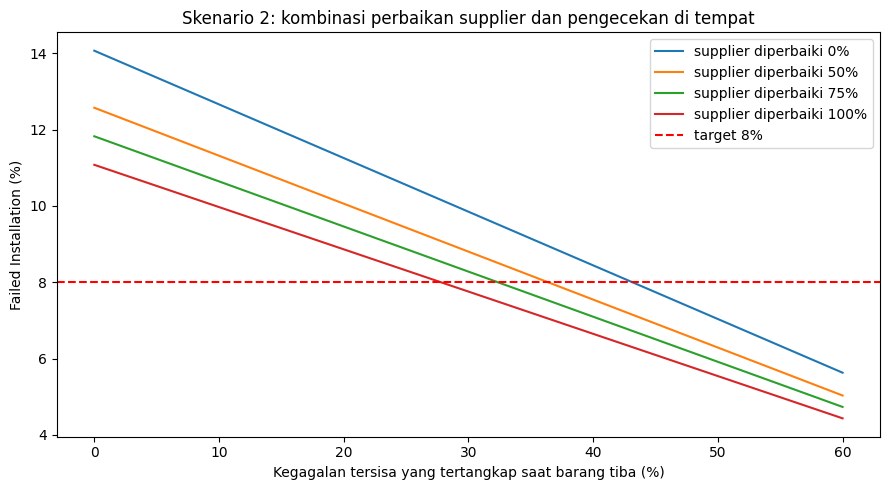


KESIMPULAN OTOMATIS: bila supplier berisiko diperbaiki penuh, pengecekan di tempat harus menangkap minimal 29% dari kegagalan yang tersisa agar Failed Installation di bawah 8%.


In [92]:
def k_untuk_target(f_awal):
    """Tingkat deteksi minimal (dibulatkan ke atas, 1 poin) agar hasil akhir di bawah target."""
    if f_awal < TARGET:
        return 0.0
    k = math.ceil((1 - TARGET / f_awal) * 100) / 100
    while f_awal * (1 - k) >= TARGET - 0.0005:      # pastikan hasil akhir tampil di bawah 8,0%
        k += 0.01
    return k

print('Batas minimal deteksi di tempat agar Failed Installation < 8%:')
batas = pd.DataFrame({'Efektivitas supplier': [f'{e:.0%}' for e in [0, .5, .75, 1.0]],
                      'Failed Installation sebelum deteksi': [gagal_setelah(e) for e in [0, .5, .75, 1.0]]})
batas['Deteksi minimal (k)'] = batas['Failed Installation sebelum deteksi'].map(k_untuk_target)
batas['Hasil akhir'] = [gagal_setelah(e, k) for e, k in zip([0, .5, .75, 1.0], batas['Deteksi minimal (k)'])]
tp = batas.copy()
for c in ['Failed Installation sebelum deteksi', 'Hasil akhir']:
    tp[c] = tp[c].map('{:.2%}'.format)
tp['Deteksi minimal (k)'] = tp['Deteksi minimal (k)'].map('{:.0%}'.format)
print(tp.to_string(index=False))

EFF = [0, 0.5, 0.75, 1.0]
KK  = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
grid = pd.DataFrame({f'deteksi {int(k * 100)}%': [gagal_setelah(e, k) * 100 for e in EFF] for k in KK},
                    index=[f'supplier {int(e * 100)}%' for e in EFF])
print('\nFailed Installation (%) untuk tiap kombinasi (tanda v = di bawah 8%):')
print(grid.apply(lambda col: col.map(lambda x: f'{x:.1f} v' if x < TARGET * 100 else f'{x:.1f}')).to_string())

xs = np.linspace(0, 0.6, 61)
plt.figure(figsize=(9, 5))
for e in EFF:
    plt.plot(xs * 100, [gagal_setelah(e, k) * 100 for k in xs], label=f'supplier diperbaiki {int(e * 100)}%')
plt.axhline(TARGET * 100, linestyle='--', color='red', label='target 8%')
plt.xlabel('Kegagalan tersisa yang tertangkap saat barang tiba (%)')
plt.ylabel('Failed Installation (%)')
plt.title('Skenario 2: kombinasi perbaikan supplier dan pengecekan di tempat')
plt.legend(); plt.tight_layout(); plt.show()

k100 = k_untuk_target(gagal_setelah(1.0))
print(f'\nKESIMPULAN OTOMATIS: bila supplier berisiko diperbaiki penuh, pengecekan di tempat harus menangkap '
      f'minimal {k100:.0%} dari kegagalan yang tersisa agar Failed Installation di bawah 8%.')

**Kesimpulan:** Setelah supplier diperbaiki, sisa kegagalan sebagian besar Damaged Panel dan Missing Parts dari supplier lain, yang tidak bisa dicegah lewat supplier. Karena itu dibutuhkan tuas kedua: pemeriksaan saat barang tiba dengan perbaikan langsung (komponen pengganti dibawa tukang atau dikirim ulang sebelum perakitan). Tabel batas minimal menjawab seberapa efektif pemeriksaan itu harus berjalan, dan grafik memperlihatkan semua kombinasi. Semakin kecil efektivitas supplier, semakin besar deteksi yang dibutuhkan. Angka batas ini adalah syarat target, bukan prediksi hasil, karena data tidak mencatat pengecekan saat barang tiba.

## 5.4 Tuas C: sinkronkan perakitan dengan pengiriman (jeda 0 hari)

**Apa yang dicari:** Berapa banyak pesanan yang harus dijadwal ulang agar perakitan sama hari dengan pengiriman, berapa hari tunggu yang hilang, apakah tukang cukup, dan apakah jeda memengaruhi tingkat kegagalan.

**Metode:** (1) Sebaran jeda saat ini. (2) Tingkat kegagalan menurut jeda, diuji dengan chi-kuadrat dan ukuran efek Cramér V (hubungan dianggap berarti bila p di bawah 0,05 dan V minimal 0,02), untuk menguji apakah menyamakan hari saja menurunkan kegagalan. (3) Uji kapasitas: untuk tiap wilayah tukang dan hari pengiriman, bandingkan jumlah pesanan yang harus dirakit hari itu dengan kapasitas tukang (jumlah tukang di wilayah x pekerjaan per tukang per hari pada persentil ke-95 aktual). Dua versi dihitung: seluruh tukang wilayah tersedia (optimis) dan hanya tukang yang rata-rata aktif per hari (ketat).

In [93]:
# (1) Sebaran jeda
dist = (v2['gap_hari'].value_counts(normalize=True).sort_index() * 100).round(1)
print('Sebaran jeda kirim ke rakit (% pesanan):'); print(dist.to_string())
PERLU_JADWAL_ULANG = (v2['gap_hari'] > 0).sum()
HARI_TUNGGU = v2['gap_hari'].sum()
print(f'\nPesanan yang harus dijadwal ulang agar sama hari: {PERLU_JADWAL_ULANG:,} dari {len(v2):,} ({PERLU_JADWAL_ULANG / len(v2):.1%})')
print(f'Total hari tunggu pelanggan saat ini: {HARI_TUNGGU:,.0f} pesanan-hari (menjadi 0 pada skenario)')

# (2) Apakah jeda memengaruhi kegagalan? (uji chi-kuadrat + ukuran efek Cramer V)
from scipy.stats import chi2_contingency
per_gap = v2.groupby('gap_hari')['gagal'].agg(pesanan='size', gagal_rate='mean')
print('\nTingkat kegagalan menurut jeda:'); print((per_gap.assign(gagal_rate=lambda t: (t['gagal_rate'] * 100).round(2))).to_string())
tab_gap = pd.crosstab(v2['gap_hari'], v2['gagal'])
chi2_gap, P_GAP, _, _ = chi2_contingency(tab_gap)
V_GAP = np.sqrt(chi2_gap / (tab_gap.values.sum() * (min(tab_gap.shape) - 1)))
JEDA_BERPENGARUH = (P_GAP < 0.05) and (V_GAP >= 0.02)
print(f'uji chi-kuadrat jeda vs kegagalan: p = {P_GAP:.3f}, Cramer V = {V_GAP:.3f} '
      f'({"ada hubungan berarti" if JEDA_BERPENGARUH else "tidak ada hubungan berarti"})')

# (3) Uji kapasitas
v2['hari_kirim'] = v2['delivery_date'].dt.normalize()
v2['hari_rakit'] = v2['installation_date'].dt.normalize()
beban_aktual = v2.groupby(['installer_id', 'hari_rakit']).size()
P95_JOB = max(1, int(np.ceil(beban_aktual.quantile(0.95))))
print(f'\nPekerjaan per tukang per hari (aktual): rata-rata {beban_aktual.mean():.2f}, '
      f'persentil 95 = {P95_JOB}, maksimum {beban_aktual.max()}')

pool  = v2.groupby('wilayah_tukang')['installer_id'].nunique()
aktif = v2.groupby(['wilayah_tukang', 'hari_rakit'])['installer_id'].nunique().groupby('wilayah_tukang').mean()
butuh = (v2.groupby(['wilayah_tukang', 'hari_kirim']).size().rename('pekerjaan').reset_index())
butuh['kapasitas_optimis'] = butuh['wilayah_tukang'].map(pool) * P95_JOB
butuh['kapasitas_ketat']   = butuh['wilayah_tukang'].map(aktif).round().clip(lower=1) * P95_JOB
OVER_OPT = (butuh['pekerjaan'] > butuh['kapasitas_optimis']).mean()
OVER_KET = (butuh['pekerjaan'] > butuh['kapasitas_ketat']).mean()
print(f'Hari-wilayah yang melebihi kapasitas jika perakitan harus sama hari:')
print(f'  versi optimis (semua tukang wilayah tersedia): {OVER_OPT:.1%}')
print(f'  versi ketat (hanya tukang aktif rata-rata)   : {OVER_KET:.1%}')

p95_butuh = butuh.groupby('wilayah_tukang')['pekerjaan'].quantile(0.95)
tukang_perlu = np.ceil(p95_butuh / P95_JOB)
tambahan = (tukang_perlu - pool).clip(lower=0)
print(f'\nTambahan tukang agar 95% hari terlayani sama hari: {int(tambahan.sum())} orang '
      f'(dari {int(pool.sum()):,} tukang sekarang)')
print(tambahan[tambahan > 0].sort_values(ascending=False).head(5).to_string())

print(f'\nKESIMPULAN OTOMATIS: hanya {(v2["gap_hari"] == 0).mean():.1%} pesanan dirakit di hari pengiriman; '
      f'{PERLU_JADWAL_ULANG:,} pesanan harus dijadwal ulang. '
      + (f'Jeda tidak berhubungan berarti dengan kegagalan (p = {P_GAP:.3f}, V = {V_GAP:.3f}), jadi menyamakan hari SAJA tidak menurunkan kegagalan. '
         if not JEDA_BERPENGARUH else
         f'Jeda berhubungan dengan kegagalan (p = {P_GAP:.3f}, V = {V_GAP:.3f}), jadi sinkronisasi ikut membantu menurunkan kegagalan. ')
      + ('Kapasitas tukang mencukupi pada versi ketat.' if OVER_KET < 0.05
         else f'Kapasitas tukang BELUM mencukupi di {OVER_KET:.0%} hari-wilayah (versi ketat); perlu penambahan atau penjadwalan.'))

Sebaran jeda kirim ke rakit (% pesanan):
gap_hari
0    13.2
1    15.6
2    21.1
3    21.2
4    15.7
5     8.6
6     4.8

Pesanan yang harus dijadwal ulang agar sama hari: 172,722 dari 198,971 (86.8%)
Total hari tunggu pelanggan saat ini: 508,055 pesanan-hari (menjadi 0 pada skenario)

Tingkat kegagalan menurut jeda:
          pesanan  gagal_rate
gap_hari                     
0           26249       14.41
1           30964       14.32
2           41913       14.51
3           42133       14.66
4           31178       14.29
5           17050       14.50
6            9484       14.57
uji chi-kuadrat jeda vs kegagalan: p = 0.825, Cramer V = 0.004 (tidak ada hubungan berarti)

Pekerjaan per tukang per hari (aktual): rata-rata 1.18, persentil 95 = 2, maksimum 6
Hari-wilayah yang melebihi kapasitas jika perakitan harus sama hari:
  versi optimis (semua tukang wilayah tersedia): 0.0%
  versi ketat (hanya tukang aktif rata-rata)   : 0.7%

Tambahan tukang agar 95% hari terlayani sama hari: 0 ora

**Kesimpulan:** Menyamakan hari perakitan dengan pengiriman adalah perbaikan jadwal untuk seluruh pesanan, bukan untuk segmen tertentu (keterlambatan merata di semua toko, kategori, supplier, dan tukang, lihat 3.2). Uji chi-kuadrat pada tabel kegagalan menurut jeda menunjukkan apakah jeda memengaruhi kegagalan: bila tidak signifikan atau Cramér V di bawah 0,02, sinkronisasi saja tidak menurunkan Failed Installation. Manfaat utamanya adalah mempersingkat waktu tunggu pelanggan dan membuat tuas B (pengecekan saat barang tiba) mungkin dijalankan. Uji kapasitas memberi dua batas, optimis dan ketat. Kebutuhan tukang tambahan dihitung dari beban puncak (persentil 95), dan angka itu perlu divalidasi dengan jadwal kerja sebenarnya karena data tidak memuat hari libur atau cuti tukang.

## 5.5 Dampak Skenario 2 pada retur dan biaya

**Apa yang dicari:** Berapa kegagalan, retur, refund, dan nilai barang yang bisa dihindari pada tiga paket Skenario 2.

**Metode:** Kegagalan dihindari = (baseline - skenario) x jumlah pesanan. Retur dihindari = kegagalan dihindari x cakupan retur (75%). Refund dihindari = retur dihindari x rata-rata refund retur Failed Installation, memakai **refund pulihan** (retur yang belum diproses tidak ikut dirata-ratakan). Biaya proses retur memakai benchmark 20% sampai 65% dari nilai barang.

In [94]:
ret = dfs['ret']
rf = ret.merge(d[['order_id', 'gagal', 'unit_price']], on='order_id', how='inner')
rf = rf[rf['gagal']]
REFUND_RATA   = rf['refund_amount'].mean()                     # NaN (belum diproses) diabaikan
RESTOCK_RATA  = rf['restocking_fee_amount'].mean()
NILAI_BARANG  = d.loc[d['gagal'] & (d['unit_price'] > 0), 'unit_price'].mean()

paket = [('Baseline', 0.0, 0.0),
         ('S2-a  supplier 100% saja', 1.0, 0.0),
         ('S2-b  supplier 100% + deteksi minimal', 1.0, k_untuk_target(gagal_setelah(1.0))),
         ('S2-c  supplier 75% + deteksi minimal', 0.75, k_untuk_target(gagal_setelah(0.75)))]

baris = []
for nama, e, k in paket:
    f = gagal_setelah(e, k)
    hindar = (BASE_FAIL - f) * N
    retur_hindar = hindar * COV
    baris.append({'Paket': nama, 'Failed Installation': f, 'Kegagalan dihindari': hindar,
                  'Tingkat retur dari kegagalan': f * COV, 'Retur dihindari': retur_hindar,
                  'Refund dihindari (Rp miliar)': retur_hindar * REFUND_RATA / 1e9,
                  'Biaya proses 20% (Rp miliar)': hindar * NILAI_BARANG * 0.20 / 1e9,
                  'Biaya proses 65% (Rp miliar)': hindar * NILAI_BARANG * 0.65 / 1e9})
tabel_skenario = pd.DataFrame(baris)
tp = tabel_skenario.copy()
tp['Failed Installation'] = tp['Failed Installation'].map('{:.2%}'.format)
tp['Tingkat retur dari kegagalan'] = tp['Tingkat retur dari kegagalan'].map('{:.2%}'.format)
tp['Kegagalan dihindari'] = tp['Kegagalan dihindari'].map('{:,.0f}'.format)
tp['Retur dihindari'] = tp['Retur dihindari'].map('{:,.0f}'.format)
for c in ['Refund dihindari (Rp miliar)', 'Biaya proses 20% (Rp miliar)', 'Biaya proses 65% (Rp miliar)']:
    tp[c] = tp[c].map('{:,.2f}'.format)
print(tp.T.to_string(header=False))

print(f'\nrata-rata refund retur Failed Installation (pulihan): Rp{REFUND_RATA:,.0f}')
print(f'rata-rata nilai barang pesanan gagal                : Rp{NILAI_BARANG:,.0f}')
print('Catatan: biaya proses 20%-65% adalah benchmark industri, bukan penghematan aktual Dekoruma. '
      'Refund dan retur hanya mencakup retur yang tercatat.')
print('\nKESIMPULAN OTOMATIS: paket S2-b menurunkan Failed Installation menjadi '
      f'{tabel_skenario.loc[2, "Failed Installation"]:.2%}, menghindari sekitar {tabel_skenario.loc[2, "Kegagalan dihindari"]:,.0f} kegagalan '
      f'dan {tabel_skenario.loc[2, "Retur dihindari"]:,.0f} retur, dengan refund yang dihindari sekitar Rp{tabel_skenario.loc[2, "Refund dihindari (Rp miliar)"]:,.2f} miliar.')

Paket                         Baseline  S2-a  supplier 100% saja  S2-b  supplier 100% + deteksi minimal  S2-c  supplier 75% + deteksi minimal
Failed Installation             14.07%                    11.08%                                  7.87%                                 7.92%
Kegagalan dihindari                  0                     6,120                                 12,692                                12,573
Tingkat retur dari kegagalan    10.56%                     8.31%                                  5.90%                                 5.94%
Retur dihindari                      0                     4,591                                  9,522                                 9,433
Refund dihindari (Rp miliar)      0.00                      9.74                                  20.20                                 20.01
Biaya proses 20% (Rp miliar)      0.00                      2.79                                   5.79                                  5.74
Biaya 

**Kesimpulan:** Tiga paket dibandingkan dengan baseline. Paket S2-a (supplier saja) menurunkan kegagalan tetapi belum menyentuh 8%. Paket S2-b dan S2-c menggabungkan perbaikan supplier dengan pengecekan di tempat dan tepat melewati target. Refund yang dihindari memakai refund pulihan, jadi nilainya tidak lagi terdistorsi refund ratusan juta atau negatif. Angka rupiah adalah estimasi skenario dengan asumsi cakupan retur 75% dan benchmark biaya, bukan penghematan aktual.

## 5.6 Ringkasan Skenario 2 dan rencana tindakan

**Apa yang dicari:** Tindakan apa yang perlu dijalankan, dengan target dan KPI yang terukur dari analisis di atas.

**Metode:** Susun tabel tindakan dari angka yang sudah dihitung (5.1 sampai 5.5), siap dipindah ke slide.

In [95]:
f_s2b = gagal_setelah(1.0, k_untuk_target(gagal_setelah(1.0)))
k_s2b = k_untuk_target(gagal_setelah(1.0))

rencana = pd.DataFrame([
    {'Tuas': 'A. Supplier berisiko',
     'Tindakan': 'Corrective action plan untuk supplier berisiko: checklist komponen, QC sebelum kirim, audit sampel, scorecard bulanan',
     'KPI': 'Missing Parts supplier berisiko',
     'Baseline': f'{M_RISK:.1%}', 'Target': f'turun ke sekitar {M_LAIN:.1%} (setara supplier lain)'},
    {'Tuas': 'B. Pengecekan saat barang tiba',
     'Tindakan': 'Tukang hadir saat pengiriman, memeriksa kelengkapan dan kerusakan, komponen pengganti dibawa atau dikirim ulang sebelum perakitan',
     'KPI': 'Kegagalan tersisa yang tertangkap sebelum perakitan',
     'Baseline': 'belum tercatat', 'Target': f'minimal {k_s2b:.0%} (batas minimal agar < 8%)'},
    {'Tuas': 'C. Sinkronisasi kirim dan rakit',
     'Tindakan': 'Booking slot perakitan saat pengiriman dijadwalkan, aturan sama hari untuk semua pesanan, eskalasi bila lebih dari 24 jam',
     'KPI': 'Dirakit di hari pengiriman',
     'Baseline': f'{(v2["gap_hari"] == 0).mean():.1%}', 'Target': '100% secara bertahap; tahap awal minimal 80% dalam 24 jam'},
    {'Tuas': 'D. Damaged Panel',
     'Tindakan': 'Protokol packing dan serah terima di rantai pengiriman, karena kerusakan tersebar merata di semua supplier, kategori, dan tukang',
     'KPI': 'Damaged Panel rate',
     'Baseline': f'{BASE_DAMAGED:.2%}', 'Target': 'dipantau mingguan; hasil gabungan tuas B menjadi penentu'},
    {'Tuas': 'Hasil gabungan',
     'Tindakan': 'Paket S2-b',
     'KPI': 'Failed Installation',
     'Baseline': f'{BASE_FAIL:.2%}', 'Target': f'{f_s2b:.2%} (di bawah 8%)'},
])
display(rencana)

,Tuas,Tindakan,KPI,Baseline,Target
0,A. Supplier berisiko,Corrective action plan untuk supplier berisiko...,Missing Parts supplier berisiko,31.4%,turun ke sekitar 6.1% (setara supplier lain)
1,B. Pengecekan saat barang tiba,"Tukang hadir saat pengiriman, memeriksa keleng...",Kegagalan tersisa yang tertangkap sebelum pera...,belum tercatat,minimal 29% (batas minimal agar < 8%)
2,C. Sinkronisasi kirim dan rakit,Booking slot perakitan saat pengiriman dijadwa...,Dirakit di hari pengiriman,13.2%,100% secara bertahap; tahap awal minimal 80% d...
3,D. Damaged Panel,Protokol packing dan serah terima di rantai pe...,Damaged Panel rate,4.99%,dipantau mingguan; hasil gabungan tuas B menja...
4,Hasil gabungan,Paket S2-b,Failed Installation,14.07%,7.87% (di bawah 8%)


**Kesimpulan:** Skenario 2 bisa mencapai Failed Installation di bawah 8% hanya jika supplier diperbaiki dan pemeriksaan di tempat berjalan dengan tingkat tangkap minimal yang dihitung di 5.3. Perbaikan supplier saja tidak cukup karena Damaged Panel tidak terkait supplier. Sinkronisasi jadwal kirim dan rakit memenuhi tujuan kedua (perakitan sama hari dengan pengiriman) dan menjadi syarat operasional pengecekan di tempat, tetapi bila uji di 5.4 menunjukkan jeda tidak berhubungan berarti dengan kegagalan, ia sendiri tidak menurunkan tingkat kegagalan. Kapasitas tukang perlu divalidasi sebelum aturan sama hari diwajibkan.

# BAB 6 — Visual dashboard

## 6.1 KPI utama

**Apa yang dicari:** Ringkasan indikator utama dalam satu tabel.

**Metode:** Hitung dari tabel `d` dan `valid_gap`.

In [96]:
kpi_summary = pd.DataFrame({
    'KPI': [
        'Failed Installation Rate',
        'Missing Parts Rate',
        'Damaged Panel Rate',
        'Installation <=24h',
        'Average Delivery-to-Installation (days)'
    ],
    'Value': [
        d['gagal'].mean() * 100,
        d['gagal_missing'].mean() * 100,
        d['gagal_damaged'].mean() * 100,
        baseline_24h * 100,
        valid_gap['gap_hari'].mean()
    ],
    'Unit': ['%', '%', '%', '%', 'days']
})
display(kpi_summary.round(2))

,KPI,Value,Unit
0,Failed Installation Rate,14.07,%
1,Missing Parts Rate,9.08,%
2,Damaged Panel Rate,4.99,%
3,Installation <=24h,28.75,%
4,Average Delivery-to-Installation (days),2.55,days


**Kesimpulan:** Failed Installation sekitar 14,1%, Missing Parts sekitar 9,1%, Damaged Panel sekitar 5,0%, instalasi dalam 24 jam sekitar 28,8%, dan rata-rata jeda kirim ke rakit 2,55 hari.

## 6.2 Missing Parts per supplier

**Apa yang dicari:** Supplier mana yang tertinggi.

**Metode:** Bar horizontal 12 supplier teratas (minimal 300 pesanan) dengan garis baseline.

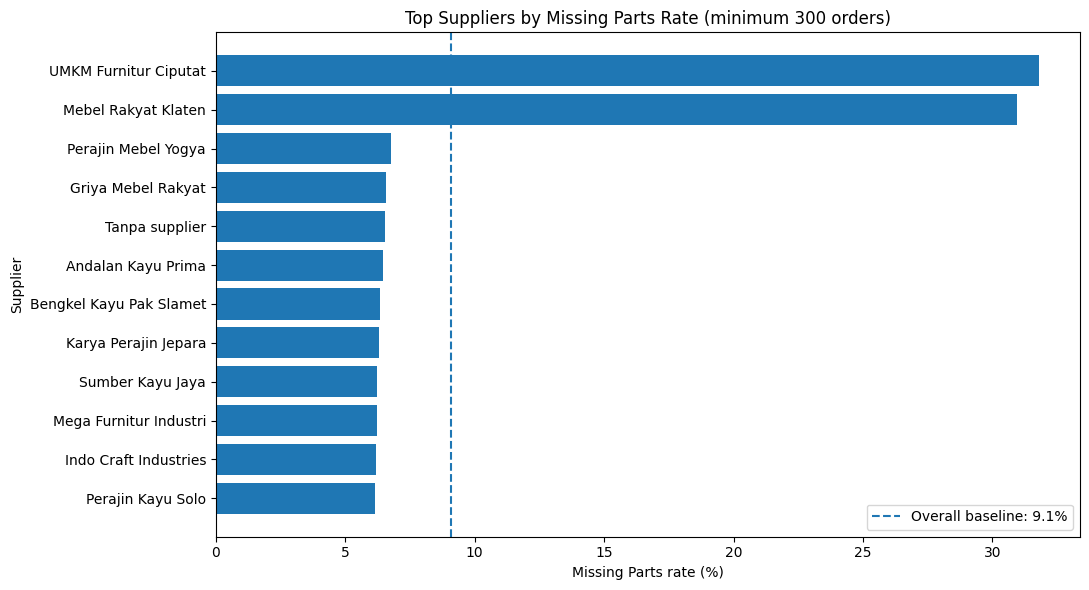

In [97]:
supplier_chart = (d.groupby(['supplier_id', 'supplier_name'])
    .agg(orders=('gagal_missing', 'size'),
         missing_rate=('gagal_missing', 'mean'))
    .query('orders >= 300')
    .reset_index()
    .sort_values('missing_rate', ascending=False)
    .head(12)
    .sort_values('missing_rate'))

plt.figure(figsize=(11, 6))
plt.barh(supplier_chart['supplier_name'], supplier_chart['missing_rate'] * 100)
plt.axvline(d['gagal_missing'].mean() * 100, linestyle='--',
            label=f"Overall baseline: {d['gagal_missing'].mean():.1%}")
plt.xlabel('Missing Parts rate (%)')
plt.ylabel('Supplier')
plt.title('Top Suppliers by Missing Parts Rate (minimum 300 orders)')
plt.legend()
plt.tight_layout()
plt.show()

**Kesimpulan:** Dua supplier berisiko berada jauh di atas baseline dan supplier lain.

## 6.3 Komposisi hasil instalasi

**Apa yang dicari:** Komposisi Success, Missing Parts, dan Damaged Panel.

**Metode:** Bar jumlah pesanan per status.

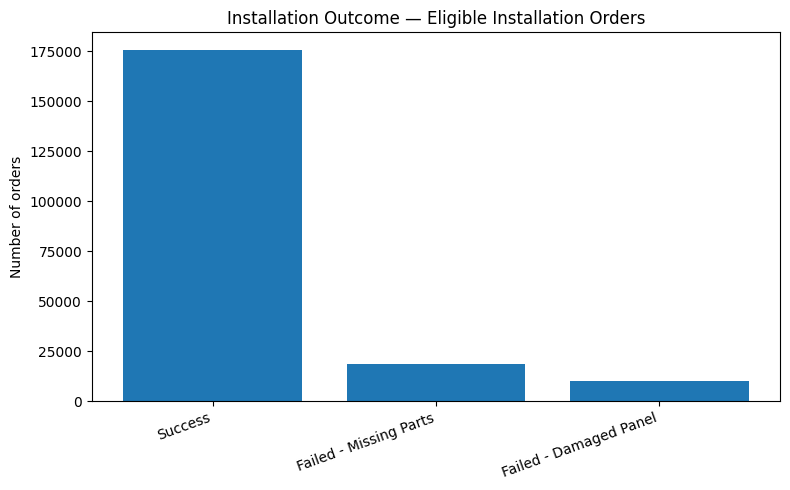

In [98]:
status_order = d['installation_status'].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(status_order.index, status_order.values)
plt.ylabel('Number of orders')
plt.title('Installation Outcome — Eligible Installation Orders')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

**Kesimpulan:** Mayoritas pesanan Success. Missing Parts lebih banyak daripada Damaged Panel.

## 6.4 Sebaran jeda kirim ke rakit

**Apa yang dicari:** Seberapa jauh jeda dari target 24 jam.

**Metode:** Histogram jam per hari dengan garis 24 jam.

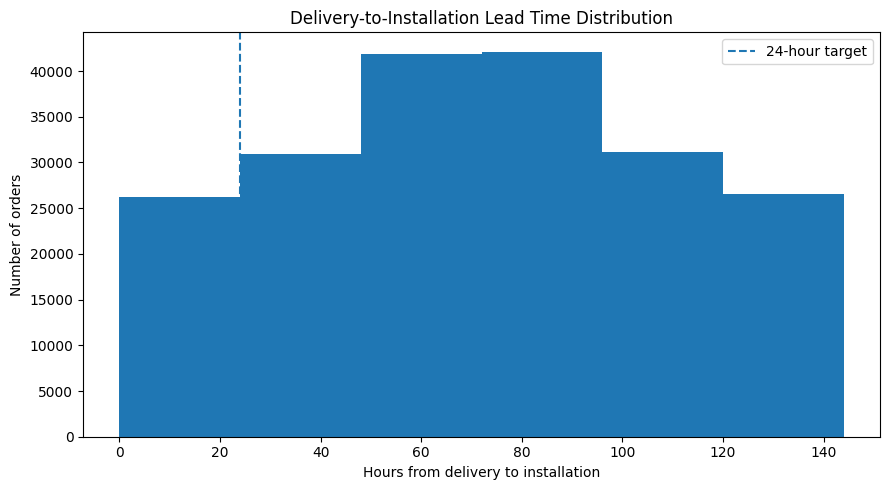

In [99]:
plt.figure(figsize=(9, 5))
bins = np.arange(0, min(valid_gap['gap_jam'].max(), 24*15) + 24, 24)
plt.hist(valid_gap['gap_jam'], bins=bins)
plt.axvline(24, linestyle='--', label='24-hour target')
plt.xlabel('Hours from delivery to installation')
plt.ylabel('Number of orders')
plt.title('Delivery-to-Installation Lead Time Distribution')
plt.legend()
plt.tight_layout()
plt.show()

**Kesimpulan:** Mayoritas pesanan menunggu lebih dari 24 jam, sehingga sinkronisasi jadwal mengubah seluruh distribusi, bukan hanya ekornya.

## 6.5 Kinerja SLA instalasi bulanan

**Apa yang dicari:** Apakah persentase instalasi dalam 24 jam berubah antar bulan.

**Metode:** Garis persen dalam 24 jam per bulan pengiriman, dibanding target 80%.

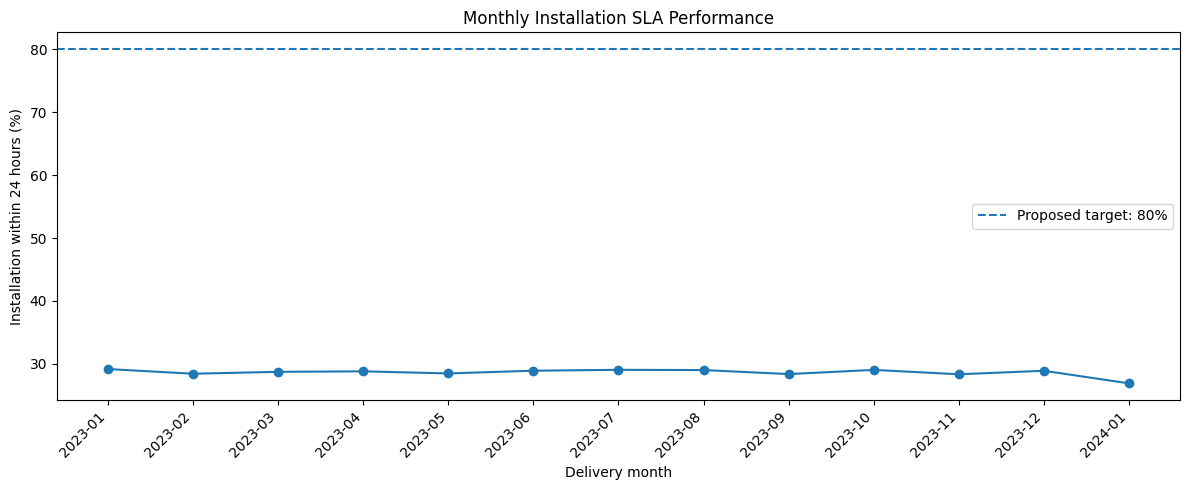

,delivery_month,orders,within_24h
0,2023-01,12295,29.19
1,2023-02,12945,28.45
2,2023-03,14503,28.75
3,2023-04,18608,28.83
4,2023-05,15566,28.50
5,2023-06,18876,28.93
6,2023-07,15407,29.07
7,2023-08,14573,29.03
8,2023-09,18833,28.40
9,2023-10,15454,29.06


In [100]:
monthly_logistics = valid_gap.copy()
monthly_logistics['delivery_month'] = monthly_logistics['delivery_date'].dt.to_period('M').astype(str)
monthly_logistics = (monthly_logistics.groupby('delivery_month')
    .agg(orders=('order_id', 'size'),
         within_24h=('gap_jam', lambda x: (x <= 24).mean() * 100))
    .reset_index())

plt.figure(figsize=(12, 5))
plt.plot(monthly_logistics['delivery_month'], monthly_logistics['within_24h'], marker='o')
plt.axhline(80, linestyle='--', label='Proposed target: 80%')
plt.ylabel('Installation within 24 hours (%)')
plt.xlabel('Delivery month')
plt.title('Monthly Installation SLA Performance')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()
display(monthly_logistics.round(2))

**Kesimpulan:** Rata-rata jeda stabil antar bulan (sekitar 2,53 sampai 2,57 hari) dan persentase dalam 24 jam berada jauh di bawah target 80%, jadi masalahnya sistemik.

## 6.6 Kontribusi channel

**Apa yang dicari:** Seberapa besar kontribusi tiap channel pada estimasi nilai barang.

**Metode:** Bar nilai barang per channel dari tabel penjualan `s` (Bab 3.7).

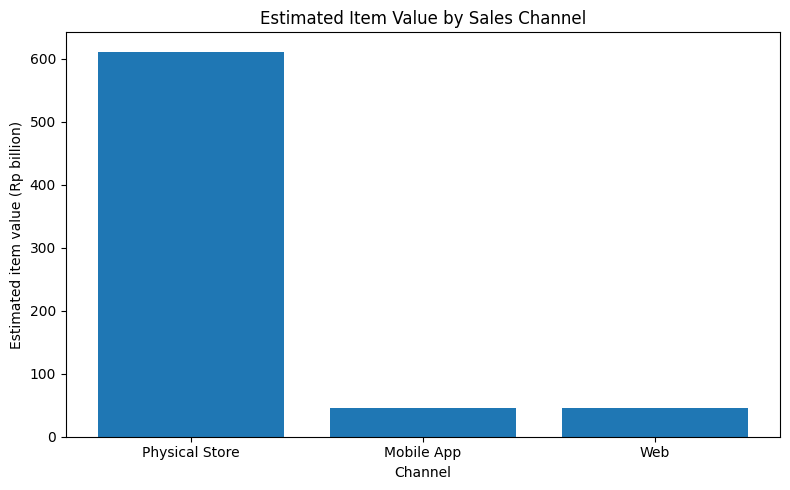

,orders,estimated_item_value
channel_type,,
Physical Store,280001,611414407632
Mobile App,20986,45843779427
Web,20773,44891398086


In [101]:
channel_chart = (s.groupby('channel_type')
    .agg(orders=('order_id', 'size'),
         estimated_item_value=('penjualan', 'sum'))
    .sort_values('estimated_item_value', ascending=False))

plt.figure(figsize=(8, 5))
plt.bar(channel_chart.index, channel_chart['estimated_item_value'] / 1e9)
plt.ylabel('Estimated item value (Rp billion)')
plt.xlabel('Channel')
plt.title('Estimated Item Value by Sales Channel')
plt.tight_layout()
plt.show()
display(channel_chart)

**Kesimpulan:** Toko fisik menyumbang sekitar 87% estimasi nilai barang, Mobile App 6,5%, dan Web 6,4%. Angka ini estimasi nilai barang, bukan net sales.

## 6.7 Proxy pembelian fisik sebelumnya

**Apa yang dicari:** Berapa nilai online yang terkait pembelian fisik menurut jendela waktu.

**Metode:** Bar nilai online per jendela 7, 30, 90, 180, 365 hari.

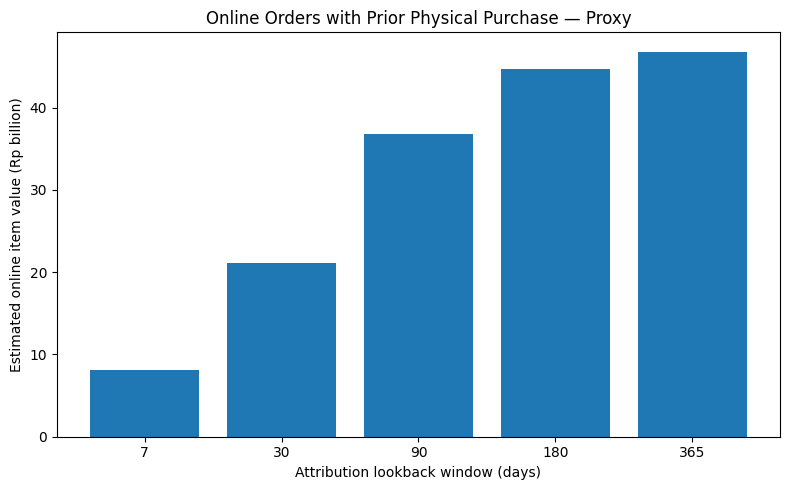

In [102]:
# `a` berisi online orders yang sudah ditautkan ke transaksi fisik terakhir sebelumnya
windows = [7, 30, 90, 180, 365]
window_values = []
for days in windows:
    mask = a['hari_sejak_fisik'].between(0, days, inclusive='both')
    window_values.append(a.loc[mask, 'penjualan'].sum() / 1e9)

plt.figure(figsize=(8, 5))
plt.bar([str(x) for x in windows], window_values)
plt.xlabel('Attribution lookback window (days)')
plt.ylabel('Estimated online item value (Rp billion)')
plt.title('Online Orders with Prior Physical Purchase — Proxy')
plt.tight_layout()
plt.show()

**Kesimpulan:** Nilai bertambah seiring jendela yang lebih panjang. Ini proxy, bukan bukti showrooming.

## 6.8 Status retur

**Apa yang dicari:** Komposisi retur, nilai refund, dan kepuasan per status.

**Metode:** Agregasi per `resolution_status`; nilai refund memakai refund pulihan.

,resolution_status,return_records,refund_value,avg_processing_days,avg_satisfaction
0,Diproses,3852,0.000000e+00,NaN,NaN
1,Ditolak,2072,0.000000e+00,4.02,NaN
2,Selesai,18919,4.217165e+10,4.00,3.78


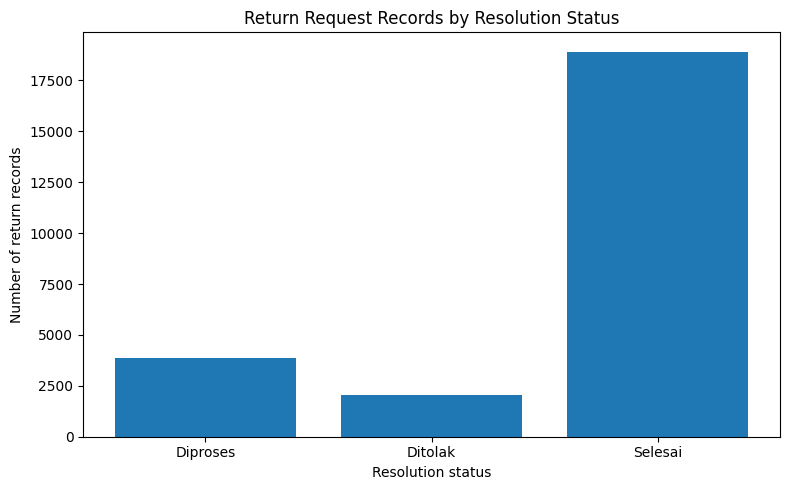

In [103]:
returns_valid = dfs['ret'].copy()
returns_valid['refund_amount'] = pd.to_numeric(returns_valid['refund_amount'], errors='coerce')
returns_valid['satisfaction_score'] = pd.to_numeric(returns_valid['satisfaction_score'], errors='coerce')

return_status = returns_valid.groupby('resolution_status').agg(
    return_records=('return_id', 'count'),
    refund_value=('refund_amount', 'sum'),
    avg_processing_days=('processing_days', 'mean'),
    avg_satisfaction=('satisfaction_score', 'mean')
).reset_index()
display(return_status.round(2))

plt.figure(figsize=(8, 5))
plt.bar(return_status['resolution_status'], return_status['return_records'])
plt.ylabel('Number of return records')
plt.xlabel('Resolution status')
plt.title('Return Request Records by Resolution Status')
plt.tight_layout()
plt.show()

**Kesimpulan:** Refund total per status kini tidak terdistorsi nilai ratusan juta atau negatif. Retur Ditolak bernilai 0 dan retur Diproses belum punya refund.

## 6.9 Simpan tabel dashboard

**Apa yang dicari:** Menyiapkan tabel agregat untuk dashboard.

**Metode:** Tulis tabel ke CSV di Drive, termasuk tabel Skenario 2.

In [104]:
# Simpan tabel agregat dashboard ke Google Drive
dashboard_tables = {
    'dashboard_kpi_overview.csv': kpi_summary,
    'dashboard_supplier_quality.csv': supplier_chart.reset_index(),
    'dashboard_monthly_logistics.csv': monthly_logistics,
    'dashboard_channel_sales.csv': channel_chart.reset_index(),
    'dashboard_return_status.csv': return_status,
    'dashboard_business_recommendations.csv': recommendations,
    'dashboard_scenario2.csv': tabel_skenario,
    'dashboard_scenario2_plan.csv': rencana
}

for filename, table in dashboard_tables.items():
    table.to_csv(FOLDER + filename, index=False)

print('Dashboard tables exported:')
for filename in dashboard_tables:
    print('-', filename)

Dashboard tables exported:
- dashboard_kpi_overview.csv
- dashboard_supplier_quality.csv
- dashboard_monthly_logistics.csv
- dashboard_channel_sales.csv
- dashboard_return_status.csv
- dashboard_business_recommendations.csv
- dashboard_scenario2.csv
- dashboard_scenario2_plan.csv


**Kesimpulan:** Delapan tabel dashboard tersimpan di Drive, termasuk `dashboard_scenario2.csv` dan `dashboard_scenario2_plan.csv`.

# BAB 7 — Kesimpulan akhir

## 7.1 Kesimpulan akhir

**Kualitas data**

- Nilai anomali `assembly_fee` (694 baris) dan `refund_amount` (60 baris: 14 negatif dan 46 bernilai Rp99,9 juta ke atas) dipulihkan dari data produk yang sama, bukan dijadikan NaN. Nilai asli tetap tersimpan.
- Uji akurasi (2.12) menunjukkan seberapa bisa dipercaya nilai pengganti. Gunakan nilai pengganti untuk ringkasan, dan nilai asli untuk audit.
- Anomali tanggal tetap ditandai, bukan diubah. Tabel retur hanya mencakup sebagian pesanan.

**Temuan operasional**

1. **Supplier:** Missing Parts terkonsentrasi di dua supplier berisiko, dan kegagalan tidak terkait tukang.
2. **Logistik:** jeda kirim ke rakit rata-rata 2,55 hari dan merata di semua segmen, jadi perbaikannya aturan jadwal untuk semua pesanan.
3. **Damaged Panel:** sekitar 5% dan tidak terkait supplier, kategori, atau tukang, jadi perlu workstream sendiri di rantai pengiriman.

**Skenario 2**

- Failed Installation baseline sekitar 14,1%. Memperbaiki dua supplier saja membawanya ke sekitar 11%, belum di bawah 8%.
- Agar di bawah 8% diperlukan tuas kedua: pengecekan saat barang tiba. Tingkat tangkap minimal yang dibutuhkan dihitung di 5.3 (sekitar seperempat sampai sepertiga dari kegagalan tersisa bila supplier diperbaiki penuh).
- Perakitan sama hari dengan pengiriman memenuhi tujuan kedua dan menjadi syarat operasional pengecekan di tempat. Apakah ia menurunkan tingkat kegagalan dengan sendirinya dijawab uji di 5.4 (bila tidak ada hubungan berarti, tidak), dan kapasitas tukang harus divalidasi.

**Catatan penyajian:** beri label `unit_price` sebagai estimasi nilai barang, bukan revenue. Tampilkan denominator pada setiap rate. Biaya retur 20% sampai 65% adalah benchmark, bukan biaya aktual. Angka rupiah dan retur di Bab 5 adalah skenario.

## Rekomendasi struktur dashboard

**Halaman 1 — Executive Overview:** total order, estimated merchandise value, Failed Installation Rate vs target <8%, installation within 24h, average delivery-to-installation gap, dan return coverage.

**Halaman 2 — Supplier Quality:** Missing Parts rate per supplier, jumlah order terpasang, kontribusi supplier terhadap total Missing Parts, supplier certification, serta filter kategori/region.

**Halaman 3 — Logistics & Installation:** rata-rata/median gap delivery-installation, % instalasi ≤24 jam, distribusi gap 0–6 hari, tren bulanan, dan breakdown status instalasi per toko/kategori/installer.

**Halaman 4 — Omnichannel:** penjualan dan order per channel, customer multi-channel, proxy online-after-physical dalam jendela 7/30/90 hari, serta catatan bahwa proxy bukan bukti kunjungan showroom.

**Halaman 5 — Data Quality & Returns:** missing values yang business-as-usual vs anomali, invalid date sequence, duplicate/key mismatch, kategori raw vs standardized, return coverage, dan refund outlier.

## Hal yang perlu diperbaiki sebelum presentasi

- Pastikan filter periode order **1 Jan–31 Des 2023** konsisten di seluruh visual; delivery/installation boleh terjadi pada Januari 2024 untuk order akhir Desember 2023.
- Jangan menyebut nilai `unit_price` sebagai revenue bersih. Beri label *estimasi nilai barang*.
- Jangan menyebut pembelian fisik sebelumnya sebagai showrooming yang terkonfirmasi. Dataset tidak memiliki event kunjungan DEC.
- Tampilkan denominator pada semua rate (khususnya Failed Installation: hanya order yang memang memerlukan layanan instalasi).
- Pisahkan retur yang tercatat dari seluruh kegagalan instalasi karena return table hanya parsial.
- Tambahkan target, baseline, owner, dan waktu evaluasi pada setiap rekomendasi agar insight bisa ditindaklanjuti.